In [ ]:
# ======================================================================
# STEP 1 - GOOGLE DRIVE + LIBRARY SETUP
# ======================================================================

from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")


# ======================================================================
# IMPORT LIBRARIES
# ======================================================================

import os
import json
import time
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

warnings.filterwarnings("ignore")


# ======================================================================
# REPRODUCIBILITY
# ======================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ======================================================================
# PROJECT PATHS
# ======================================================================

PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "TON_IOT_NETWORK_PROJECT"
)

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "DATA"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "MODELS"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "RESULTS"
)

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)


# ======================================================================
# ENVIRONMENT INFORMATION
# ======================================================================

print("=" * 70)
print("STEP 1 - ENVIRONMENT SETUP")
print("=" * 70)

print("\nTensorFlow version :", tf.__version__)
print("NumPy version      :", np.__version__)
print("Pandas version     :", pd.__version__)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nDrive mounted successfully.")
print("✓ STEP 1 COMPLETED SUCCESSFULLY")
print("=" * 70)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 1 - ENVIRONMENT SETUP

TensorFlow version : 2.20.0
NumPy version      : 2.1.3
Pandas version     : 2.2.3

Project directory:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT

Drive mounted successfully.
✓ STEP 1 COMPLETED SUCCESSFULLY


In [ ]:
# ================================================================
# STEP 2 - LOADING MULTI-CLASS DATASET
# ================================================================

import os
import pandas as pd
import numpy as np

print("=" * 70)
print("STEP 2 - LOADING MULTI-CLASS DATASET")
print("=" * 70)

# Correct dataset path
DATA_PATH = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/DATASET/Network_Balanced_Final.parquet"

print("\nDataset path:")
print(DATA_PATH)

print("\nFile exists:", os.path.exists(DATA_PATH))

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )

# Load dataset
df = pd.read_parquet(DATA_PATH)

print("\n✓ Dataset loaded successfully")

print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------
# TARGET CHECK
# ------------------------------------------------

TARGET_COLUMN = "type"

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' not found.\n"
        f"Available columns: {df.columns.tolist()}"
    )

print("\nTarget column:", TARGET_COLUMN)

print("\nNumber of classes:")
print(df[TARGET_COLUMN].nunique())

print("\nClass names:")
print(sorted(df[TARGET_COLUMN].unique()))

print("\nClass distribution:")
print(df[TARGET_COLUMN].value_counts())

print("\nClass distribution (%):")
print(
    (df[TARGET_COLUMN].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing values in target:")
print(df[TARGET_COLUMN].isna().sum())

print("\n" + "=" * 70)
print("STEP 2 COMPLETED SUCCESSFULLY")
print("=" * 70)

STEP 2 - LOADING MULTI-CLASS DATASET

Dataset path:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/DATASET/Network_Balanced_Final.parquet

File exists: True

✓ Dataset loaded successfully

Dataset shape:
(209340, 21)

Columns:
['src_port', 'dst_port', 'proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'label', 'type', 'http_response_body_len', 'http_status_code', 'http_request_body_len']

Target column: type

Number of classes:
9

Class names:
['backdoor', 'ddos', 'dos', 'injection', 'normal', 'password', 'ransomware', 'scanning', 'xss']

Class distribution:
type
scanning      23260
xss           23260
injection     23260
backdoor      23260
normal        23260
ransomware    23260
ddos          23260
dos           23260
password      23260
Name: count, dtype: int64

Class distribution (%):
type
scanning      11.11
xss           11.11
injection     11.11
b

In [ ]:
# ================================================================
# STEP 3 - LEAKAGE-SAFE TRAIN / VALIDATION / TEST SPLIT
# ================================================================

import numpy as np
import pandas as pd
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

print("=" * 70)
print("STEP 3 - LEAKAGE-SAFE DATA SPLIT AND PREPROCESSING")
print("=" * 70)

# ------------------------------------------------
# 1. DEFINE FEATURES AND TARGET
# ------------------------------------------------

TARGET_COL = "type"

# Categorical features used by Transformer models
CAT_COLS = [
    "proto",
    "service",
    "conn_state"
]

# Numerical features = all remaining input columns
FEATURE_COLS = [c for c in df.columns if c != TARGET_COL]

NUM_COLS = [c for c in FEATURE_COLS if c not in CAT_COLS]

print("\nTarget column:", TARGET_COL)

print("\nCategorical features:")
print(CAT_COLS)

print("\nNumerical features:")
print(NUM_COLS)

print("\nTotal input features:", len(FEATURE_COLS))
print("Categorical features:", len(CAT_COLS))
print("Numerical features:", len(NUM_COLS))


# ------------------------------------------------
# 2. SEPARATE X AND y
# ------------------------------------------------

X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

print("\nOriginal data:")
print("X shape:", X.shape)
print("y shape:", y.shape)


# ------------------------------------------------
# 3. ENCODE TARGET
# ------------------------------------------------

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

CLASS_NAMES = list(label_encoder.classes_)
NUM_CLASSES = len(CLASS_NAMES)

print("\nClasses:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}")

print("\nNumber of classes:", NUM_CLASSES)


# ------------------------------------------------
# 4. FIRST SPLIT
#    70% TRAIN
#    30% TEMPORARY
# ------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)


# ------------------------------------------------
# 5. SECOND SPLIT
#    15% VALIDATION
#    15% TEST
# ------------------------------------------------

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


print("\n" + "=" * 70)
print("DATA SPLIT")
print("=" * 70)

print("Training samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Test samples       :", len(X_test))

print("\nExpected approximately:")
print("Train      : 146,538")
print("Validation : 31,401")
print("Test       : 31,401")


# ------------------------------------------------
# 6. RESET INDICES
# ------------------------------------------------

X_train = X_train.reset_index(drop=True)
X_val   = X_val.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)

y_train = np.asarray(y_train)
y_val   = np.asarray(y_val)
y_test  = np.asarray(y_test)


# ================================================================
# 7. CATEGORICAL ENCODING
# ================================================================
# IMPORTANT:
# Encoder is FIT ONLY on TRAINING DATA.
# This prevents data leakage.

cat_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train_cat = cat_encoder.fit_transform(
    X_train[CAT_COLS]
)

X_val_cat = cat_encoder.transform(
    X_val[CAT_COLS]
)

X_test_cat = cat_encoder.transform(
    X_test[CAT_COLS]
)

# Shift values by +1 so that unknown category = 0
# and valid categories start from 1.
X_train_cat = X_train_cat.astype(np.int32) + 1
X_val_cat   = X_val_cat.astype(np.int32) + 1
X_test_cat  = X_test_cat.astype(np.int32) + 1


# ------------------------------------------------
# 8. CALCULATE CATEGORICAL CARDINALITIES
# ------------------------------------------------

CAT_CARDINALITIES = []

for i, col in enumerate(CAT_COLS):

    max_value = max(
        X_train_cat[:, i].max(),
        X_val_cat[:, i].max(),
        X_test_cat[:, i].max()
    )

    cardinality = int(max_value + 1)

    CAT_CARDINALITIES.append(cardinality)

print("\n" + "=" * 70)
print("CATEGORICAL ENCODING")
print("=" * 70)

for col, card in zip(CAT_COLS, CAT_CARDINALITIES):
    print(f"{col:15s}: {card} categories")


# ================================================================
# 9. NUMERICAL SCALING
# ================================================================
# IMPORTANT:
# StandardScaler is FIT ONLY on TRAINING DATA.

scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(
    X_train[NUM_COLS]
)

X_val_num_scaled = scaler.transform(
    X_val[NUM_COLS]
)

X_test_num_scaled = scaler.transform(
    X_test[NUM_COLS]
)


# ------------------------------------------------
# 10. CONVERT TYPES
# ------------------------------------------------

X_train_num_scaled = X_train_num_scaled.astype(np.float32)
X_val_num_scaled   = X_val_num_scaled.astype(np.float32)
X_test_num_scaled  = X_test_num_scaled.astype(np.float32)


# ================================================================
# 11. FINAL SHAPES
# ================================================================

print("\n" + "=" * 70)
print("FINAL PREPROCESSED SHAPES")
print("=" * 70)

print("\nTraining:")
print("Categorical :", X_train_cat.shape)
print("Numerical   :", X_train_num_scaled.shape)
print("Labels      :", y_train.shape)

print("\nValidation:")
print("Categorical :", X_val_cat.shape)
print("Numerical   :", X_val_num_scaled.shape)
print("Labels      :", y_val.shape)

print("\nTest:")
print("Categorical :", X_test_cat.shape)
print("Numerical   :", X_test_num_scaled.shape)
print("Labels      :", y_test.shape)


# ================================================================
# 12. SAVE PREPROCESSING OBJECTS
# ================================================================

PREPROCESS_DIR = os.path.join(PROJECT_DIR, "PREPROCESSING")
os.makedirs(PREPROCESS_DIR, exist_ok=True)

joblib.dump(
    cat_encoder,
    os.path.join(PREPROCESS_DIR, "categorical_encoder.pkl")
)

joblib.dump(
    scaler,
    os.path.join(PREPROCESS_DIR, "numerical_scaler.pkl")
)

joblib.dump(
    label_encoder,
    os.path.join(PREPROCESS_DIR, "label_encoder.pkl")
)


# ------------------------------------------------
# 13. SAVE PROCESSED DATA
# ------------------------------------------------

np.savez_compressed(
    os.path.join(PREPROCESS_DIR, "processed_multiclass_data.npz"),

    X_train_cat=X_train_cat,
    X_val_cat=X_val_cat,
    X_test_cat=X_test_cat,

    X_train_num_scaled=X_train_num_scaled,
    X_val_num_scaled=X_val_num_scaled,
    X_test_num_scaled=X_test_num_scaled,

    y_train=y_train,
    y_val=y_val,
    y_test=y_test
)


# ------------------------------------------------
# 14. SAVE CLASS INFORMATION
# ------------------------------------------------

class_info = {
    "class_names": CLASS_NAMES,
    "num_classes": NUM_CLASSES,
    "categorical_columns": CAT_COLS,
    "numerical_columns": NUM_COLS,
    "categorical_cardinalities": CAT_CARDINALITIES,
    "random_state": 42,
    "train_samples": len(X_train),
    "validation_samples": len(X_val),
    "test_samples": len(X_test)
}

joblib.dump(
    class_info,
    os.path.join(PREPROCESS_DIR, "class_info.pkl")
)


# ================================================================
# COMPLETION
# ================================================================

print("\n" + "=" * 70)
print("✓ STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nSaved preprocessing files:")
print("✓ categorical_encoder.pkl")
print("✓ numerical_scaler.pkl")
print("✓ label_encoder.pkl")
print("✓ processed_multiclass_data.npz")
print("✓ class_info.pkl")

print("\nIMPORTANT:")
print("✓ Split is stratified")
print("✓ Dataset is balanced")
print("✓ Encoder fitted only on training data")
print("✓ Scaler fitted only on training data")
print("✓ Test set remains untouched")
print("✓ Multi-class target preserved")

STEP 3 - LEAKAGE-SAFE DATA SPLIT AND PREPROCESSING

Target column: type

Categorical features:
['proto', 'service', 'conn_state']

Numerical features:
['class', 'tab_precision', 'tab_recall', 'tab_f1', 'tab_accuracy', 'ft_precision', 'ft_recall', 'ft_f1', 'ft_accuracy', 'win_margin', 'win_margin_percent', 'winner']

Total input features: 12
Categorical features: 3
Numerical features: 12


KeyError: 'type'

Tab Transformer

In [ ]:
# ======================================================================
# STEP 4 - TABTRANSFORMER TRAINING
# 9-CLASS MULTI-CLASS CLASSIFICATION
# ======================================================================

import os
import json
import time
import numpy as np
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print("=" * 70)
print("STEP 4 - TABTRANSFORMER TRAINING")
print("=" * 70)

print("\nTensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

# ----------------------------------------------------------------------
# 1. VERIFY DATA FROM STEP 3
# ----------------------------------------------------------------------

required_variables = [
    "X_train_cat",
    "X_val_cat",
    "X_train_num_scaled",
    "X_val_num_scaled",
    "y_train",
    "y_val",
    "CAT_CARDINALITIES",
    "NUM_CLASSES",
    "CLASS_NAMES",
    "CAT_COLS",
    "NUM_COLS"
]

print("\nChecking Step 3 variables...")

for var in required_variables:
    if var in globals():
        print(f"✓ {var} found")
    else:
        raise NameError(
            f"Required variable '{var}' not found. "
            "Please run Step 3 first."
        )


# ----------------------------------------------------------------------
# 2. DISPLAY DATA SHAPES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING DATA")
print("=" * 70)

print("Training categorical :", X_train_cat.shape)
print("Training numerical   :", X_train_num_scaled.shape)
print("Training labels      :", y_train.shape)

print("\nValidation categorical :", X_val_cat.shape)
print("Validation numerical   :", X_val_num_scaled.shape)
print("Validation labels      :", y_val.shape)

print("\nNumber of classes:", NUM_CLASSES)
print("Class names:", CLASS_NAMES)

print("\nCategorical cardinalities:")
for col, card in zip(CAT_COLS, CAT_CARDINALITIES):
    print(f"{col:15s}: {card}")


# ======================================================================
# 3. MODEL CONFIGURATION
# ======================================================================

EMBED_DIM = 32
NUM_HEADS = 4
FF_DIM = 64

NUM_TRANSFORMER_BLOCKS = 2

DROPOUT_RATE = 0.20

LEARNING_RATE = 0.001

BATCH_SIZE = 512
EPOCHS = 30

RANDOM_SEED = 42

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("\n" + "=" * 70)
print("MODEL CONFIGURATION")
print("=" * 70)

print("Embedding dimension :", EMBED_DIM)
print("Attention heads     :", NUM_HEADS)
print("Feed-forward dim    :", FF_DIM)
print("Transformer blocks  :", NUM_TRANSFORMER_BLOCKS)
print("Dropout             :", DROPOUT_RATE)
print("Learning rate       :", LEARNING_RATE)
print("Batch size          :", BATCH_SIZE)
print("Maximum epochs      :", EPOCHS)


# ======================================================================
# 4. TRANSFORMER BLOCK
# ======================================================================

class TransformerBlock(layers.Layer):

    def __init__(
        self,
        embed_dim,
        num_heads,
        ff_dim,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )

        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dropout(dropout),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)

    def call(self, inputs, training=None):

        # Self-attention
        attention_output = self.attention(
            inputs,
            inputs,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        x = self.norm1(
            inputs + attention_output
        )

        # Feed-forward network
        ffn_output = self.ffn(
            x,
            training=training
        )

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.norm2(
            x + ffn_output
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout": self.dropout_rate
        })

        return config


# ======================================================================
# 5. BUILD TABTRANSFORMER
# ======================================================================

def build_tab_transformer(
    categorical_cardinalities,
    num_numeric_features,
    num_classes
):

    # --------------------------------------------------------------
    # CATEGORICAL INPUTS
    # --------------------------------------------------------------

    categorical_inputs = []

    categorical_embeddings = []

    for i, cardinality in enumerate(
        categorical_cardinalities
    ):

        input_layer = layers.Input(
            shape=(1,),
            dtype=tf.int32,
            name=f"cat_input_{i}"
        )

        embedding_layer = layers.Embedding(
            input_dim=cardinality,
            output_dim=EMBED_DIM,
            name=f"cat_embedding_{i}"
        )

        embedded = embedding_layer(input_layer)

        # Shape:
        # (batch, 1, EMBED_DIM)

        categorical_inputs.append(input_layer)

        categorical_embeddings.append(embedded)


    # --------------------------------------------------------------
    # NUMERICAL INPUT
    # --------------------------------------------------------------

    numerical_input = layers.Input(
        shape=(num_numeric_features,),
        dtype=tf.float32,
        name="numerical_input"
    )

    # Convert numerical features into a single token
    numerical_token = layers.Dense(
        EMBED_DIM,
        activation="gelu",
        name="numerical_projection"
    )(numerical_input)

    numerical_token = layers.Reshape(
        (1, EMBED_DIM),
        name="numerical_token"
    )(numerical_token)


    # --------------------------------------------------------------
    # COMBINE CATEGORICAL + NUMERICAL TOKENS
    # --------------------------------------------------------------

    tokens = layers.Concatenate(
        axis=1,
        name="feature_tokens"
    )(
        categorical_embeddings +
        [numerical_token]
    )

    # Number of tokens:
    # 3 categorical + 1 numerical = 4


    # --------------------------------------------------------------
    # TRANSFORMER BLOCKS
    # --------------------------------------------------------------

    x = tokens

    for i in range(NUM_TRANSFORMER_BLOCKS):

        x = TransformerBlock(
            embed_dim=EMBED_DIM,
            num_heads=NUM_HEADS,
            ff_dim=FF_DIM,
            dropout=DROPOUT_RATE,
            name=f"transformer_block_{i+1}"
        )(x)


    # --------------------------------------------------------------
    # CLASSIFICATION HEAD
    # --------------------------------------------------------------

    x = layers.GlobalAveragePooling1D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        64,
        activation="gelu",
        name="classifier_dense"
    )(x)

    x = layers.Dropout(
        DROPOUT_RATE,
        name="classifier_dropout"
    )(x)

    output = layers.Dense(
        num_classes,
        activation="softmax",
        name="class_output"
    )(x)


    # --------------------------------------------------------------
    # FINAL MODEL
    # --------------------------------------------------------------

    model = keras.Model(
        inputs=categorical_inputs + [numerical_input],
        outputs=output,
        name="TabTransformer_Multiclass"
    )

    return model


# ======================================================================
# 6. CREATE MODEL
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING TABTRANSFORMER")
print("=" * 70)

tab_model = build_tab_transformer(
    categorical_cardinalities=CAT_CARDINALITIES,
    num_numeric_features=len(NUM_COLS),
    num_classes=NUM_CLASSES
)


# ----------------------------------------------------------------------
# IMPORTANT:
# Build the model before saving/loading weights.
# ----------------------------------------------------------------------

dummy_cat = [
    X_train_cat[:1, i:i+1]
    for i in range(X_train_cat.shape[1])
]

dummy_num = X_train_num_scaled[:1]

_ = tab_model(
    dummy_cat + [dummy_num],
    training=False
)


print("\n✓ TabTransformer built successfully")

print("\nModel summary:")
tab_model.summary()


# ======================================================================
# 7. COMPILE MODEL
# ======================================================================

tab_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)


print("\n✓ Model compiled successfully")


# ======================================================================
# 8. PREPARE MODEL INPUTS
# ======================================================================

train_inputs = [
    X_train_cat[:, i:i+1]
    for i in range(X_train_cat.shape[1])
]

train_inputs.append(
    X_train_num_scaled
)


val_inputs = [
    X_val_cat[:, i:i+1]
    for i in range(X_val_cat.shape[1])
]

val_inputs.append(
    X_val_num_scaled
)


print("\nTraining inputs:")

for i, inp in enumerate(train_inputs):

    if i < len(CAT_COLS):
        print(
            f"{CAT_COLS[i]:15s}: {inp.shape}"
        )
    else:
        print(
            f"{'numerical':15s}: {inp.shape}"
        )


# ======================================================================
# 9. CREATE MODEL DIRECTORY
# ======================================================================

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "MODELS"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "RESULTS"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)


# IMPORTANT:
# Save weights only.
# This avoids .keras Lambda/custom-layer serialization problems.

TAB_WEIGHTS_PATH = os.path.join(
    MODEL_DIR,
    "tab_transformer_multiclass_best.weights.h5"
)

TAB_HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "tab_transformer_multiclass_training_history.json"
)


print("\nModel will be saved to:")
print(TAB_WEIGHTS_PATH)


# ======================================================================
# 10. CALLBACKS
# ======================================================================

checkpoint_callback = keras.callbacks.ModelCheckpoint(

    filepath=TAB_WEIGHTS_PATH,

    monitor="val_accuracy",

    mode="max",

    save_best_only=True,

    save_weights_only=True,

    verbose=1
)


early_stopping_callback = keras.callbacks.EarlyStopping(

    monitor="val_accuracy",

    mode="max",

    patience=7,

    restore_best_weights=False,

    verbose=1
)


reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1
)


# ======================================================================
# 11. TRAIN TABTRANSFORMER
# ======================================================================

print("\n" + "=" * 70)
print("STARTING TABTRANSFORMER TRAINING")
print("=" * 70)

print("\nTraining samples   :", len(y_train))
print("Validation samples :", len(y_val))
print("Number of classes  :", NUM_CLASSES)

start_time = time.time()


history = tab_model.fit(

    train_inputs,

    y_train,

    validation_data=(
        val_inputs,
        y_val
    ),

    epochs=EPOCHS,

    batch_size=BATCH_SIZE,

    callbacks=[
        checkpoint_callback,
        early_stopping_callback,
        reduce_lr_callback
    ],

    verbose=1
)


training_time = time.time() - start_time


# ======================================================================
# 12. TRAINING TIME
# ======================================================================

training_minutes = training_time / 60

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print(
    f"Total training time : {training_time:.2f} seconds"
)

print(
    f"Total training time : {training_minutes:.2f} minutes"
)


# ======================================================================
# 13. FIND BEST VALIDATION RESULT
# ======================================================================

history_dict = history.history

best_epoch = int(
    np.argmax(
        history_dict["val_accuracy"]
    )
) + 1

best_val_accuracy = float(
    np.max(
        history_dict["val_accuracy"]
    )
)

best_train_accuracy = float(
    history_dict["accuracy"][best_epoch - 1]
)

best_val_loss = float(
    history_dict["val_loss"][best_epoch - 1]
)


print("\n" + "=" * 70)
print("BEST VALIDATION RESULT")
print("=" * 70)

print("Best epoch        :", best_epoch)

print(
    f"Best train accuracy : {best_train_accuracy:.6f}"
)

print(
    f"Best validation accuracy : {best_val_accuracy:.6f}"
)

print(
    f"Best validation loss : {best_val_loss:.6f}"
)


# ======================================================================
# 14. SAVE TRAINING HISTORY
# ======================================================================

history_serializable = {
    key: [
        float(value)
        for value in values
    ]
    for key, values in history_dict.items()
}

history_serializable["best_epoch"] = best_epoch

history_serializable["best_val_accuracy"] = (
    best_val_accuracy
)

history_serializable["training_time_seconds"] = (
    float(training_time)
)

history_serializable["training_time_minutes"] = (
    float(training_minutes)
)

history_serializable["num_classes"] = NUM_CLASSES

history_serializable["class_names"] = CLASS_NAMES


with open(
    TAB_HISTORY_PATH,
    "w"
) as f:

    json.dump(
        history_serializable,
        f,
        indent=4
    )


# ======================================================================
# 15. SAVE MODEL ARCHITECTURE
# ======================================================================

TAB_ARCHITECTURE_PATH = os.path.join(
    MODEL_DIR,
    "tab_transformer_multiclass_architecture.json"
)

with open(
    TAB_ARCHITECTURE_PATH,
    "w"
) as f:

    f.write(
        tab_model.to_json()
    )


# ======================================================================
# 16. CHECK BEST WEIGHTS
# ======================================================================

print("\n" + "=" * 70)
print("SAVED FILES")
print("=" * 70)

if os.path.exists(TAB_WEIGHTS_PATH):

    file_size_mb = (
        os.path.getsize(TAB_WEIGHTS_PATH)
        / (1024 * 1024)
    )

    print("✓ Best model weights:")
    print(TAB_WEIGHTS_PATH)

    print(
        f"  File size: {file_size_mb:.2f} MB"
    )

else:

    print("❌ Best weights file was not created.")


if os.path.exists(TAB_HISTORY_PATH):

    print("\n✓ Training history:")
    print(TAB_HISTORY_PATH)


if os.path.exists(TAB_ARCHITECTURE_PATH):

    print("\n✓ Model architecture:")
    print(TAB_ARCHITECTURE_PATH)


# ======================================================================
# 17. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("✓ STEP 4 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nTABTRANSFORMER")
print("-" * 40)

print("Task              : Multi-class classification")
print("Number of classes :", NUM_CLASSES)
print("Classes           :", CLASS_NAMES)

print("\nInput features:")
print("Categorical       :", len(CAT_COLS))
print("Numerical         :", len(NUM_COLS))
print("Total             :", len(CAT_COLS) + len(NUM_COLS))

print("\nTraining:")
print("Epochs completed  :", len(history_dict["loss"]))
print("Best epoch        :", best_epoch)
print(
    f"Best val accuracy : {best_val_accuracy:.6f}"
)

print(
    f"Training time     : {training_minutes:.2f} minutes"
)

print("\n✓ Best weights saved")
print("✓ Training history saved")
print("✓ Architecture saved")

print("\nIMPORTANT:")
print("✓ Test set was NOT used")
print("✓ No SMOTE was used")
print("✓ No test-set preprocessing was fitted")
print("✓ Model uses 9-class softmax output")
print("✓ Weights are saved separately for Step 8 evaluation")

STEP 4 - TABTRANSFORMER TRAINING

TensorFlow version: 2.20.0
Keras version: 3.13.2

Checking Step 3 variables...
✓ X_train_cat found
✓ X_val_cat found
✓ X_train_num_scaled found
✓ X_val_num_scaled found
✓ y_train found
✓ y_val found
✓ CAT_CARDINALITIES found
✓ NUM_CLASSES found
✓ CLASS_NAMES found
✓ CAT_COLS found
✓ NUM_COLS found

TRAINING DATA
Training categorical : (146538, 3)
Training numerical   : (146538, 17)
Training labels      : (146538,)

Validation categorical : (31401, 3)
Validation numerical   : (31401, 17)
Validation labels      : (31401,)

Number of classes: 9
Class names: ['backdoor', 'ddos', 'dos', 'injection', 'normal', 'password', 'ransomware', 'scanning', 'xss']

Categorical cardinalities:
proto          : 4
service        : 17
conn_state     : 14

MODEL CONFIGURATION
Embedding dimension : 32
Attention heads     : 4
Feed-forward dim    : 64
Transformer blocks  : 2
Dropout             : 0.2
Learning rate       : 0.001
Batch size          : 512
Maximum epochs      : 3

Model: "TabTransformer_Multiclass"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ numerical_input     │ (None, 17)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_input_0         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_input_1         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_input_2         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numerical_projecti… │ (None, 32)        │        576 │ numerical_input[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_embedding_0     │ (None, 1, 32)     │        128 │ cat_input_0[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_embedding_1     │ (None, 1, 32)     │        544 │ cat_input_1[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_embedding_2     │ (None, 1, 32)     │        448 │ cat_input_2[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numerical_token     │ (None, 1, 32)     │          0 │ numerical_projec… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_tokens      │ (None, 4, 32)     │          0 │ cat_embedding_0[… │
│ (Concatenate)       │                   │            │ cat_embedding_1[… │
│                     │                   │            │ cat_embedding_2[… │
│                     │                   │            │ numerical_token[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_1 │ (None, 4, 32)     │      8,544 │ feature_tokens[0… │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block_2 │ (None, 4, 32)     │      8,544 │ transformer_bloc… │
│ (TransformerBlock)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ transformer_bloc… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dense    │ (None, 64)        │      2,112 │ global_average_p… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier_dropout  │ (None, 64)        │          0 │ classifier_dense… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 9)         │        585 │ classifier_dropo… │
│ (Dense)             │                   │            │                 

 Total params: 21,481 (83.91 KB)

 Trainable params: 21,481 (83.91 KB)

 Non-trainable params: 0 (0.00 B)


✓ Model compiled successfully

Training inputs:
proto          : (146538, 1)
service        : (146538, 1)
conn_state     : (146538, 1)
numerical      : (146538, 17)

Model will be saved to:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/tab_transformer_multiclass_best.weights.h5

STARTING TABTRANSFORMER TRAINING

Training samples   : 146538
Validation samples : 31401
Number of classes  : 9
Epoch 1/30
286/287 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6944 - loss: 0.8819
Epoch 1: val_accuracy improved from None to 0.80650, saving model to /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/tab_transformer_multiclass_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/tab_transformer_multiclass_best.weights.h5
287/287 ━━━━━━━━━━━━━━━━━━━━ 27s 66ms/step - accuracy: 0.7539 - loss: 0.6363 - val_accuracy: 0.8065 - val_loss: 0.4783 - learning_rate: 0.0010
Epoch 2/30
286/287 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7999

FT-Transformer Training

In [ ]:
# ======================================================================
# STEP 5 - FT-TRANSFORMER TRAINING
# Multi-Class Classification - TON-IoT Network Dataset
# ======================================================================

import os
import json
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("=" * 70)
print("STEP 5 - FT-TRANSFORMER TRAINING")
print("=" * 70)

print("\nTensorFlow version:", tf.__version__)
print("Keras version     :", keras.__version__)

# ======================================================================
# 1. CHECK STEP 3 VARIABLES
# ======================================================================

print("\n" + "=" * 70)
print("CHECKING STEP 3 VARIABLES")
print("=" * 70)

required_variables = [
    "X_train_cat",
    "X_val_cat",
    "X_train_num_scaled",
    "X_val_num_scaled",
    "y_train",
    "y_val",
    "CAT_CARDINALITIES",
    "NUM_CLASSES",
    "CLASS_NAMES",
    "CAT_COLS",
    "NUM_COLS"
]

missing_variables = []

for var in required_variables:
    if var in globals():
        print(f"✓ {var} found")
    else:
        print(f"✗ {var} NOT found")
        missing_variables.append(var)

if missing_variables:
    raise RuntimeError(
        "Missing Step 3 variables: " + ", ".join(missing_variables)
    )

# ======================================================================
# 2. CONVERT DATA TO CORRECT TYPES
# ======================================================================

X_train_cat = np.asarray(X_train_cat, dtype=np.int32)
X_val_cat = np.asarray(X_val_cat, dtype=np.int32)

X_train_num_scaled = np.asarray(
    X_train_num_scaled,
    dtype=np.float32
)

X_val_num_scaled = np.asarray(
    X_val_num_scaled,
    dtype=np.float32
)

y_train = np.asarray(y_train, dtype=np.int32)
y_val = np.asarray(y_val, dtype=np.int32)

# ======================================================================
# 3. BASIC INFORMATION
# ======================================================================

NUM_CATEGORICAL = X_train_cat.shape[1]
NUM_NUMERICAL = X_train_num_scaled.shape[1]

print("\n" + "=" * 70)
print("TRAINING DATA")
print("=" * 70)

print("Training categorical :", X_train_cat.shape)
print("Training numerical   :", X_train_num_scaled.shape)
print("Training labels      :", y_train.shape)

print("\nValidation categorical :", X_val_cat.shape)
print("Validation numerical   :", X_val_num_scaled.shape)
print("Validation labels      :", y_val.shape)

print("\nNumber of classes:", NUM_CLASSES)
print("Class names:", CLASS_NAMES)

print("\nCategorical cardinalities:")

for i, col in enumerate(CAT_COLS):
    print(
        f"{col:<15}: {CAT_CARDINALITIES[i]}"
    )

# ======================================================================
# 4. MODEL CONFIGURATION
# ======================================================================

EMBED_DIM = 32
NUM_HEADS = 4
FF_DIM = 64
NUM_TRANSFORMER_BLOCKS = 2
DROPOUT = 0.2
LEARNING_RATE = 0.001
BATCH_SIZE = 512
MAX_EPOCHS = 30

print("\n" + "=" * 70)
print("FT-TRANSFORMER CONFIGURATION")
print("=" * 70)

print("Embedding dimension :", EMBED_DIM)
print("Attention heads     :", NUM_HEADS)
print("Feed-forward dim    :", FF_DIM)
print("Transformer blocks  :", NUM_TRANSFORMER_BLOCKS)
print("Dropout             :", DROPOUT)
print("Learning rate       :", LEARNING_RATE)
print("Batch size          :", BATCH_SIZE)
print("Maximum epochs      :", MAX_EPOCHS)

# ======================================================================
# 5. FT-TRANSFORMER BLOCK
# ======================================================================
#
# No Lambda layers are used.
# This makes the architecture easier to rebuild for Step 8.
#
# Each transformer block:
#
# LayerNorm
#     ↓
# Multi-Head Self Attention
#     ↓
# Residual connection
#     ↓
# LayerNorm
#     ↓
# Feed Forward Network
#     ↓
# Residual connection
#
# ======================================================================

def ft_transformer_block(
    x,
    embed_dim,
    num_heads,
    ff_dim,
    dropout,
    block_id
):

    # --------------------------------------------------------------
    # Self-attention sub-layer
    # --------------------------------------------------------------

    attention_norm = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"ft_block_{block_id}_attention_norm"
    )(x)

    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=dropout,
        name=f"ft_block_{block_id}_mha"
    )(
        attention_norm,
        attention_norm
    )

    attention_output = layers.Dropout(
        dropout,
        name=f"ft_block_{block_id}_attention_dropout"
    )(attention_output)

    x = layers.Add(
        name=f"ft_block_{block_id}_attention_residual"
    )([x, attention_output])

    # --------------------------------------------------------------
    # Feed-forward sub-layer
    # --------------------------------------------------------------

    ffn_norm = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"ft_block_{block_id}_ffn_norm"
    )(x)

    ffn = layers.Dense(
        ff_dim,
        activation="gelu",
        name=f"ft_block_{block_id}_ffn_dense_1"
    )(ffn_norm)

    ffn = layers.Dropout(
        dropout,
        name=f"ft_block_{block_id}_ffn_dropout"
    )(ffn)

    ffn = layers.Dense(
        embed_dim,
        name=f"ft_block_{block_id}_ffn_dense_2"
    )(ffn)

    ffn = layers.Dropout(
        dropout,
        name=f"ft_block_{block_id}_ffn_output_dropout"
    )(ffn)

    x = layers.Add(
        name=f"ft_block_{block_id}_ffn_residual"
    )([x, ffn])

    return x


# ======================================================================
# 6. BUILD FT-TRANSFORMER
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING FT-TRANSFORMER")
print("=" * 70)

# --------------------------------------------------------------
# Categorical inputs
# --------------------------------------------------------------

categorical_inputs = []
categorical_tokens = []

for i, cardinality in enumerate(CAT_CARDINALITIES):

    cat_input = keras.Input(
        shape=(1,),
        dtype="int32",
        name=f"ft_cat_input_{i}"
    )

    cat_embedding = layers.Embedding(
        input_dim=int(cardinality),
        output_dim=EMBED_DIM,
        name=f"ft_cat_embedding_{i}"
    )(cat_input)

    categorical_inputs.append(cat_input)
    categorical_tokens.append(cat_embedding)


# --------------------------------------------------------------
# Numerical input
# --------------------------------------------------------------

numerical_input = keras.Input(
    shape=(NUM_NUMERICAL,),
    dtype="float32",
    name="ft_numerical_input"
)

# Each numerical feature becomes one token.
#
# Input:
#     (batch, 17)
#
# Reshape:
#     (batch, 17, 1)
#
# Dense:
#     (batch, 17, 32)

numerical_reshaped = layers.Reshape(
    (NUM_NUMERICAL, 1),
    name="ft_numerical_reshape"
)(numerical_input)

numerical_tokens = layers.Dense(
    EMBED_DIM,
    name="ft_numerical_tokenizer"
)(numerical_reshaped)


# --------------------------------------------------------------
# Combine categorical + numerical tokens
# --------------------------------------------------------------

feature_tokens = layers.Concatenate(
    axis=1,
    name="ft_feature_tokens"
)(
    categorical_tokens + [numerical_tokens]
)

print("\nTotal transformer tokens:",
      NUM_CATEGORICAL + NUM_NUMERICAL)

# --------------------------------------------------------------
# Transformer blocks
# --------------------------------------------------------------

x = feature_tokens

for block_id in range(1, NUM_TRANSFORMER_BLOCKS + 1):

    x = ft_transformer_block(
        x=x,
        embed_dim=EMBED_DIM,
        num_heads=NUM_HEADS,
        ff_dim=FF_DIM,
        dropout=DROPOUT,
        block_id=block_id
    )


x = layers.LayerNormalization(
    epsilon=1e-6,
    name="ft_final_layer_norm"
)(x)

x = layers.GlobalAveragePooling1D(
    name="ft_global_average_pooling"
)(x)

x = layers.Dense(
    64,
    activation="gelu",
    name="ft_classifier_dense"
)(x)

x = layers.Dropout(
    DROPOUT,
    name="ft_classifier_dropout"
)(x)

output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="ft_class_output"
)(x)


ft_model = keras.Model(
    inputs=categorical_inputs + [numerical_input],
    outputs=output,
    name="FTTransformer_Multiclass"
)


ft_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

print("\n✓ FT-Transformer built successfully")
print("\nModel summary:")

ft_model.summary()


MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "MODELS"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "RESULTS"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)


FT_WEIGHTS_PATH = os.path.join(
    MODEL_DIR,
    "ft_transformer_multiclass_best.weights.h5"
)

FT_ARCHITECTURE_PATH = os.path.join(
    MODEL_DIR,
    "ft_transformer_multiclass_architecture.json"
)

FT_HISTORY_PATH = os.path.join(
    RESULT_DIR,
    "ft_transformer_multiclass_training_history.json"
)


print("\n" + "=" * 70)
print("MODEL OUTPUT PATHS")
print("=" * 70)

print("Best weights:")
print(FT_WEIGHTS_PATH)

print("\nArchitecture:")
print(FT_ARCHITECTURE_PATH)

print("\nTraining history:")
print(FT_HISTORY_PATH)


architecture_config = {
    "model_name": "FTTransformer_Multiclass",
    "task": "Multi-class classification",
    "num_classes": int(NUM_CLASSES),
    "class_names": list(CLASS_NAMES),
    "categorical_features": list(CAT_COLS),
    "numerical_features": list(NUM_COLS),
    "categorical_cardinalities": [
        int(x) for x in CAT_CARDINALITIES
    ],
    "embedding_dimension": EMBED_DIM,
    "attention_heads": NUM_HEADS,
    "feed_forward_dimension": FF_DIM,
    "transformer_blocks": NUM_TRANSFORMER_BLOCKS,
    "dropout": DROPOUT,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "num_tokens": int(
        NUM_CATEGORICAL + NUM_NUMERICAL
    )
}

with open(
    FT_ARCHITECTURE_PATH,
    "w"
) as f:
    json.dump(
        architecture_config,
        f,
        indent=4
    )

print("\n✓ Architecture configuration saved")


checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=FT_WEIGHTS_PATH,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)


train_inputs = {
    f"ft_cat_input_{i}":
        X_train_cat[:, i:i+1]
    for i in range(NUM_CATEGORICAL)
}

train_inputs["ft_numerical_input"] = X_train_num_scaled


val_inputs = {
    f"ft_cat_input_{i}":
        X_val_cat[:, i:i+1]
    for i in range(NUM_CATEGORICAL)
}

val_inputs["ft_numerical_input"] = X_val_num_scaled


print("\n" + "=" * 70)
print("STARTING FT-TRANSFORMER TRAINING")
print("=" * 70)

print("\nTraining samples :", len(y_train))
print("Validation samples :", len(y_val))
print("Number of classes :", NUM_CLASSES)

print("\nTest set is NOT used during training.")

start_time = time.time()

history = ft_model.fit(
    train_inputs,
    y_train,

    validation_data=(
        val_inputs,
        y_val
    ),

    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,

    callbacks=[
        checkpoint_callback,
        early_stopping_callback,
        reduce_lr_callback
    ],

    verbose=1
)

training_time = time.time() - start_time


# ======================================================================
# 15. SAVE TRAINING HISTORY
# ======================================================================

history_data = {
    key: [
        float(value)
        for value in values
    ]
    for key, values in history.history.items()
}

history_data["training_time_seconds"] = float(
    training_time
)

history_data["training_time_minutes"] = float(
    training_time / 60
)

with open(
    FT_HISTORY_PATH,
    "w"
) as f:
    json.dump(
        history_data,
        f,
        indent=4
    )


# ======================================================================
# 16. BEST TRAINING RESULTS
# ======================================================================

best_epoch = (
    int(
        np.argmax(
            history.history["val_accuracy"]
        )
    ) + 1
)

best_train_accuracy = (
    history.history["accuracy"][best_epoch - 1]
)

best_val_accuracy = (
    history.history["val_accuracy"][best_epoch - 1]
)

best_val_loss = (
    history.history["val_loss"][best_epoch - 1]
)


# ======================================================================
# 17. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("FT-TRANSFORMER TRAINING COMPLETED")
print("=" * 70)

print(f"\nBest epoch           : {best_epoch}")
print(
    f"Best train accuracy  : "
    f"{best_train_accuracy:.6f}"
)
print(
    f"Best validation accuracy : "
    f"{best_val_accuracy:.6f}"
)
print(
    f"Best validation loss : "
    f"{best_val_loss:.6f}"
)
print(
    f"Training time        : "
    f"{training_time / 60:.2f} minutes"
)


# ======================================================================
# 18. CHECK SAVED FILES
# ======================================================================

print("\n" + "=" * 70)
print("SAVED FILES")
print("=" * 70)

if os.path.exists(FT_WEIGHTS_PATH):
    size_mb = os.path.getsize(
        FT_WEIGHTS_PATH
    ) / (1024 * 1024)

    print(
        "\n✓ Best model weights:"
    )
    print(FT_WEIGHTS_PATH)
    print(
        f"  File size: {size_mb:.2f} MB"
    )
else:
    print("\n✗ Best weights were NOT found")


if os.path.exists(FT_HISTORY_PATH):
    print(
        "\n✓ Training history:"
    )
    print(FT_HISTORY_PATH)
else:
    print(
        "\n✗ Training history was NOT found"
    )


if os.path.exists(FT_ARCHITECTURE_PATH):
    print(
        "\n✓ Model architecture:"
    )
    print(FT_ARCHITECTURE_PATH)
else:
    print(
        "\n✗ Architecture file was NOT found"
    )


# ======================================================================
# 19. FINAL PROJECT INFORMATION
# ======================================================================

print("\n" + "=" * 70)
print("STEP 5 COMPLETED")
print("=" * 70)

print("\nFT-TRANSFORMER")
print("-" * 40)

print("Task           : Multi-class classification")
print("Number classes :", NUM_CLASSES)
print("Classes        :", CLASS_NAMES)

print("\nInput features:")
print("Categorical    :", NUM_CATEGORICAL)
print("Numerical      :", NUM_NUMERICAL)
print("Total          :", NUM_CATEGORICAL + NUM_NUMERICAL)

print("\nTraining:")
print("Epochs run     :", len(history.history["loss"]))
print("Best epoch     :", best_epoch)
print(
    "Best val acc   :",
    f"{best_val_accuracy:.6f}"
)

print("\n✓ Best weights saved")
print("✓ Training history saved")
print("✓ Architecture configuration saved")

print("\nIMPORTANT:")
print("✓ Test set was NOT used")
print("✓ No SMOTE was used")
print("✓ No test-set preprocessing was fitted")
print("✓ 9-class softmax output used")
print("✓ Same leakage-safe split as TabTransformer")
print("✓ Weights saved separately for Step 8 evaluation")

print("\n" + "=" * 70)

STEP 5 - FT-TRANSFORMER TRAINING

TensorFlow version: 2.20.0
Keras version     : 3.13.2

CHECKING STEP 3 VARIABLES
✓ X_train_cat found
✓ X_val_cat found
✓ X_train_num_scaled found
✓ X_val_num_scaled found
✓ y_train found
✓ y_val found
✓ CAT_CARDINALITIES found
✓ NUM_CLASSES found
✓ CLASS_NAMES found
✓ CAT_COLS found
✓ NUM_COLS found

TRAINING DATA
Training categorical : (146538, 3)
Training numerical   : (146538, 17)
Training labels      : (146538,)

Validation categorical : (31401, 3)
Validation numerical   : (31401, 17)
Validation labels      : (31401,)

Number of classes: 9
Class names: ['backdoor', 'ddos', 'dos', 'injection', 'normal', 'password', 'ransomware', 'scanning', 'xss']

Categorical cardinalities:
proto          : 4
service        : 17
conn_state     : 14

FT-TRANSFORMER CONFIGURATION
Embedding dimension : 32
Attention heads     : 4
Feed-forward dim    : 64
Transformer blocks  : 2
Dropout             : 0.2
Learning rate       : 0.001
Batch size          : 512
Maximum epoc

Model: "FTTransformer_Multiclass"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ft_numerical_input  │ (None, 17)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_cat_input_0      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_cat_input_1      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_cat_input_2      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_numerical_resha… │ (None, 17, 1)     │          0 │ ft_numerical_inp… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_cat_embedding_0  │ (None, 1, 32)     │        128 │ ft_cat_input_0[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_cat_embedding_1  │ (None, 1, 32)     │        544 │ ft_cat_input_1[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_cat_embedding_2  │ (None, 1, 32)     │        448 │ ft_cat_input_2[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_numerical_token… │ (None, 17, 32)    │         64 │ ft_numerical_res… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_feature_tokens   │ (None, 20, 32)    │          0 │ ft_cat_embedding… │
│ (Concatenate)       │                   │            │ ft_cat_embedding… │
│                     │                   │            │ ft_cat_embedding… │
│                     │                   │            │ ft_numerical_tok… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_block_1_attenti… │ (None, 20, 32)    │         64 │ ft_feature_token… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_block_1_mha      │ (None, 20, 32)    │      4,224 │ ft_block_1_atten… │
│ (MultiHeadAttentio… │                   │            │ ft_block_1_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_block_1_attenti… │ (None, 20, 32)    │          0 │ ft_block_1_mha[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_block_1_attenti… │ (None, 20, 32)    │          0 │ ft_feature_token… │
│ (Add)               │                   │            │ ft_block_1_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_block_1_ffn_norm │ (None, 20, 32)    │         64 │ ft_block_1_atten… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ft_block_1_ffn_den… │ (None, 20, 64)    │      2,112 │ ft_block_1_ffn_n… │
│ (Dense)             │                   │            │                 

 Total params: 21,033 (82.16 KB)

 Trainable params: 21,033 (82.16 KB)

 Non-trainable params: 0 (0.00 B)


MODEL OUTPUT PATHS
Best weights:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_multiclass_best.weights.h5

Architecture:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_multiclass_architecture.json

Training history:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/ft_transformer_multiclass_training_history.json

✓ Architecture configuration saved

STARTING FT-TRANSFORMER TRAINING

Training samples : 146538
Validation samples : 31401
Number of classes : 9

Test set is NOT used during training.
Epoch 1/30
287/287 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.5633 - loss: 1.2105
Epoch 1: val_accuracy improved from None to 0.76023, saving model to /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_multiclass_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_multiclass_best.weights.h5
287/287 ━━━━━━━━━━━━━━━━━━━━ 92s 288ms/step - accuracy: 0.6820 - l

FINAL TEST EVALUATION OF BOTH MODELS

In [ ]:
import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    cohen_kappa_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("STEP 6 - FINAL TEST SET EVALUATION")
print("=" * 70)

print("\nTensorFlow version :", tf.__version__)
print("Keras version      :", keras.__version__)


print("\n" + "=" * 70)
print("CHECKING TEST DATA")
print("=" * 70)

required_variables = [
    "X_test_cat",
    "X_test_num_scaled",
    "y_test",
    "CAT_CARDINALITIES",
    "NUM_CLASSES",
    "CLASS_NAMES",
    "CAT_COLS",
    "NUM_COLS",
    "PROJECT_DIR"
]

for var in required_variables:

    if var in globals():
        print(f"✓ {var} found")

    else:
        raise RuntimeError(
            f"Required variable '{var}' not found. "
            "Please run Steps 3-5 first."
        )



X_test_cat = np.asarray(
    X_test_cat,
    dtype=np.int32
)

X_test_num_scaled = np.asarray(
    X_test_num_scaled,
    dtype=np.float32
)

y_test = np.asarray(
    y_test,
    dtype=np.int32
)


print("\n" + "=" * 70)
print("TEST DATA")
print("=" * 70)

print("Test categorical :", X_test_cat.shape)
print("Test numerical   :", X_test_num_scaled.shape)
print("Test labels      :", y_test.shape)

print("Test samples     :", len(y_test))


print("\n" + "=" * 70)
print("CLASS INFORMATION")
print("=" * 70)

print("Number of classes :", NUM_CLASSES)
print("Class names       :", CLASS_NAMES)

print("\nTest class distribution:")

for i, class_name in enumerate(CLASS_NAMES):

    count = np.sum(y_test == i)

    print(
        f"{i:2d} : {class_name:<15s} {count}"
    )

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "MODELS"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "RESULTS"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)


TAB_WEIGHTS = os.path.join(
    MODEL_DIR,
    "tab_transformer_multiclass_best.weights.h5"
)

FT_WEIGHTS = os.path.join(
    MODEL_DIR,
    "ft_transformer_multiclass_best.weights.h5"
)


print("\n" + "=" * 70)
print("MODEL FILES")
print("=" * 70)

print("\nTabTransformer:")
print(TAB_WEIGHTS)

print("\nFT-Transformer:")
print(FT_WEIGHTS)


if not os.path.exists(TAB_WEIGHTS):
    raise FileNotFoundError(
        f"TabTransformer weights not found:\n{TAB_WEIGHTS}"
    )

if not os.path.exists(FT_WEIGHTS):
    raise FileNotFoundError(
        f"FT-Transformer weights not found:\n{FT_WEIGHTS}"
    )

print("\n✓ Both weight files found")


TAB_EMBED_DIM = 32
TAB_NUM_HEADS = 4
TAB_FF_DIM = 64
TAB_NUM_BLOCKS = 2
TAB_DROPOUT = 0.20


class TransformerBlock(layers.Layer):

    def __init__(
        self,
        embed_dim,
        num_heads,
        ff_dim,
        dropout=0.1,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout_rate = dropout

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )

        self.ffn = keras.Sequential([
            layers.Dense(
                ff_dim,
                activation="gelu"
            ),

            layers.Dropout(
                dropout
            ),

            layers.Dense(
                embed_dim
            )
        ])

        self.norm1 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.norm2 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.dropout1 = layers.Dropout(
            dropout
        )

        self.dropout2 = layers.Dropout(
            dropout
        )


    def call(
        self,
        inputs,
        training=None
    ):

        attention_output = self.attention(
            inputs,
            inputs,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        x = self.norm1(
            inputs + attention_output
        )

        ffn_output = self.ffn(
            x,
            training=training
        )

        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.norm2(
            x + ffn_output
        )


    def get_config(self):

        config = super().get_config()

        config.update({
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "dropout": self.dropout_rate
        })

        return config



def build_tab_transformer_step6():

    categorical_inputs = []

    categorical_embeddings = []


    for i, cardinality in enumerate(
        CAT_CARDINALITIES
    ):

        input_layer = layers.Input(
            shape=(1,),
            dtype=tf.int32,
            name=f"cat_input_{i}"
        )

        embedding_layer = layers.Embedding(
            input_dim=int(cardinality),
            output_dim=TAB_EMBED_DIM,
            name=f"cat_embedding_{i}"
        )

        embedded = embedding_layer(
            input_layer
        )

        categorical_inputs.append(
            input_layer
        )

        categorical_embeddings.append(
            embedded
        )


    numerical_input = layers.Input(
        shape=(len(NUM_COLS),),
        dtype=tf.float32,
        name="numerical_input"
    )


    numerical_token = layers.Dense(
        TAB_EMBED_DIM,
        activation="gelu",
        name="numerical_projection"
    )(
        numerical_input
    )

    numerical_token = layers.Reshape(
        (1, TAB_EMBED_DIM),
        name="numerical_token"
    )(
        numerical_token
    )


    # --------------------------------------------------------------
    # COMBINE TOKENS
    # --------------------------------------------------------------

    tokens = layers.Concatenate(
        axis=1,
        name="feature_tokens"
    )(
        categorical_embeddings +
        [numerical_token]
    )


    # --------------------------------------------------------------
    # TRANSFORMER BLOCKS
    # --------------------------------------------------------------

    x = tokens

    for i in range(
        TAB_NUM_BLOCKS
    ):

        x = TransformerBlock(
            embed_dim=TAB_EMBED_DIM,
            num_heads=TAB_NUM_HEADS,
            ff_dim=TAB_FF_DIM,
            dropout=TAB_DROPOUT,
            name=f"transformer_block_{i+1}"
        )(x)


    # --------------------------------------------------------------
    # CLASSIFICATION HEAD
    # --------------------------------------------------------------

    x = layers.GlobalAveragePooling1D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        64,
        activation="gelu",
        name="classifier_dense"
    )(x)

    x = layers.Dropout(
        TAB_DROPOUT,
        name="classifier_dropout"
    )(x)

    output = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="class_output"
    )(x)


    # --------------------------------------------------------------
    # FINAL MODEL
    # --------------------------------------------------------------

    model = keras.Model(
        inputs=categorical_inputs +
               [numerical_input],

        outputs=output,

        name="TabTransformer_Multiclass"
    )

    return model


# ======================================================================
# 8. BUILD TABTRANSFORMER
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING TABTRANSFORMER")
print("=" * 70)

tab_model = build_tab_transformer_step6()


# ======================================================================
# 9. BUILD TABTRANSFORMER VARIABLES
# ======================================================================

tab_dummy_cat = [
    X_test_cat[:2, i:i+1]
    for i in range(
        X_test_cat.shape[1]
    )
]

tab_dummy_num = X_test_num_scaled[:2]


_ = tab_model(
    tab_dummy_cat +
    [tab_dummy_num],
    training=False
)


print("✓ TabTransformer variables created")

print(
    "TabTransformer parameters:",
    tab_model.count_params()
)


# ======================================================================
# 10. LOAD TABTRANSFORMER WEIGHTS
# ======================================================================

print("\nLoading TabTransformer best weights...")

try:

    tab_model.load_weights(
        TAB_WEIGHTS
    )

    print(
        "✓ TabTransformer weights loaded successfully"
    )

except Exception as e:

    print("\n❌ TabTransformer weight loading failed")

    print(
        "\nError:",
        type(e).__name__,
        ":",
        str(e)
    )

    raise


# ======================================================================
# 11. FT-TRANSFORMER CONFIGURATION
# ======================================================================

FT_EMBED_DIM = 32
FT_NUM_HEADS = 4
FT_FF_DIM = 64
FT_NUM_BLOCKS = 2
FT_DROPOUT = 0.20


# ======================================================================
# 12. EXACT FT-TRANSFORMER BLOCK
# ======================================================================
#
# This is copied from STEP 5.
#
# ======================================================================

def ft_transformer_block_step6(
    x,
    embed_dim,
    num_heads,
    ff_dim,
    dropout,
    block_id
):

    # --------------------------------------------------------------
    # Attention normalization
    # --------------------------------------------------------------

    attention_norm = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"ft_block_{block_id}_attention_norm"
    )(x)


    # --------------------------------------------------------------
    # Multi-head attention
    # --------------------------------------------------------------

    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=dropout,
        name=f"ft_block_{block_id}_mha"
    )(
        attention_norm,
        attention_norm
    )


    # --------------------------------------------------------------
    # Attention dropout
    # --------------------------------------------------------------

    attention_output = layers.Dropout(
        dropout,
        name=f"ft_block_{block_id}_attention_dropout"
    )(
        attention_output
    )


    # --------------------------------------------------------------
    # Attention residual
    # --------------------------------------------------------------

    x = layers.Add(
        name=f"ft_block_{block_id}_attention_residual"
    )(
        [x, attention_output]
    )


    # --------------------------------------------------------------
    # FFN normalization
    # --------------------------------------------------------------

    ffn_norm = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"ft_block_{block_id}_ffn_norm"
    )(x)


    # --------------------------------------------------------------
    # FFN dense 1
    # --------------------------------------------------------------

    ffn = layers.Dense(
        ff_dim,
        activation="gelu",
        name=f"ft_block_{block_id}_ffn_dense_1"
    )(
        ffn_norm
    )


    # --------------------------------------------------------------
    # FFN dropout
    # --------------------------------------------------------------

    ffn = layers.Dropout(
        dropout,
        name=f"ft_block_{block_id}_ffn_dropout"
    )(
        ffn
    )


    # --------------------------------------------------------------
    # FFN dense 2
    # --------------------------------------------------------------

    ffn = layers.Dense(
        embed_dim,
        name=f"ft_block_{block_id}_ffn_dense_2"
    )(
        ffn
    )


    # --------------------------------------------------------------
    # FFN output dropout
    # --------------------------------------------------------------

    ffn = layers.Dropout(
        dropout,
        name=f"ft_block_{block_id}_ffn_output_dropout"
    )(
        ffn
    )


    # --------------------------------------------------------------
    # FFN residual
    # --------------------------------------------------------------

    x = layers.Add(
        name=f"ft_block_{block_id}_ffn_residual"
    )(
        [x, ffn]
    )

    return x


# ======================================================================
# 13. BUILD EXACT FT-TRANSFORMER
# ======================================================================

print("\n" + "=" * 70)
print("BUILDING FT-TRANSFORMER")
print("=" * 70)


ft_categorical_inputs = []

ft_categorical_tokens = []


# --------------------------------------------------------------
# CATEGORICAL INPUTS
# --------------------------------------------------------------

for i, cardinality in enumerate(
    CAT_CARDINALITIES
):

    cat_input = keras.Input(
        shape=(1,),
        dtype="int32",
        name=f"ft_cat_input_{i}"
    )

    cat_embedding = layers.Embedding(
        input_dim=int(cardinality),
        output_dim=FT_EMBED_DIM,
        name=f"ft_cat_embedding_{i}"
    )(
        cat_input
    )

    ft_categorical_inputs.append(
        cat_input
    )

    ft_categorical_tokens.append(
        cat_embedding
    )


# --------------------------------------------------------------
# NUMERICAL INPUT
# --------------------------------------------------------------

ft_numerical_input = keras.Input(
    shape=(len(NUM_COLS),),
    dtype="float32",
    name="ft_numerical_input"
)


# --------------------------------------------------------------
# NUMERICAL FEATURES → TOKENS
# --------------------------------------------------------------

ft_numerical_reshaped = layers.Reshape(
    (
        len(NUM_COLS),
        1
    ),
    name="ft_numerical_reshape"
)(
    ft_numerical_input
)


ft_numerical_tokens = layers.Dense(
    FT_EMBED_DIM,
    name="ft_numerical_tokenizer"
)(
    ft_numerical_reshaped
)


# --------------------------------------------------------------
# COMBINE CATEGORICAL + NUMERICAL TOKENS
# --------------------------------------------------------------

ft_feature_tokens = layers.Concatenate(
    axis=1,
    name="ft_feature_tokens"
)(
    ft_categorical_tokens +
    [ft_numerical_tokens]
)


print(
    "Total transformer tokens:",
    len(CAT_COLS) + len(NUM_COLS)
)


# --------------------------------------------------------------
# TRANSFORMER BLOCKS
# --------------------------------------------------------------

ft_x = ft_feature_tokens

for block_id in range(
    1,
    FT_NUM_BLOCKS + 1
):

    ft_x = ft_transformer_block_step6(
        x=ft_x,
        embed_dim=FT_EMBED_DIM,
        num_heads=FT_NUM_HEADS,
        ff_dim=FT_FF_DIM,
        dropout=FT_DROPOUT,
        block_id=block_id
    )


# ======================================================================
# 14. FT CLASSIFICATION HEAD
# ======================================================================

ft_x = layers.LayerNormalization(
    epsilon=1e-6,
    name="ft_final_layer_norm"
)(
    ft_x
)


ft_x = layers.GlobalAveragePooling1D(
    name="ft_global_average_pooling"
)(
    ft_x
)


ft_x = layers.Dense(
    64,
    activation="gelu",
    name="ft_classifier_dense"
)(
    ft_x
)


ft_x = layers.Dropout(
    FT_DROPOUT,
    name="ft_classifier_dropout"
)(
    ft_x
)


ft_output = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="ft_class_output"
)(
    ft_x
)


# ======================================================================
# 15. CREATE FT MODEL
# ======================================================================

ft_model = keras.Model(
    inputs=ft_categorical_inputs +
           [ft_numerical_input],

    outputs=ft_output,

    name="FTTransformer_Multiclass"
)


# ======================================================================
# 16. BUILD FT VARIABLES
# ======================================================================

ft_dummy_inputs = {
    f"ft_cat_input_{i}":
        X_test_cat[:2, i:i+1]

    for i in range(
        X_test_cat.shape[1]
    )
}

ft_dummy_inputs[
    "ft_numerical_input"
] = X_test_num_scaled[:2]


_ = ft_model(
    ft_dummy_inputs,
    training=False
)


print("✓ FT-Transformer variables created")

print(
    "FT-Transformer parameters:",
    ft_model.count_params()
)


# ======================================================================
# 17. LOAD FT-TRANSFORMER WEIGHTS
# ======================================================================

print("\nLoading FT-Transformer best weights...")

try:

    ft_model.load_weights(
        FT_WEIGHTS
    )

    print(
        "✓ FT-Transformer weights loaded successfully"
    )

except Exception as e:

    print("\n❌ FT-Transformer weight loading failed")

    print(
        "\nError:",
        type(e).__name__,
        ":",
        str(e)
    )

    raise


# ======================================================================
# 18. PREPARE FULL TEST INPUTS
# ======================================================================

print("\n" + "=" * 70)
print("PREPARING TEST INPUTS")
print("=" * 70)


tab_test_inputs = [
    X_test_cat[:, i:i+1]
    for i in range(
        X_test_cat.shape[1]
    )
]

tab_test_inputs.append(
    X_test_num_scaled
)


ft_test_inputs = {
    f"ft_cat_input_{i}":
        X_test_cat[:, i:i+1]

    for i in range(
        X_test_cat.shape[1]
    )
}

ft_test_inputs[
    "ft_numerical_input"
] = X_test_num_scaled


print(
    "✓ TabTransformer test inputs prepared"
)

print(
    "✓ FT-Transformer test inputs prepared"
)


# ======================================================================
# 19. TABTRANSFORMER INFERENCE
# ======================================================================

print("\n" + "=" * 70)
print("TABTRANSFORMER TEST INFERENCE")
print("=" * 70)

start_time = time.time()

tab_probabilities = tab_model.predict(
    tab_test_inputs,
    batch_size=512,
    verbose=1
)

tab_inference_time = (
    time.time() - start_time
)

tab_predictions = np.argmax(
    tab_probabilities,
    axis=1
)

print(
    "\n✓ TabTransformer inference completed"
)

print(
    f"Inference time: "
    f"{tab_inference_time:.2f} seconds"
)


# ======================================================================
# 20. FT-TRANSFORMER INFERENCE
# ======================================================================

print("\n" + "=" * 70)
print("FT-TRANSFORMER TEST INFERENCE")
print("=" * 70)

start_time = time.time()

ft_probabilities = ft_model.predict(
    ft_test_inputs,
    batch_size=512,
    verbose=1
)

ft_inference_time = (
    time.time() - start_time
)

ft_predictions = np.argmax(
    ft_probabilities,
    axis=1
)

print(
    "\n✓ FT-Transformer inference completed"
)

print(
    f"Inference time: "
    f"{ft_inference_time:.2f} seconds"
)


# ======================================================================
# 21. METRIC FUNCTION
# ======================================================================

def calculate_metrics(
    y_true,
    y_pred,
    probabilities,
    class_names
):

    results = {}


    # --------------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------------

    results["accuracy"] = float(
        accuracy_score(
            y_true,
            y_pred
        )
    )


    # --------------------------------------------------------------
    # Precision
    # --------------------------------------------------------------

    results["precision_macro"] = float(
        precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["precision_weighted"] = float(
        precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )


    # --------------------------------------------------------------
    # Recall
    # --------------------------------------------------------------

    results["recall_macro"] = float(
        recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["recall_weighted"] = float(
        recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )


    # --------------------------------------------------------------
    # F1
    # --------------------------------------------------------------

    results["f1_macro"] = float(
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    results["f1_weighted"] = float(
        f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )


    # --------------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------------

    try:

        results["roc_auc_ovr_macro"] = float(
            roc_auc_score(
                y_true,
                probabilities,
                multi_class="ovr",
                average="macro"
            )
        )

    except Exception as e:

        results["roc_auc_ovr_macro"] = None

        print(
            "ROC-AUC could not be calculated:",
            e
        )


    # --------------------------------------------------------------
    # Cohen's Kappa
    # --------------------------------------------------------------

    results["cohen_kappa"] = float(
        cohen_kappa_score(
            y_true,
            y_pred
        )
    )


    # --------------------------------------------------------------
    # Matthews Correlation Coefficient
    # --------------------------------------------------------------

    results["mcc"] = float(
        matthews_corrcoef(
            y_true,
            y_pred
        )
    )


    return results


# ======================================================================
# 22. CALCULATE TABTRANSFORMER METRICS
# ======================================================================

print("\n" + "=" * 70)
print("CALCULATING TABTRANSFORMER METRICS")
print("=" * 70)

tab_metrics = calculate_metrics(
    y_test,
    tab_predictions,
    tab_probabilities,
    CLASS_NAMES
)


# ======================================================================
# 23. CALCULATE FT-TRANSFORMER METRICS
# ======================================================================

print("\n" + "=" * 70)
print("CALCULATING FT-TRANSFORMER METRICS")
print("=" * 70)

ft_metrics = calculate_metrics(
    y_test,
    ft_predictions,
    ft_probabilities,
    CLASS_NAMES
)


# ======================================================================
# 24. ADD INFERENCE INFORMATION
# ======================================================================

tab_metrics[
    "inference_time_seconds"
] = float(tab_inference_time)

tab_metrics[
    "inference_time_ms_per_sample"
] = float(
    tab_inference_time /
    len(y_test) *
    1000
)


ft_metrics[
    "inference_time_seconds"
] = float(ft_inference_time)

ft_metrics[
    "inference_time_ms_per_sample"
] = float(
    ft_inference_time /
    len(y_test) *
    1000
)


# ======================================================================
# 25. DISPLAY OVERALL RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("OVERALL TEST RESULTS")
print("=" * 70)

metrics_to_display = [
    "accuracy",
    "precision_macro",
    "precision_weighted",
    "recall_macro",
    "recall_weighted",
    "f1_macro",
    "f1_weighted",
    "roc_auc_ovr_macro",
    "cohen_kappa",
    "mcc"
]


print("\n" + "-" * 70)
print("TABTRANSFORMER")
print("-" * 70)

for metric in metrics_to_display:

    value = tab_metrics[metric]

    if value is not None:

        print(
            f"{metric:<30}: {value:.6f}"
        )

    else:

        print(
            f"{metric:<30}: N/A"
        )


print("\n" + "-" * 70)
print("FT-TRANSFORMER")
print("-" * 70)

for metric in metrics_to_display:

    value = ft_metrics[metric]

    if value is not None:

        print(
            f"{metric:<30}: {value:.6f}"
        )

    else:

        print(
            f"{metric:<30}: N/A"
        )


# ======================================================================
# 26. CLASSIFICATION REPORTS
# ======================================================================

print("\n" + "=" * 70)
print("TABTRANSFORMER CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        tab_predictions,
        target_names=CLASS_NAMES,
        digits=6,
        zero_division=0
    )
)


print("\n" + "=" * 70)
print("FT-TRANSFORMER CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        ft_predictions,
        target_names=CLASS_NAMES,
        digits=6,
        zero_division=0
    )
)


# ======================================================================
# 27. CONFUSION MATRICES
# ======================================================================

tab_cm = confusion_matrix(
    y_test,
    tab_predictions,
    labels=np.arange(NUM_CLASSES)
)

ft_cm = confusion_matrix(
    y_test,
    ft_predictions,
    labels=np.arange(NUM_CLASSES)
)


# ----------------------------------------------------------------------
# NORMALIZED CONFUSION MATRICES
# ----------------------------------------------------------------------

tab_cm_normalized = (
    tab_cm.astype(float) /
    tab_cm.sum(
        axis=1,
        keepdims=True
    )
)

ft_cm_normalized = (
    ft_cm.astype(float) /
    ft_cm.sum(
        axis=1,
        keepdims=True
    )
)


print("\n" + "=" * 70)
print("TABTRANSFORMER CONFUSION MATRIX")
print("=" * 70)

print(tab_cm)


print("\n" + "=" * 70)
print("FT-TRANSFORMER CONFUSION MATRIX")
print("=" * 70)

print(ft_cm)


# ======================================================================
# 28. PER-CLASS ACCURACY
# ======================================================================

tab_per_class_accuracy = (
    np.diag(tab_cm) /
    np.sum(
        tab_cm,
        axis=1
    )
)

ft_per_class_accuracy = (
    np.diag(ft_cm) /
    np.sum(
        ft_cm,
        axis=1
    )
)


print("\n" + "=" * 70)
print("PER-CLASS ACCURACY")
print("=" * 70)

for i, class_name in enumerate(
    CLASS_NAMES
):

    print(
        f"{class_name:<15} "
        f"TabTransformer: "
        f"{tab_per_class_accuracy[i]:.6f}    "
        f"FT-Transformer: "
        f"{ft_per_class_accuracy[i]:.6f}"
    )


# ======================================================================
# 29. CREATE OVERALL COMPARISON TABLE
# ======================================================================

comparison_rows = []

for metric in metrics_to_display:

    comparison_rows.append({

        "Metric":
            metric,

        "TabTransformer":
            tab_metrics[metric],

        "FT-Transformer":
            ft_metrics[metric]

    })


comparison_df = pd.DataFrame(
    comparison_rows
)


print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)

print(
    comparison_df.to_string(
        index=False
    )
)


# ======================================================================
# 30. PER-CLASS COMPARISON TABLE
# ======================================================================

tab_report = classification_report(
    y_test,
    tab_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

ft_report = classification_report(
    y_test,
    ft_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)


per_class_rows = []


for i, class_name in enumerate(
    CLASS_NAMES
):

    per_class_rows.append({

        "class":
            class_name,

        "tab_precision":
            tab_report[class_name]["precision"],

        "tab_recall":
            tab_report[class_name]["recall"],

        "tab_f1":
            tab_report[class_name]["f1-score"],

        "tab_accuracy":
            float(tab_per_class_accuracy[i]),

        "ft_precision":
            ft_report[class_name]["precision"],

        "ft_recall":
            ft_report[class_name]["recall"],

        "ft_f1":
            ft_report[class_name]["f1-score"],

        "ft_accuracy":
            float(ft_per_class_accuracy[i])

    })


per_class_df = pd.DataFrame(
    per_class_rows
)


print("\n" + "=" * 70)
print("PER-CLASS RESULTS")
print("=" * 70)

print(
    per_class_df.to_string(
        index=False
    )
)


# ======================================================================
# 31. SAVE OVERALL RESULTS
# ======================================================================

overall_results = {

    "task":
        "9-class multi-class classification",

    "num_test_samples":
        int(len(y_test)),

    "num_classes":
        int(NUM_CLASSES),

    "class_names":
        list(CLASS_NAMES),

    "tab_transformer":
        tab_metrics,

    "ft_transformer":
        ft_metrics

}


OVERALL_RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "step6_overall_test_results.json"
)


with open(
    OVERALL_RESULTS_PATH,
    "w"
) as f:

    json.dump(
        overall_results,
        f,
        indent=4
    )


# ======================================================================
# 32. SAVE COMPARISON CSV
# ======================================================================

COMPARISON_PATH = os.path.join(
    RESULTS_DIR,
    "step6_model_comparison.csv"
)


comparison_df.to_csv(
    COMPARISON_PATH,
    index=False
)


# ======================================================================
# 33. SAVE PER-CLASS CSV
# ======================================================================

PER_CLASS_PATH = os.path.join(
    RESULTS_DIR,
    "step6_per_class_results.csv"
)


per_class_df.to_csv(
    PER_CLASS_PATH,
    index=False
)


# ======================================================================
# 34. SAVE CONFUSION MATRICES
# ======================================================================

TAB_CM_PATH = os.path.join(
    RESULTS_DIR,
    "tab_transformer_confusion_matrix.csv"
)

FT_CM_PATH = os.path.join(
    RESULTS_DIR,
    "ft_transformer_confusion_matrix.csv"
)

TAB_CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "tab_transformer_confusion_matrix_normalized.csv"
)

FT_CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "ft_transformer_confusion_matrix_normalized.csv"
)


pd.DataFrame(
    tab_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    TAB_CM_PATH
)


pd.DataFrame(
    ft_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    FT_CM_PATH
)


pd.DataFrame(
    tab_cm_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    TAB_CM_NORM_PATH
)


pd.DataFrame(
    ft_cm_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    FT_CM_NORM_PATH
)


# ======================================================================
# 35. SAVE PREDICTIONS
# ======================================================================

predictions_df = pd.DataFrame({

    "true_label":
        y_test,

    "true_class":
        [
            CLASS_NAMES[i]
            for i in y_test
        ],

    "tab_prediction":
        tab_predictions,

    "tab_predicted_class":
        [
            CLASS_NAMES[i]
            for i in tab_predictions
        ],

    "ft_prediction":
        ft_predictions,

    "ft_predicted_class":
        [
            CLASS_NAMES[i]
            for i in ft_predictions
        ]

})


PREDICTIONS_PATH = os.path.join(
    RESULTS_DIR,
    "step6_test_predictions.csv"
)


predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)


# ======================================================================
# 36. FINAL FILE SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("RESULT FILES SAVED")
print("=" * 70)

print(
    "\n✓ Overall metrics:"
)
print(
    OVERALL_RESULTS_PATH
)

print(
    "\n✓ Model comparison:"
)
print(
    COMPARISON_PATH
)

print(
    "\n✓ Per-class results:"
)
print(
    PER_CLASS_PATH
)

print(
    "\n✓ TabTransformer confusion matrix:"
)
print(
    TAB_CM_PATH
)

print(
    "\n✓ FT-Transformer confusion matrix:"
)
print(
    FT_CM_PATH
)

print(
    "\n✓ TabTransformer normalized confusion matrix:"
)
print(
    TAB_CM_NORM_PATH
)

print(
    "\n✓ FT-Transformer normalized confusion matrix:"
)
print(
    FT_CM_NORM_PATH
)

print(
    "\n✓ Test predictions:"
)
print(
    PREDICTIONS_PATH
)


# ======================================================================
# 37. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("✓ STEP 6 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nTask:")
print("9-class multi-class classification")

print("\nTest samples:")
print(len(y_test))

print("\nClasses:")
for i, class_name in enumerate(CLASS_NAMES):
    print(f"{i}: {class_name}")

print("\nModels evaluated:")
print("✓ TabTransformer")
print("✓ FT-Transformer")

print("\nMetrics calculated:")
print("✓ Accuracy")
print("✓ Precision - Macro")
print("✓ Precision - Weighted")
print("✓ Recall - Macro")
print("✓ Recall - Weighted")
print("✓ F1 - Macro")
print("✓ F1 - Weighted")
print("✓ ROC-AUC - One-vs-Rest Macro")
print("✓ Cohen's Kappa")
print("✓ Matthews Correlation Coefficient")

print("\nAdditional results:")
print("✓ Classification reports")
print("✓ Raw confusion matrices")
print("✓ Normalized confusion matrices")
print("✓ Per-class accuracy")
print("✓ Model comparison")
print("✓ Test predictions")
print("✓ Inference time")

print("\nIMPORTANT:")
print("✓ Test set was used ONLY for final evaluation")
print("✓ No model was retrained on the test set")
print("✓ Same test set used for both models")
print("✓ 9-class softmax classification")
print("✓ Leakage-safe preprocessing from Step 3 retained")

print("\n" + "=" * 70)

STEP 6 - FINAL TEST SET EVALUATION

TensorFlow version : 2.20.0
Keras version      : 3.13.2

CHECKING TEST DATA
✓ X_test_cat found
✓ X_test_num_scaled found
✓ y_test found
✓ CAT_CARDINALITIES found
✓ NUM_CLASSES found
✓ CLASS_NAMES found
✓ CAT_COLS found
✓ NUM_COLS found
✓ PROJECT_DIR found

TEST DATA
Test categorical : (31401, 3)
Test numerical   : (31401, 17)
Test labels      : (31401,)
Test samples     : 31401

CLASS INFORMATION
Number of classes : 9
Class names       : ['backdoor', 'ddos', 'dos', 'injection', 'normal', 'password', 'ransomware', 'scanning', 'xss']

Test class distribution:
 0 : backdoor        3489
 1 : ddos            3489
 2 : dos             3489
 3 : injection       3489
 4 : normal          3489
 5 : password        3489
 6 : ransomware      3489
 7 : scanning        3489
 8 : xss             3489

MODEL FILES

TabTransformer:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/tab_transformer_multiclass_best.weights.h5

FT-Transformer:
/content/drive/MyDrive

In [ ]:
import os

path = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step6_test_predictions.csv"

print("Exists:", os.path.exists(path))
print("Path:", path)

if os.path.exists(path):
    print("File size:", os.path.getsize(path), "bytes")

Exists: True
Path: /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step6_test_predictions.csv
File size: 904856 bytes


In [ ]:
# ======================================================================
# STEP 7 - McNEMAR'S STATISTICAL TEST
# TabTransformer vs FT-Transformer
# TON-IoT Network Dataset
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

print("=" * 70)
print("STEP 7 - McNEMAR'S STATISTICAL TEST")
print("=" * 70)


# ======================================================================
# 1. PROJECT PATH
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "RESULTS"
)

os.makedirs(RESULT_DIR, exist_ok=True)


# ======================================================================
# 2. CORRECT STEP 6 PREDICTION FILE
# ======================================================================
#
# IMPORTANT:
# Step 6 saved the prediction file as:
#
#     step6_test_predictions.csv
#
# NOT:
#
#     step_test_predictions.csv
#
# ======================================================================

PREDICTIONS_PATH = os.path.join(
    RESULT_DIR,
    "step6_test_predictions.csv"
)

MCNEMAR_RESULT_PATH = os.path.join(
    RESULT_DIR,
    "step7_mcnemar_results.json"
)

MCNEMAR_TABLE_PATH = os.path.join(
    RESULT_DIR,
    "step7_mcnemar_contingency_table.csv"
)


# ======================================================================
# 3. CHECK FILE
# ======================================================================

print("\n" + "=" * 70)
print("CHECKING TEST PREDICTIONS")
print("=" * 70)

print("\nPrediction file:")
print(PREDICTIONS_PATH)

if not os.path.exists(PREDICTIONS_PATH):
    raise FileNotFoundError(
        "\nStep 6 prediction file was not found:\n"
        + PREDICTIONS_PATH
        + "\n\nPlease make sure Step 6 has been executed successfully."
    )

print("\n✓ Prediction file found")

file_size = os.path.getsize(PREDICTIONS_PATH)

print(
    f"File size: {file_size / 1024:.2f} KB"
)


# ======================================================================
# 4. LOAD STEP 6 PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING TEST PREDICTIONS")
print("=" * 70)

pred_df = pd.read_csv(
    PREDICTIONS_PATH
)

print("\n✓ Predictions loaded")

print("\nNumber of rows:", len(pred_df))

print("\nColumns in prediction file:")

for i, column in enumerate(pred_df.columns):
    print(f"{i}: {column}")


# ======================================================================
# 5. FIND REQUIRED COLUMNS
# ======================================================================
#
# Step 6 normally stores:
#
# true label
# TabTransformer prediction
# FT-Transformer prediction
#
# The code below checks several possible column names so that
# minor naming differences do not cause an error.
#
# ======================================================================

def find_column(
    dataframe,
    possible_names,
    description
):

    # Exact match
    for name in possible_names:
        if name in dataframe.columns:
            return name

    # Case-insensitive match
    lower_columns = {
        str(col).lower(): col
        for col in dataframe.columns
    }

    for name in possible_names:
        if str(name).lower() in lower_columns:
            return lower_columns[str(name).lower()]

    # Partial match
    for col in dataframe.columns:

        col_lower = str(col).lower()

        for name in possible_names:

            name_lower = str(name).lower()

            if name_lower in col_lower:
                return col

    raise KeyError(
        f"\nCould not find {description} column.\n"
        f"Available columns:\n{list(dataframe.columns)}"
    )


# ----------------------------------------------------------------------
# True labels
# ----------------------------------------------------------------------

TRUE_COLUMN = find_column(
    pred_df,
    [
        "y_true",
        "true_label",
        "true",
        "actual",
        "actual_label",
        "label",
        "y"
    ],
    "true-label"
)


# ----------------------------------------------------------------------
# TabTransformer predictions
# ----------------------------------------------------------------------

TAB_COLUMN = find_column(
    pred_df,
    [
        "tab_pred",
        "tab_prediction",
        "tabtransformer_pred",
        "tabtransformer_prediction",
        "tab_transformer_pred",
        "tab_transformer_prediction",
        "TabTransformer_pred",
        "TabTransformer_prediction"
    ],
    "TabTransformer prediction"
)


# ----------------------------------------------------------------------
# FT-Transformer predictions
# ----------------------------------------------------------------------

FT_COLUMN = find_column(
    pred_df,
    [
        "ft_pred",
        "ft_prediction",
        "fttransformer_pred",
        "fttransformer_prediction",
        "ft_transformer_pred",
        "ft_transformer_prediction",
        "FTTransformer_pred",
        "FTTransformer_prediction"
    ],
    "FT-Transformer prediction"
)


print("\n" + "=" * 70)
print("DETECTED COLUMNS")
print("=" * 70)

print("\nTrue labels:")
print(TRUE_COLUMN)

print("\nTabTransformer predictions:")
print(TAB_COLUMN)

print("\nFT-Transformer predictions:")
print(FT_COLUMN)


# ======================================================================
# 6. EXTRACT PREDICTIONS
# ======================================================================

y_true = np.asarray(
    pred_df[TRUE_COLUMN],
    dtype=np.int32
)

tab_pred = np.asarray(
    pred_df[TAB_COLUMN],
    dtype=np.int32
)

ft_pred = np.asarray(
    pred_df[FT_COLUMN],
    dtype=np.int32
)


# ======================================================================
# 7. BASIC VALIDATION
# ======================================================================

print("\n" + "=" * 70)
print("VALIDATING PREDICTIONS")
print("=" * 70)

print("\nNumber of true labels :", len(y_true))
print("Number of Tab predictions :", len(tab_pred))
print("Number of FT predictions  :", len(ft_pred))


if not (
    len(y_true)
    == len(tab_pred)
    == len(ft_pred)
):
    raise ValueError(
        "\nPrediction arrays have different lengths."
    )


print("\n✓ All prediction arrays have equal length")


# ======================================================================
# 8. CHECK LABEL VALUES
# ======================================================================

print("\nUnique true labels:")
print(np.unique(y_true))

print("\nUnique TabTransformer predictions:")
print(np.unique(tab_pred))

print("\nUnique FT-Transformer predictions:")
print(np.unique(ft_pred))


# ======================================================================
# 9. CALCULATE CORRECT / INCORRECT PREDICTIONS
# ======================================================================

tab_correct = (
    tab_pred == y_true
)

ft_correct = (
    ft_pred == y_true
)


# ======================================================================
# 10. McNEMAR CONTINGENCY TABLE
# ======================================================================
#
#                    FT-Transformer
#
#                  Correct    Wrong
#
# Tab Correct        a          b
#
# Tab Wrong          c          d
#
# a = both models correct
# b = TabTransformer correct,
#     FT-Transformer wrong
# c = TabTransformer wrong,
#     FT-Transformer correct
# d = both models wrong
#
# McNemar's test focuses on b and c.
#
# ======================================================================

a = int(
    np.sum(
        tab_correct & ft_correct
    )
)

b = int(
    np.sum(
        tab_correct & ~ft_correct
    )
)

c = int(
    np.sum(
        ~tab_correct & ft_correct
    )
)

d = int(
    np.sum(
        ~tab_correct & ~ft_correct
    )
)


contingency_table = np.array(
    [
        [a, b],
        [c, d]
    ]
)


print("\n" + "=" * 70)
print("McNEMAR CONTINGENCY TABLE")
print("=" * 70)

print(
    "\n                    FT Correct    FT Wrong"
)

print(
    f"Tab Correct         {a:<12} {b}"
)

print(
    f"Tab Wrong           {c:<12} {d}"
)


print("\nContingency matrix:")
print(contingency_table)


# ======================================================================
# 11. SAVE CONTINGENCY TABLE
# ======================================================================

contingency_df = pd.DataFrame(
    contingency_table,
    index=[
        "TabTransformer_Correct",
        "TabTransformer_Wrong"
    ],
    columns=[
        "FTTransformer_Correct",
        "FTTransformer_Wrong"
    ]
)

contingency_df.to_csv(
    MCNEMAR_TABLE_PATH
)

print(
    "\n✓ Contingency table saved:"
)

print(
    MCNEMAR_TABLE_PATH
)


# ======================================================================
# 12. McNEMAR'S TEST
# ======================================================================
#
# Exact McNemar test is used.
#
# It is based only on the discordant pairs:
#
#     b = Tab correct / FT wrong
#     c = Tab wrong / FT correct
#
# H0:
#     Both classifiers have the same error rate.
#
# H1:
#     The classifiers have significantly different error rates.
#
# Significance level:
#     alpha = 0.05
#
# ======================================================================

print("\n" + "=" * 70)
print("RUNNING McNEMAR'S TEST")
print("=" * 70)

ALPHA = 0.05

result = mcnemar(
    contingency_table,
    exact=True
)

statistic = float(
    result.statistic
)

p_value = float(
    result.pvalue
)


# ======================================================================
# 13. INTERPRET RESULT
# ======================================================================

if p_value < ALPHA:

    significant = True

    conclusion = (
        "Reject H0: There is a statistically significant "
        "difference between TabTransformer and FT-Transformer."
    )

else:

    significant = False

    conclusion = (
        "Fail to reject H0: There is no statistically significant "
        "difference between TabTransformer and FT-Transformer."
    )


# ======================================================================
# 14. MODEL ACCURACIES
# ======================================================================

tab_accuracy = float(
    np.mean(tab_correct)
)

ft_accuracy = float(
    np.mean(ft_correct)
)


# ======================================================================
# 15. DISCORDANT PAIRS
# ======================================================================

discordant_pairs = b + c

print("\n" + "=" * 70)
print("McNEMAR'S TEST RESULTS")
print("=" * 70)

print(
    f"\nTabTransformer accuracy : "
    f"{tab_accuracy:.6f}"
)

print(
    f"FT-Transformer accuracy : "
    f"{ft_accuracy:.6f}"
)

print(
    f"\nBoth correct            : {a}"
)

print(
    f"Tab correct / FT wrong  : {b}"
)

print(
    f"Tab wrong / FT correct  : {c}"
)

print(
    f"Both wrong              : {d}"
)

print(
    f"\nDiscordant pairs        : "
    f"{discordant_pairs}"
)

print(
    f"\nMcNemar statistic       : "
    f"{statistic:.6f}"
)

print(
    f"p-value                 : "
    f"{p_value:.10f}"
)

print(
    f"Significance level      : "
    f"α = {ALPHA}"
)

print(
    f"\nSignificant at α=0.05   : "
    f"{'YES' if significant else 'NO'}"
)

print(
    "\nConclusion:"
)

print(
    conclusion
)


# ======================================================================
# 16. SAVE RESULTS AS JSON
# ======================================================================

mcnemar_results = {

    "test": "McNemar's Statistical Test",

    "comparison": [
        "TabTransformer",
        "FT-Transformer"
    ],

    "number_of_test_samples": int(
        len(y_true)
    ),

    "tabtransformer_accuracy": tab_accuracy,

    "ft_transformer_accuracy": ft_accuracy,

    "contingency_table": {

        "both_correct": a,

        "tab_correct_ft_wrong": b,

        "tab_wrong_ft_correct": c,

        "both_wrong": d
    },

    "discordant_pairs": int(
        discordant_pairs
    ),

    "mcnemar_statistic": statistic,

    "p_value": p_value,

    "alpha": ALPHA,

    "significant": significant,

    "null_hypothesis": (
        "TabTransformer and FT-Transformer "
        "have the same classification performance."
    ),

    "alternative_hypothesis": (
        "TabTransformer and FT-Transformer "
        "have different classification performance."
    ),

    "conclusion": conclusion
}


with open(
    MCNEMAR_RESULT_PATH,
    "w"
) as f:

    json.dump(
        mcnemar_results,
        f,
        indent=4
    )


# ======================================================================
# 17. FINAL OUTPUT
# ======================================================================

print("\n" + "=" * 70)
print("RESULT FILES SAVED")
print("=" * 70)

print(
    "\n✓ McNemar results:"
)

print(
    MCNEMAR_RESULT_PATH
)

print(
    "\n✓ Contingency table:"
)

print(
    MCNEMAR_TABLE_PATH
)


# ======================================================================
# 18. FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("STEP 7 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nStatistical test:")
print("McNemar's test")

print("\nModels compared:")
print("1. TabTransformer")
print("2. FT-Transformer")

print("\nTest samples:")
print(len(y_true))

print("\nTabTransformer accuracy:")
print(f"{tab_accuracy:.6f}")

print("\nFT-Transformer accuracy:")
print(f"{ft_accuracy:.6f}")

print("\nMcNemar statistic:")
print(f"{statistic:.6f}")

print("\np-value:")
print(f"{p_value:.10f}")

print("\nSignificant at α=0.05:")
print(
    "YES" if significant else "NO"
)

print("\nConclusion:")
print(conclusion)

print("\n" + "=" * 70)

STEP 7 - McNEMAR'S STATISTICAL TEST

CHECKING TEST PREDICTIONS

Prediction file:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step6_test_predictions.csv

✓ Prediction file found
File size: 883.65 KB

LOADING TEST PREDICTIONS

✓ Predictions loaded

Number of rows: 31401

Columns in prediction file:
0: true_label
1: true_class
2: tab_prediction
3: tab_predicted_class
4: ft_prediction
5: ft_predicted_class

DETECTED COLUMNS

True labels:
true_label

TabTransformer predictions:
tab_prediction

FT-Transformer predictions:
ft_prediction

VALIDATING PREDICTIONS

Number of true labels : 31401
Number of Tab predictions : 31401
Number of FT predictions  : 31401

✓ All prediction arrays have equal length

Unique true labels:
[0 1 2 3 4 5 6 7 8]

Unique TabTransformer predictions:
[0 1 2 3 4 5 6 7 8]

Unique FT-Transformer predictions:
[0 1 2 3 4 5 6 7 8]

McNEMAR CONTINGENCY TABLE

                    FT Correct    FT Wrong
Tab Correct         26805        2999
Tab Wrong           166  

STEP 8 - CUMULATIVE ACCURACY DROP CURVE

Loading test predictions...
✓ Prediction file loaded
Test samples: 31401


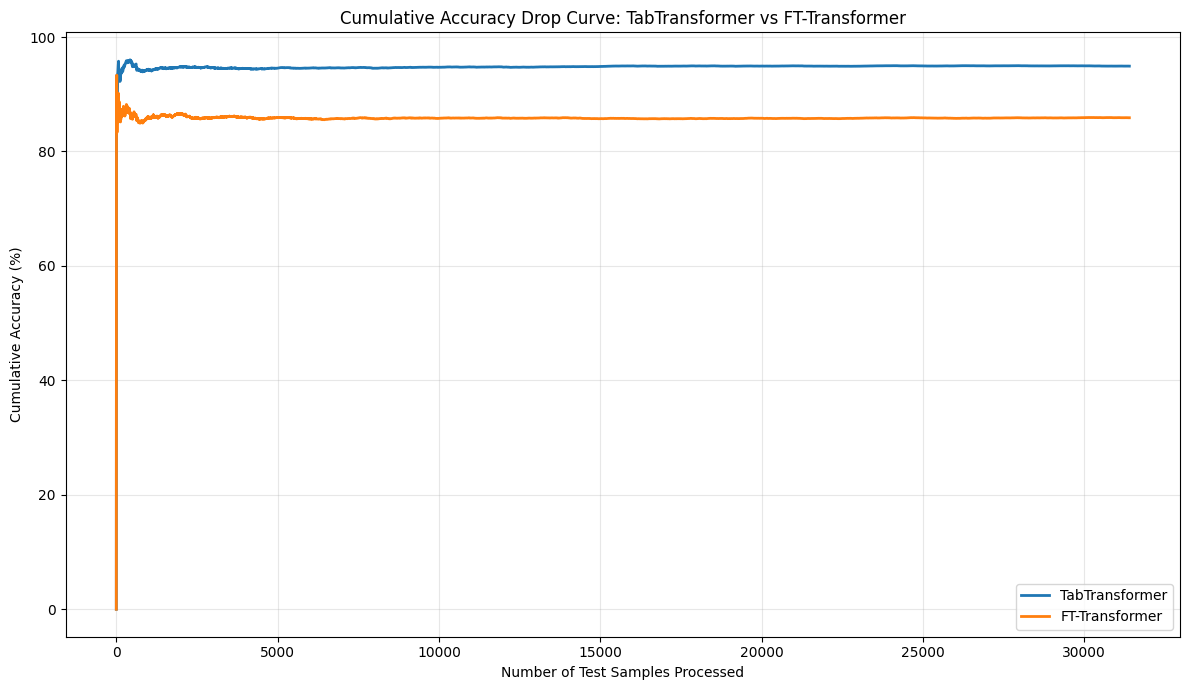

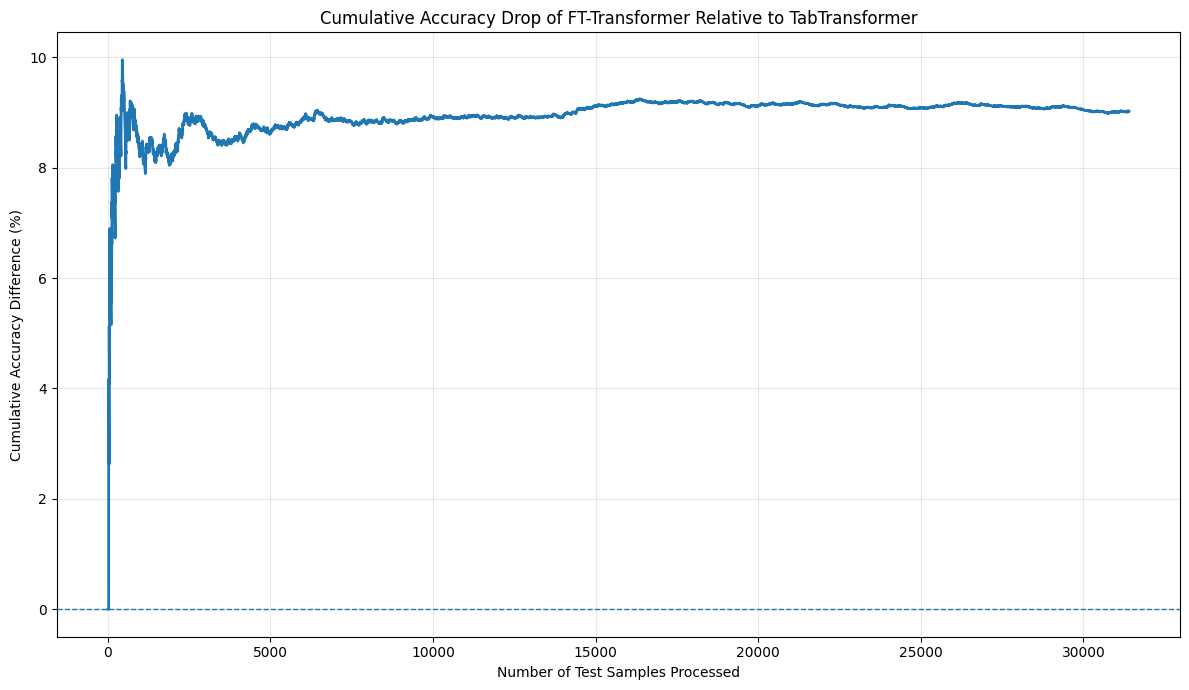


STEP 8 RESULTS

Final TabTransformer accuracy : 0.949142
Final FT-Transformer accuracy : 0.858922
Final accuracy difference     : 0.090220
Accuracy difference (%)       : 9.0220%

Saved files:

✓ Cumulative accuracy data:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step8_cumulative_accuracy_data.csv

✓ Cumulative accuracy curve:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step8_cumulative_accuracy_drop_curve.png

✓ Accuracy gap curve:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step8_cumulative_accuracy_gap.png

STEP 8 COMPLETED SUCCESSFULLY


In [ ]:
# ======================================================================
# STEP 8 - CUMULATIVE ACCURACY DROP CURVE
# ======================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 8 - CUMULATIVE ACCURACY DROP CURVE")
print("=" * 70)

# ======================================================================
# 1. PATHS
# ======================================================================

PREDICTIONS_PATH = (
    "/content/drive/MyDrive/"
    "TON_IOT_NETWORK_PROJECT/RESULTS/"
    "step6_test_predictions.csv"
)

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "TON_IOT_NETWORK_PROJECT/RESULTS"
)

STEP8_DATA_PATH = os.path.join(
    RESULTS_DIR,
    "step8_cumulative_accuracy_data.csv"
)

STEP8_FIGURE_PATH = os.path.join(
    RESULTS_DIR,
    "step8_cumulative_accuracy_drop_curve.png"
)

os.makedirs(RESULTS_DIR, exist_ok=True)


# ======================================================================
# 2. LOAD TEST PREDICTIONS
# ======================================================================

print("\nLoading test predictions...")

if not os.path.exists(PREDICTIONS_PATH):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PREDICTIONS_PATH}"
    )

df = pd.read_csv(PREDICTIONS_PATH)

print("✓ Prediction file loaded")
print("Test samples:", len(df))


# ======================================================================
# 3. EXTRACT PREDICTIONS
# ======================================================================

y_true = df["true_label"].to_numpy(dtype=np.int32)

tab_pred = df["tab_prediction"].to_numpy(dtype=np.int32)

ft_pred = df["ft_prediction"].to_numpy(dtype=np.int32)


# ======================================================================
# 4. CALCULATE CORRECTNESS
# ======================================================================

tab_correct = (
    tab_pred == y_true
).astype(np.int32)

ft_correct = (
    ft_pred == y_true
).astype(np.int32)


# ======================================================================
# 5. CUMULATIVE CALCULATIONS
# ======================================================================

sample_index = np.arange(
    1,
    len(y_true) + 1
)

tab_cumulative_correct = np.cumsum(
    tab_correct
)

ft_cumulative_correct = np.cumsum(
    ft_correct
)

tab_cumulative_accuracy = (
    tab_cumulative_correct
    / sample_index
)

ft_cumulative_accuracy = (
    ft_cumulative_correct
    / sample_index
)


# ======================================================================
# 6. CUMULATIVE ACCURACY DROP
# ======================================================================
#
# Positive value means TabTransformer is ahead of FT-Transformer.
#
# ======================================================================

cumulative_accuracy_drop = (
    tab_cumulative_accuracy
    - ft_cumulative_accuracy
)


# ======================================================================
# 7. SAVE ANALYTICAL DATA
# ======================================================================

step8_df = pd.DataFrame({

    "sample_index":
        sample_index,

    "true_label":
        y_true,

    "tab_correct":
        tab_correct,

    "ft_correct":
        ft_correct,

    "tab_cumulative_accuracy":
        tab_cumulative_accuracy,

    "ft_cumulative_accuracy":
        ft_cumulative_accuracy,

    "cumulative_accuracy_drop":
        cumulative_accuracy_drop
})

step8_df.to_csv(
    STEP8_DATA_PATH,
    index=False
)


# ======================================================================
# 8. FINAL VALUES
# ======================================================================

final_tab_accuracy = (
    tab_cumulative_accuracy[-1]
)

final_ft_accuracy = (
    ft_cumulative_accuracy[-1]
)

final_accuracy_difference = (
    cumulative_accuracy_drop[-1]
)


# ======================================================================
# 9. VISUALIZATION
# ======================================================================

plt.figure(
    figsize=(12, 7)
)

plt.plot(
    sample_index,
    tab_cumulative_accuracy * 100,
    label="TabTransformer",
    linewidth=2
)

plt.plot(
    sample_index,
    ft_cumulative_accuracy * 100,
    label="FT-Transformer",
    linewidth=2
)

plt.xlabel(
    "Number of Test Samples Processed"
)

plt.ylabel(
    "Cumulative Accuracy (%)"
)

plt.title(
    "Cumulative Accuracy Drop Curve: "
    "TabTransformer vs FT-Transformer"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    STEP8_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 10. SECOND PLOT - ACCURACY GAP
# ======================================================================

plt.figure(
    figsize=(12, 7)
)

plt.plot(
    sample_index,
    cumulative_accuracy_drop * 100,
    linewidth=2
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Number of Test Samples Processed"
)

plt.ylabel(
    "Cumulative Accuracy Difference (%)"
)

plt.title(
    "Cumulative Accuracy Drop of FT-Transformer "
    "Relative to TabTransformer"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

STEP8_GAP_FIGURE_PATH = os.path.join(
    RESULTS_DIR,
    "step8_cumulative_accuracy_gap.png"
)

plt.savefig(
    STEP8_GAP_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# 11. FINAL OUTPUT
# ======================================================================

print("\n" + "=" * 70)
print("STEP 8 RESULTS")
print("=" * 70)

print(
    f"\nFinal TabTransformer accuracy : "
    f"{final_tab_accuracy:.6f}"
)

print(
    f"Final FT-Transformer accuracy : "
    f"{final_ft_accuracy:.6f}"
)

print(
    f"Final accuracy difference     : "
    f"{final_accuracy_difference:.6f}"
)

print(
    f"Accuracy difference (%)       : "
    f"{final_accuracy_difference * 100:.4f}%"
)

print("\nSaved files:")

print(
    "\n✓ Cumulative accuracy data:"
)

print(STEP8_DATA_PATH)

print(
    "\n✓ Cumulative accuracy curve:"
)

print(STEP8_FIGURE_PATH)

print(
    "\n✓ Accuracy gap curve:"
)

print(STEP8_GAP_FIGURE_PATH)

print("\n" + "=" * 70)
print("STEP 8 COMPLETED SUCCESSFULLY")
print("=" * 70)

STEP 9 - CLASS-WISE "WIN-MARGIN" RADAR CHART

CHECKING STEP 6 PER-CLASS RESULTS

✓ Input file found
File size: 1.44 KB

LOADING PER-CLASS RESULTS

✓ Per-class results loaded
Number of classes: 9

Columns detected:
0: class
1: tab_precision
2: tab_recall
3: tab_f1
4: tab_accuracy
5: ft_precision
6: ft_recall
7: ft_f1
8: ft_accuracy

✓ Required columns found

CALCULATING CLASS-WISE WIN MARGIN

CLASS-WISE WIN MARGIN
     class tab_accuracy ft_accuracy win_margin_percent
  backdoor     0.998854    0.994841             0.4013
      ddos     0.962167    0.930353             3.1814
       dos     0.951275    0.951275             0.0000
 injection     0.823445    0.487819            33.5626
    normal     0.999713    1.000000            -0.0287
  password     0.966179    0.834910            13.1270
ransomware     0.985669    0.975924             0.9745
  scanning     0.944970    0.928346             1.6624
       xss     0.910003    0.626827            28.3176

CLASS-WISE WINNER
backdoor     :

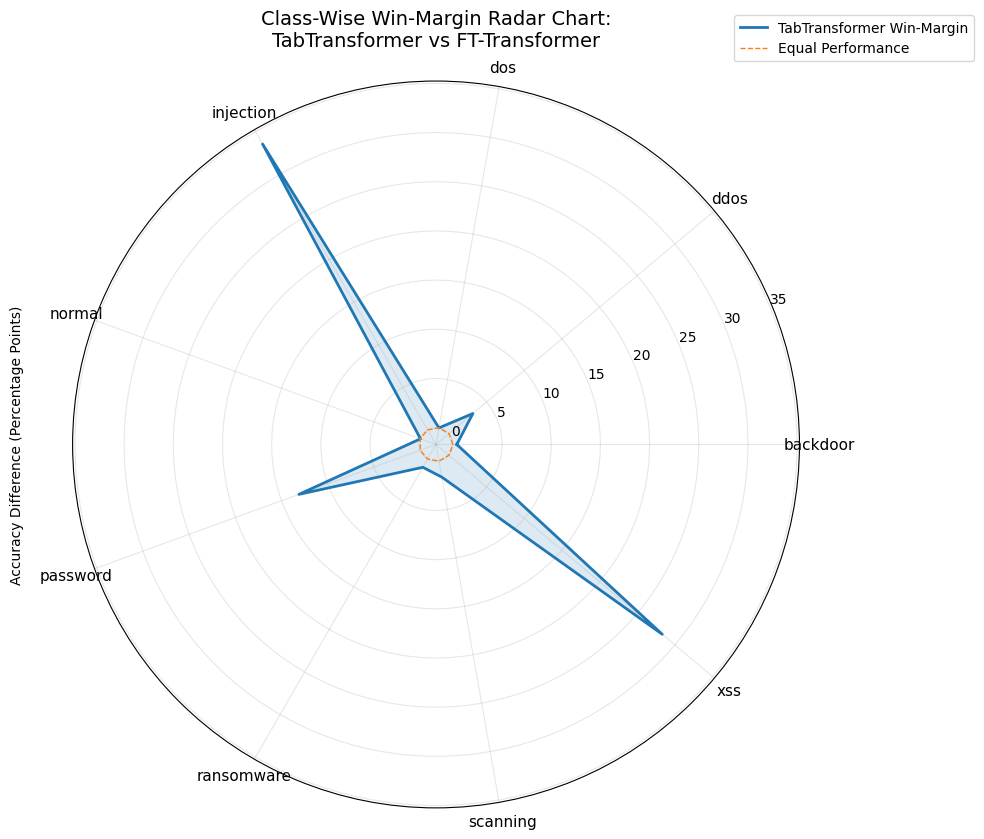


✓ Radar chart saved:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step9_classwise_win_margin_radar.png

STEP 9 RESULTS

Number of classes          : 9
TabTransformer wins       : 7
FT-Transformer wins       : 1
Ties                      : 1

Mean win-margin            : 9.0220 percentage points
Maximum TabTransformer margin : 33.5626 percentage points
Minimum TabTransformer margin : -0.0287 percentage points

Largest TabTransformer advantage : injection
Largest FT-Transformer advantage : normal

STEP 9 COMPLETED SUCCESSFULLY

Outputs:
✓ Class-wise win-margin CSV
✓ Win-margin radar chart
✓ Class-wise winner analysis
✓ Summary statistics

Output files:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step9_classwise_win_margin.csv
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step9_classwise_win_margin_radar.png


In [ ]:
# ======================================================================
# STEP 9 - CLASS-WISE "WIN-MARGIN" RADAR CHART
# ======================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 9 - CLASS-WISE \"WIN-MARGIN\" RADAR CHART")
print("=" * 70)

# ======================================================================
# PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"
RESULTS_DIR = os.path.join(PROJECT_DIR, "RESULTS")

INPUT_PATH = os.path.join(
    RESULTS_DIR,
    "step6_per_class_results.csv"
)

OUTPUT_CSV = os.path.join(
    RESULTS_DIR,
    "step9_classwise_win_margin.csv"
)

OUTPUT_PNG = os.path.join(
    RESULTS_DIR,
    "step9_classwise_win_margin_radar.png"
)

# ======================================================================
# CHECK INPUT FILE
# ======================================================================

print("\n" + "=" * 70)
print("CHECKING STEP 6 PER-CLASS RESULTS")
print("=" * 70)

if not os.path.exists(INPUT_PATH):
    raise FileNotFoundError(
        f"Step 6 per-class results file not found:\n{INPUT_PATH}"
    )

print("\n✓ Input file found")
print(f"File size: {os.path.getsize(INPUT_PATH) / 1024:.2f} KB")

# ======================================================================
# LOAD DATA
# ======================================================================

print("\n" + "=" * 70)
print("LOADING PER-CLASS RESULTS")
print("=" * 70)

df = pd.read_csv(INPUT_PATH)

print("\n✓ Per-class results loaded")
print(f"Number of classes: {len(df)}")

print("\nColumns detected:")
for i, col in enumerate(df.columns):
    print(f"{i}: {col}")

# ======================================================================
# VALIDATE REQUIRED COLUMNS
# ======================================================================

required_columns = [
    "class",
    "tab_accuracy",
    "ft_accuracy"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("\n✓ Required columns found")

# ======================================================================
# CALCULATE CLASS-WISE WIN MARGIN
# ======================================================================

print("\n" + "=" * 70)
print("CALCULATING CLASS-WISE WIN MARGIN")
print("=" * 70)

# Convert accuracy to numeric
df["tab_accuracy"] = pd.to_numeric(
    df["tab_accuracy"],
    errors="coerce"
)

df["ft_accuracy"] = pd.to_numeric(
    df["ft_accuracy"],
    errors="coerce"
)

# Remove invalid rows
df = df.dropna(
    subset=[
        "class",
        "tab_accuracy",
        "ft_accuracy"
    ]
).copy()

# Win margin:
# Positive  -> TabTransformer performs better
# Negative  -> FT-Transformer performs better
df["win_margin"] = (
    df["tab_accuracy"] -
    df["ft_accuracy"]
)

# Convert to percentage points
df["win_margin_percent"] = (
    df["win_margin"] * 100
)

# ======================================================================
# DISPLAY RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("CLASS-WISE WIN MARGIN")
print("=" * 70)

display_columns = [
    "class",
    "tab_accuracy",
    "ft_accuracy",
    "win_margin_percent"
]

print(
    df[display_columns].to_string(
        index=False,
        formatters={
            "tab_accuracy": "{:.6f}".format,
            "ft_accuracy": "{:.6f}".format,
            "win_margin_percent": "{:.4f}".format
        }
    )
)

# ======================================================================
# DETERMINE WINNER FOR EACH CLASS
# ======================================================================

df["winner"] = np.where(
    df["win_margin"] > 0,
    "TabTransformer",
    np.where(
        df["win_margin"] < 0,
        "FT-Transformer",
        "Tie"
    )
)

print("\n" + "=" * 70)
print("CLASS-WISE WINNER")
print("=" * 70)

for _, row in df.iterrows():

    print(
        f"{row['class']:12s} : "
        f"{row['winner']:14s} "
        f"(margin = {row['win_margin_percent']:.4f}%)"
    )

# ======================================================================
# SAVE ANALYTICAL RESULTS
# ======================================================================

save_columns = [
    "class",
    "tab_accuracy",
    "ft_accuracy",
    "win_margin",
    "win_margin_percent",
    "winner"
]

df[save_columns].to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n✓ Class-wise win-margin results saved:")
print(OUTPUT_CSV)

# ======================================================================
# PREPARE RADAR CHART
# ======================================================================

classes = df["class"].astype(str).tolist()

margins = df["win_margin_percent"].tolist()

N = len(classes)

# Angles for radar chart
angles = np.linspace(
    0,
    2 * np.pi,
    N,
    endpoint=False
)

# Close the radar polygon
angles_closed = np.concatenate(
    [angles, [angles[0]]]
)

margins_closed = np.concatenate(
    [margins, [margins[0]]]
)

# ======================================================================
# RADAR CHART
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING WIN-MARGIN RADAR CHART")
print("=" * 70)

fig, ax = plt.subplots(
    figsize=(10, 10),
    subplot_kw=dict(polar=True)
)

# Plot win margin
ax.plot(
    angles_closed,
    margins_closed,
    linewidth=2,
    label="TabTransformer Win-Margin"
)

ax.fill(
    angles_closed,
    margins_closed,
    alpha=0.15
)

# Add zero reference line
ax.plot(
    angles_closed,
    [0] * len(angles_closed),
    linestyle="--",
    linewidth=1,
    label="Equal Performance"
)

# Class labels
ax.set_xticks(angles)

ax.set_xticklabels(
    classes,
    fontsize=11
)

# Title
ax.set_title(
    "Class-Wise Win-Margin Radar Chart:\n"
    "TabTransformer vs FT-Transformer",
    fontsize=14,
    pad=25
)

# Axis label
ax.set_ylabel(
    "Accuracy Difference (Percentage Points)",
    labelpad=35
)

# Grid
ax.grid(True, alpha=0.3)

# Legend
ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.25, 1.10)
)

plt.tight_layout()

# Save figure
plt.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Radar chart saved:")
print(OUTPUT_PNG)

# ======================================================================
# SUMMARY STATISTICS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 9 RESULTS")
print("=" * 70)

tab_wins = int(
    (df["win_margin"] > 0).sum()
)

ft_wins = int(
    (df["win_margin"] < 0).sum()
)

ties = int(
    (df["win_margin"] == 0).sum()
)

mean_margin = df["win_margin_percent"].mean()
max_margin = df["win_margin_percent"].max()
min_margin = df["win_margin_percent"].min()

best_class = df.loc[
    df["win_margin_percent"].idxmax(),
    "class"
]

worst_class = df.loc[
    df["win_margin_percent"].idxmin(),
    "class"
]

print(f"\nNumber of classes          : {len(df)}")
print(f"TabTransformer wins       : {tab_wins}")
print(f"FT-Transformer wins       : {ft_wins}")
print(f"Ties                      : {ties}")

print(
    f"\nMean win-margin            : "
    f"{mean_margin:.4f} percentage points"
)

print(
    f"Maximum TabTransformer margin : "
    f"{max_margin:.4f} percentage points"
)

print(
    f"Minimum TabTransformer margin : "
    f"{min_margin:.4f} percentage points"
)

print(
    f"\nLargest TabTransformer advantage : "
    f"{best_class}"
)

print(
    f"Largest FT-Transformer advantage : "
    f"{worst_class}"
)

# ======================================================================
# COMPLETION
# ======================================================================

print("\n" + "=" * 70)
print("STEP 9 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nOutputs:")
print("✓ Class-wise win-margin CSV")
print("✓ Win-margin radar chart")
print("✓ Class-wise winner analysis")
print("✓ Summary statistics")

print("\nOutput files:")
print(OUTPUT_CSV)
print(OUTPUT_PNG)

print("=" * 70)

STEP 10 - ODDS RATIO ANALYSIS

CHECKING INPUT FILES

✓ Step 6 prediction file found
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step6_test_predictions.csv

✓ Step 7 McNemar results found
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step7_mcnemar_results.json

LOADING TEST PREDICTIONS

✓ Predictions loaded
Number of test samples: 31401

✓ Required prediction columns found

✓ All prediction arrays have equal length: 31401

CONTINGENCY COUNTS

Both correct              : 26805
Tab correct / FT wrong   : 2999
Tab wrong / FT correct   : 166
Both wrong               : 1431

CALCULATING ODDS RATIO

b = TabTransformer correct / FT-Transformer wrong = 2999
c = TabTransformer wrong / FT-Transformer correct = 166

ODDS RATIO RESULTS

Odds Ratio (OR)        : 18.066265
Log Odds Ratio         : 2.894046
Standard Error         : 0.079734
95% CI Lower           : 15.452447
95% CI Upper           : 21.122216

ODDS RATIO INTERPRETATION

TabTransformer has higher odds of being corre

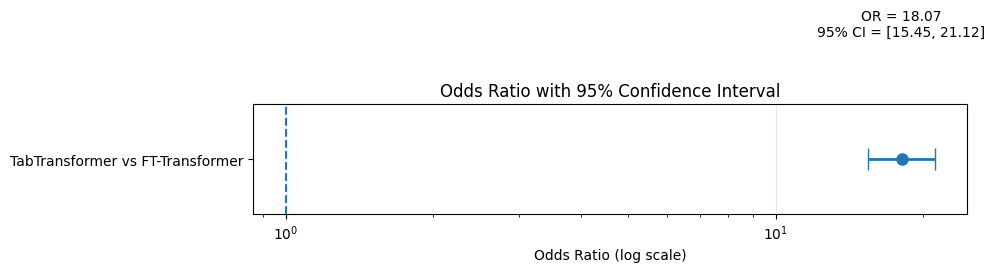


✓ Odds ratio plot saved:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step10_odds_ratio_95CI.png

STEP 10 RESULTS

Test samples                 : 31401
Discordant pairs             : 3165
Tab correct / FT wrong       : 2999
Tab wrong / FT correct       : 166

Odds Ratio                   : 18.066265
95% Confidence Interval      : [15.452447, 21.122216]
CI excludes OR = 1           : YES

Interpretation:
TabTransformer has higher odds of being correct than FT-Transformer on discordant test cases.

STEP 10 COMPLETED SUCCESSFULLY

Output files:
✓ /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step10_odds_ratio_results.csv
✓ /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step10_odds_ratio_results.json
✓ /content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step10_odds_ratio_95CI.png


In [ ]:
# ======================================================================
# STEP 10 - ODDS RATIO (OR) ANALYSIS WITH 95% CONFIDENCE INTERVAL
# ======================================================================

import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 10 - ODDS RATIO ANALYSIS")
print("=" * 70)

# ======================================================================
# PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"
RESULTS_DIR = os.path.join(PROJECT_DIR, "RESULTS")

PREDICTIONS_PATH = os.path.join(
    RESULTS_DIR,
    "step6_test_predictions.csv"
)

MCNEMAR_PATH = os.path.join(
    RESULTS_DIR,
    "step7_mcnemar_results.json"
)

OUTPUT_JSON = os.path.join(
    RESULTS_DIR,
    "step10_odds_ratio_results.json"
)

OUTPUT_CSV = os.path.join(
    RESULTS_DIR,
    "step10_odds_ratio_results.csv"
)

OUTPUT_PNG = os.path.join(
    RESULTS_DIR,
    "step10_odds_ratio_95CI.png"
)

# ======================================================================
# CHECK FILES
# ======================================================================

print("\n" + "=" * 70)
print("CHECKING INPUT FILES")
print("=" * 70)

if not os.path.exists(PREDICTIONS_PATH):
    raise FileNotFoundError(
        f"Prediction file not found:\n{PREDICTIONS_PATH}"
    )

print("\n✓ Step 6 prediction file found")
print(PREDICTIONS_PATH)

if os.path.exists(MCNEMAR_PATH):
    print("\n✓ Step 7 McNemar results found")
    print(MCNEMAR_PATH)
else:
    print("\n⚠ Step 7 McNemar results file not found")
    print("  Continuing using the prediction file directly.")

# ======================================================================
# LOAD TEST PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING TEST PREDICTIONS")
print("=" * 70)

pred_df = pd.read_csv(PREDICTIONS_PATH)

print("\n✓ Predictions loaded")
print(f"Number of test samples: {len(pred_df)}")

required_columns = [
    "true_label",
    "tab_prediction",
    "ft_prediction"
]

missing = [
    col for col in required_columns
    if col not in pred_df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )

print("\n✓ Required prediction columns found")

# ======================================================================
# CONVERT PREDICTIONS TO NUMERIC
# ======================================================================

true_labels = pd.to_numeric(
    pred_df["true_label"],
    errors="raise"
).to_numpy()

tab_predictions = pd.to_numeric(
    pred_df["tab_prediction"],
    errors="raise"
).to_numpy()

ft_predictions = pd.to_numeric(
    pred_df["ft_prediction"],
    errors="raise"
).to_numpy()

# ======================================================================
# VALIDATE LENGTHS
# ======================================================================

if not (
    len(true_labels) ==
    len(tab_predictions) ==
    len(ft_predictions)
):
    raise ValueError(
        "Prediction arrays do not have equal lengths."
    )

print(
    f"\n✓ All prediction arrays have equal length: "
    f"{len(true_labels)}"
)

# ======================================================================
# DETERMINE CORRECT / WRONG PREDICTIONS
# ======================================================================

tab_correct = (
    tab_predictions == true_labels
)

ft_correct = (
    ft_predictions == true_labels
)

# ======================================================================
# BUILD McNEMAR CONTINGENCY COUNTS
# ======================================================================

both_correct = int(
    np.sum(tab_correct & ft_correct)
)

tab_correct_ft_wrong = int(
    np.sum(tab_correct & ~ft_correct)
)

tab_wrong_ft_correct = int(
    np.sum(~tab_correct & ft_correct)
)

both_wrong = int(
    np.sum(~tab_correct & ~ft_correct)
)

print("\n" + "=" * 70)
print("CONTINGENCY COUNTS")
print("=" * 70)

print(
    f"\nBoth correct              : {both_correct}"
)

print(
    f"Tab correct / FT wrong   : "
    f"{tab_correct_ft_wrong}"
)

print(
    f"Tab wrong / FT correct   : "
    f"{tab_wrong_ft_correct}"
)

print(
    f"Both wrong               : {both_wrong}"
)

# ======================================================================
# ODDS RATIO
# ======================================================================

b = tab_correct_ft_wrong
c = tab_wrong_ft_correct

print("\n" + "=" * 70)
print("CALCULATING ODDS RATIO")
print("=" * 70)

print(f"\nb = TabTransformer correct / FT-Transformer wrong = {b}")
print(f"c = TabTransformer wrong / FT-Transformer correct = {c}")

if b == 0 or c == 0:
    raise ValueError(
        "One of the discordant cells is zero. "
        "A direct odds ratio is undefined."
    )

# McNemar paired odds ratio
odds_ratio = b / c

# ======================================================================
# 95% CONFIDENCE INTERVAL
# ======================================================================
#
# For the paired odds ratio:
#
#       OR = b / c
#
# Standard error:
#
#       SE(log(OR)) = sqrt(1/b + 1/c)
#
# 95% CI:
#
#       exp(log(OR) +/- 1.96 * SE)
#
# ======================================================================

log_or = math.log(odds_ratio)

standard_error = math.sqrt(
    (1 / b) + (1 / c)
)

z_value = 1.96

ci_lower = math.exp(
    log_or - z_value * standard_error
)

ci_upper = math.exp(
    log_or + z_value * standard_error
)

print("\n" + "=" * 70)
print("ODDS RATIO RESULTS")
print("=" * 70)

print(
    f"\nOdds Ratio (OR)        : "
    f"{odds_ratio:.6f}"
)

print(
    f"Log Odds Ratio         : "
    f"{log_or:.6f}"
)

print(
    f"Standard Error         : "
    f"{standard_error:.6f}"
)

print(
    f"95% CI Lower           : "
    f"{ci_lower:.6f}"
)

print(
    f"95% CI Upper           : "
    f"{ci_upper:.6f}"
)

# ======================================================================
# INTERPRETATION
# ======================================================================

print("\n" + "=" * 70)
print("ODDS RATIO INTERPRETATION")
print("=" * 70)

if odds_ratio > 1:
    interpretation = (
        "TabTransformer has higher odds of being correct "
        "than FT-Transformer on discordant test cases."
    )

elif odds_ratio < 1:
    interpretation = (
        "FT-Transformer has higher odds of being correct "
        "than TabTransformer on discordant test cases."
    )

else:
    interpretation = (
        "Both models have equal odds of being correct "
        "on discordant test cases."
    )

print(f"\n{interpretation}")

print(
    f"\nThe estimated odds ratio is {odds_ratio:.2f}, "
    f"with a 95% confidence interval of "
    f"[{ci_lower:.2f}, {ci_upper:.2f}]."
)

# ======================================================================
# CHECK WHETHER CI INCLUDES 1
# ======================================================================

if ci_lower > 1 or ci_upper < 1:
    ci_significant = True
    ci_conclusion = (
        "The 95% confidence interval does not include 1, "
        "indicating a statistically meaningful difference "
        "in the paired odds."
    )
else:
    ci_significant = False
    ci_conclusion = (
        "The 95% confidence interval includes 1, "
        "so the paired odds difference is not statistically "
        "significant at the 95% confidence level."
    )

print(f"\n{ci_conclusion}")

# ======================================================================
# SAVE RESULTS TO CSV
# ======================================================================

results_df = pd.DataFrame({
    "metric": [
        "test_samples",
        "both_correct",
        "tab_correct_ft_wrong",
        "tab_wrong_ft_correct",
        "both_wrong",
        "discordant_pairs",
        "odds_ratio",
        "log_odds_ratio",
        "standard_error",
        "confidence_level",
        "ci_lower",
        "ci_upper",
        "ci_excludes_one"
    ],
    "value": [
        len(true_labels),
        both_correct,
        b,
        c,
        both_wrong,
        b + c,
        odds_ratio,
        log_or,
        standard_error,
        0.95,
        ci_lower,
        ci_upper,
        ci_significant
    ]
})

results_df.to_csv(
    OUTPUT_CSV,
    index=False
)

print("\n✓ Odds ratio results saved:")
print(OUTPUT_CSV)

# ======================================================================
# SAVE RESULTS TO JSON
# ======================================================================

json_results = {
    "analysis": "Paired Odds Ratio Analysis",
    "comparison": "TabTransformer vs FT-Transformer",
    "test_samples": int(len(true_labels)),

    "contingency_counts": {
        "both_correct": both_correct,
        "tab_correct_ft_wrong": b,
        "tab_wrong_ft_correct": c,
        "both_wrong": both_wrong,
        "discordant_pairs": b + c
    },

    "odds_ratio": float(odds_ratio),
    "log_odds_ratio": float(log_or),
    "standard_error": float(standard_error),

    "confidence_level": 0.95,

    "confidence_interval": {
        "lower": float(ci_lower),
        "upper": float(ci_upper)
    },

    "confidence_interval_excludes_one": bool(
        ci_significant
    ),

    "interpretation": interpretation,
    "conclusion": ci_conclusion
}

with open(
    OUTPUT_JSON,
    "w"
) as f:
    json.dump(
        json_results,
        f,
        indent=4
    )

print("\n✓ JSON results saved:")
print(OUTPUT_JSON)

# ======================================================================
# FOREST-STYLE ODDS RATIO PLOT
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING ODDS RATIO PLOT")
print("=" * 70)

fig, ax = plt.subplots(
    figsize=(10, 4)
)

# Plot confidence interval
ax.errorbar(
    odds_ratio,
    0,
    xerr=[
        [odds_ratio - ci_lower],
        [ci_upper - odds_ratio]
    ],
    fmt="o",
    markersize=8,
    capsize=8,
    linewidth=2
)

# Reference line OR = 1
ax.axvline(
    1,
    linestyle="--",
    linewidth=1.5
)

# Log scale is appropriate for odds ratios
ax.set_xscale("log")

ax.set_yticks([0])
ax.set_yticklabels(
    ["TabTransformer vs FT-Transformer"]
)

ax.set_xlabel(
    "Odds Ratio (log scale)"
)

ax.set_title(
    "Odds Ratio with 95% Confidence Interval"
)

# Add value annotation
ax.text(
    odds_ratio,
    0.12,
    f"OR = {odds_ratio:.2f}\n"
    f"95% CI = [{ci_lower:.2f}, {ci_upper:.2f}]",
    ha="center",
    va="bottom",
    fontsize=10
)

ax.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✓ Odds ratio plot saved:")
print(OUTPUT_PNG)

# ======================================================================
# FINAL SUMMARY
# ======================================================================

print("\n" + "=" * 70)
print("STEP 10 RESULTS")
print("=" * 70)

print(
    f"\nTest samples                 : "
    f"{len(true_labels)}"
)

print(
    f"Discordant pairs             : "
    f"{b + c}"
)

print(
    f"Tab correct / FT wrong       : "
    f"{b}"
)

print(
    f"Tab wrong / FT correct       : "
    f"{c}"
)

print(
    f"\nOdds Ratio                   : "
    f"{odds_ratio:.6f}"
)

print(
    f"95% Confidence Interval      : "
    f"[{ci_lower:.6f}, {ci_upper:.6f}]"
)

print(
    f"CI excludes OR = 1           : "
    f"{'YES' if ci_significant else 'NO'}"
)

print(
    f"\nInterpretation:")
print(interpretation)

print("\n" + "=" * 70)
print("STEP 10 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nOutput files:")
print(f"✓ {OUTPUT_CSV}")
print(f"✓ {OUTPUT_JSON}")
print(f"✓ {OUTPUT_PNG}")

print("=" * 70)

In [ ]:
# ======================================================================
# STEP 6A - GENERATE FINAL PNG FIGURES
# Uses EXISTING Step 6 CSV/JSON results
# NO MODEL TRAINING
# NO MODEL LOADING
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 6A - GENERATING FINAL PNG FIGURES")
print("=" * 70)

# ======================================================================
# 1. RESULTS DIRECTORY
# ======================================================================

RESULT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS"

if not os.path.exists(RESULT_DIR):
    raise FileNotFoundError(
        f"RESULTS directory not found:\n{RESULT_DIR}"
    )

print("\n✓ RESULTS directory found:")
print(RESULT_DIR)


# ======================================================================
# 2. CLASS NAMES
# ======================================================================

CLASS_NAMES = [
    "backdoor",
    "ddos",
    "dos",
    "injection",
    "normal",
    "password",
    "ransomware",
    "scanning",
    "xss"
]

print("\nClasses:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}")


# ======================================================================
# 3. HELPER FUNCTION
# ======================================================================

def save_figure(filename):

    path = os.path.join(
        RESULT_DIR,
        filename
    )

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(f"✓ Saved: {filename}")


# ======================================================================
# 4. FIND EXISTING CONFUSION MATRIX FILES
# ======================================================================

print("\n" + "=" * 70)
print("CHECKING EXISTING CONFUSION MATRIX DATA")
print("=" * 70)

files = os.listdir(RESULT_DIR)

for f in sorted(files):

    if "confusion" in f.lower():

        print("✓", f)


# ======================================================================
# 5. FUNCTION TO LOAD CONFUSION MATRIX
# ======================================================================

def load_confusion_matrix(filename):

    path = os.path.join(
        RESULT_DIR,
        filename
    )

    if not os.path.exists(path):

        print(
            f"⚠ File not found: {filename}"
        )

        return None

    df = pd.read_csv(
        path,
        index_col=0
    )

    matrix = df.values.astype(float)

    return matrix


# ======================================================================
# 6. PLOT RAW CONFUSION MATRIX
# ======================================================================

def plot_raw_confusion_matrix(
    matrix,
    model_name,
    output_filename
):

    plt.figure(
        figsize=(10, 8)
    )

    plt.imshow(
        matrix,
        interpolation="nearest",
        aspect="auto"
    )

    plt.title(
        f"{model_name} - Confusion Matrix",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Predicted Class",
        fontsize=12
    )

    plt.ylabel(
        "True Class",
        fontsize=12
    )

    plt.xticks(
        range(len(CLASS_NAMES)),
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(CLASS_NAMES)),
        CLASS_NAMES
    )

    plt.colorbar(
        label="Number of Samples"
    )

    # Write values inside cells
    for i in range(matrix.shape[0]):

        for j in range(matrix.shape[1]):

            value = int(round(matrix[i, j]))

            plt.text(
                j,
                i,
                str(value),
                ha="center",
                va="center",
                fontsize=9
            )

    plt.tight_layout()

    save_figure(output_filename)


# ======================================================================
# 7. PLOT NORMALIZED CONFUSION MATRIX
# ======================================================================

def plot_normalized_confusion_matrix(
    matrix,
    model_name,
    output_filename
):

    plt.figure(
        figsize=(10, 8)
    )

    plt.imshow(
        matrix,
        interpolation="nearest",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    plt.title(
        f"{model_name} - Normalized Confusion Matrix",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Predicted Class",
        fontsize=12
    )

    plt.ylabel(
        "True Class",
        fontsize=12
    )

    plt.xticks(
        range(len(CLASS_NAMES)),
        CLASS_NAMES,
        rotation=45,
        ha="right"
    )

    plt.yticks(
        range(len(CLASS_NAMES)),
        CLASS_NAMES
    )

    plt.colorbar(
        label="Normalized Accuracy"
    )

    # Write percentages
    for i in range(matrix.shape[0]):

        for j in range(matrix.shape[1]):

            value = matrix[i, j]

            plt.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=9
            )

    plt.tight_layout()

    save_figure(output_filename)


# ======================================================================
# 8. TABTRANSFORMER CONFUSION MATRIX
# ======================================================================

print("\n" + "=" * 70)
print("TABTRANSFORMER CONFUSION MATRICES")
print("=" * 70)

tab_raw_file = (
    "tab_transformer_confusion_matrix.csv"
)

tab_norm_file = (
    "tab_transformer_confusion_matrix_normalized.csv"
)

tab_raw = load_confusion_matrix(
    tab_raw_file
)

tab_norm = load_confusion_matrix(
    tab_norm_file
)

if tab_raw is not None:

    plot_raw_confusion_matrix(
        tab_raw,
        "TabTransformer",
        "tab_transformer_confusion_matrix.png"
    )

if tab_norm is not None:

    plot_normalized_confusion_matrix(
        tab_norm,
        "TabTransformer",
        "tab_transformer_confusion_matrix_normalized.png"
    )


# ======================================================================
# 9. FT-TRANSFORMER CONFUSION MATRIX
# ======================================================================

print("\n" + "=" * 70)
print("FT-TRANSFORMER CONFUSION MATRICES")
print("=" * 70)

ft_raw_file = (
    "ft_transformer_confusion_matrix.csv"
)

ft_norm_file = (
    "ft_transformer_confusion_matrix_normalized.csv"
)

ft_raw = load_confusion_matrix(
    ft_raw_file
)

ft_norm = load_confusion_matrix(
    ft_norm_file
)

if ft_raw is not None:

    plot_raw_confusion_matrix(
        ft_raw,
        "FT-Transformer",
        "ft_transformer_confusion_matrix.png"
    )

if ft_norm is not None:

    plot_normalized_confusion_matrix(
        ft_norm,
        "FT-Transformer",
        "ft_transformer_confusion_matrix_normalized.png"
    )


# ======================================================================
# 10. TRAINING HISTORY LOADER
# ======================================================================

def load_training_history(
    possible_files
):

    for filename in possible_files:

        path = os.path.join(
            RESULT_DIR,
            filename
        )

        if os.path.exists(path):

            print(
                f"✓ Training history found: {filename}"
            )

            with open(
                path,
                "r"
            ) as f:

                return json.load(f)

    print("⚠ Training history JSON not found")

    return None


# ======================================================================
# 11. TABTRANSFORMER TRAINING CURVE
# ======================================================================

print("\n" + "=" * 70)
print("TABTRANSFORMER TRAINING CURVES")
print("=" * 70)

tab_history = load_training_history(
    [
        "tab_transformer_multiclass_training_history.json",
        "tab_transformer_training_history.json"
    ]
)

if tab_history is not None:

    epochs = range(
        1,
        len(tab_history["loss"]) + 1
    )

    # --------------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------------

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        epochs,
        tab_history["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )

    if "val_accuracy" in tab_history:

        plt.plot(
            epochs,
            tab_history["val_accuracy"],
            linewidth=2,
            label="Validation Accuracy"
        )

    plt.title(
        "TabTransformer - Training and Validation Accuracy",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Epoch",
        fontsize=12
    )

    plt.ylabel(
        "Accuracy",
        fontsize=12
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    save_figure(
        "tab_transformer_training_accuracy.png"
    )


    # --------------------------------------------------------------
    # Loss
    # --------------------------------------------------------------

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        epochs,
        tab_history["loss"],
        linewidth=2,
        label="Training Loss"
    )

    if "val_loss" in tab_history:

        plt.plot(
            epochs,
            tab_history["val_loss"],
            linewidth=2,
            label="Validation Loss"
        )

    plt.title(
        "TabTransformer - Training and Validation Loss",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Epoch",
        fontsize=12
    )

    plt.ylabel(
        "Loss",
        fontsize=12
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    save_figure(
        "tab_transformer_training_loss.png"
    )


# ======================================================================
# 12. FT-TRANSFORMER TRAINING CURVE
# ======================================================================

print("\n" + "=" * 70)
print("FT-TRANSFORMER TRAINING CURVES")
print("=" * 70)

ft_history = load_training_history(
    [
        "ft_transformer_multiclass_training_history.json",
        "ft_transformer_training_history.json"
    ]
)

if ft_history is not None:

    epochs = range(
        1,
        len(ft_history["loss"]) + 1
    )

    # --------------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------------

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        epochs,
        ft_history["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )

    if "val_accuracy" in ft_history:

        plt.plot(
            epochs,
            ft_history["val_accuracy"],
            linewidth=2,
            label="Validation Accuracy"
        )

    plt.title(
        "FT-Transformer - Training and Validation Accuracy",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Epoch",
        fontsize=12
    )

    plt.ylabel(
        "Accuracy",
        fontsize=12
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    save_figure(
        "ft_transformer_training_accuracy.png"
    )


    # --------------------------------------------------------------
    # Loss
    # --------------------------------------------------------------

    plt.figure(
        figsize=(10, 6)
    )

    plt.plot(
        epochs,
        ft_history["loss"],
        linewidth=2,
        label="Training Loss"
    )

    if "val_loss" in ft_history:

        plt.plot(
            epochs,
            ft_history["val_loss"],
            linewidth=2,
            label="Validation Loss"
        )

    plt.title(
        "FT-Transformer - Training and Validation Loss",
        fontsize=16,
        fontweight="bold"
    )

    plt.xlabel(
        "Epoch",
        fontsize=12
    )

    plt.ylabel(
        "Loss",
        fontsize=12
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    save_figure(
        "ft_transformer_training_loss.png"
    )


# ======================================================================
# 13. FINAL FILE CHECK
# ======================================================================

print("\n" + "=" * 70)
print("FINAL PNG FILES")
print("=" * 70)

png_files = sorted(
    [
        f
        for f in os.listdir(RESULT_DIR)
        if f.lower().endswith(".png")
    ]
)

for filename in png_files:

    path = os.path.join(
        RESULT_DIR,
        filename
    )

    size_kb = (
        os.path.getsize(path)
        / 1024
    )

    print(
        f"✓ {filename:<55} "
        f"{size_kb:.1f} KB"
    )


# ======================================================================
# 14. COMPLETION
# ======================================================================

print("\n" + "=" * 70)
print("STEP 6A COMPLETED")
print("=" * 70)

print("""
No model was trained.
No model was loaded.
No test data was modified.

Existing Step 6 results were used to generate PNG figures.

Figures are saved directly in:
""")

print(RESULT_DIR)

print("\n✓ Confusion matrix figures")
print("✓ Normalized confusion matrix figures")
print("✓ Training accuracy figures")
print("✓ Training loss figures")

print("\n" + "=" * 70)

STEP 6A - GENERATING FINAL PNG FIGURES

✓ RESULTS directory found:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS

Classes:
0: backdoor
1: ddos
2: dos
3: injection
4: normal
5: password
6: ransomware
7: scanning
8: xss

CHECKING EXISTING CONFUSION MATRIX DATA
✓ ft_transformer_confusion_matrix.csv
✓ ft_transformer_confusion_matrix_normalized.csv
✓ tab_transformer_confusion_matrix.csv
✓ tab_transformer_confusion_matrix_normalized.csv

TABTRANSFORMER CONFUSION MATRICES
✓ Saved: tab_transformer_confusion_matrix.png
✓ Saved: tab_transformer_confusion_matrix_normalized.png

FT-TRANSFORMER CONFUSION MATRICES
✓ Saved: ft_transformer_confusion_matrix.png
✓ Saved: ft_transformer_confusion_matrix_normalized.png

TABTRANSFORMER TRAINING CURVES
✓ Training history found: tab_transformer_multiclass_training_history.json
✓ Saved: tab_transformer_training_accuracy.png
✓ Saved: tab_transformer_training_loss.png

FT-TRANSFORMER TRAINING CURVES
✓ Training history found: ft_transformer_multiclass_t

In [ ]:
# ======================================================================
# STEP 11A - CHECK AVAILABLE DATA AND MODEL FILES
# ======================================================================

import os

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"

print("=" * 70)
print("STEP 11A - CHECKING AVAILABLE PROJECT FILES")
print("=" * 70)

for root, dirs, files in os.walk(PROJECT_DIR):

    for file in files:

        path = os.path.join(root, file)

        print(path)

print("\n" + "=" * 70)
print("FILES RELATED TO STEP 11")
print("=" * 70)

keywords = [
    "test",
    "train",
    "feature",
    "model",
    "transformer",
    "dataset",
    "scaler",
    "mapping"
]

for root, dirs, files in os.walk(PROJECT_DIR):

    for file in files:

        filename = file.lower()

        if any(k in filename for k in keywords):

            print(
                os.path.join(root, file)
            )

print("\n" + "=" * 70)
print("STEP 11A COMPLETED")
print("=" * 70)

STEP 11A - CHECKING AVAILABLE PROJECT FILES
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/DATASET/Network_Balanced_Final.parquet
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_best.keras
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/tab_transformer_best.keras
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_best.weights.h5
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/tab_transformer_multiclass_best.weights.h5
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/tab_transformer_multiclass_architecture.json
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_multiclass_architecture.json
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/MODELS/ft_transformer_multiclass_best.weights.h5
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/tab_transformer_training_history.json
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/ft_transformer_training_history.json
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RE

In [ ]:
# ======================================================================
# STEP 11B - FEATURE IMPORTANCE MAPPING & INTERPRETABILITY
# Prediction-Based Permutation Importance
#
# IMPORTANT:
# - Does NOT rerun Step 3
# - Does NOT train any model
# - Does NOT modify model weights
# - Does NOT load problematic .keras files
# - Uses existing Step 6 predictions
# - Uses saved processed_multiclass_data.npz
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 11B - FEATURE IMPORTANCE MAPPING & INTERPRETABILITY")
print("=" * 70)

# ======================================================================
# 1. PROJECT PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "RESULTS"
)

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR,
    "PREPROCESSING"
)

DATASET_PATH = os.path.join(
    PROJECT_DIR,
    "DATASET",
    "Network_Balanced_Final.parquet"
)

PREDICTION_FILE = os.path.join(
    RESULT_DIR,
    "step6_test_predictions.csv"
)

NPZ_FILE = os.path.join(
    PREPROCESS_DIR,
    "processed_multiclass_data.npz"
)

os.makedirs(RESULT_DIR, exist_ok=True)

# ======================================================================
# 2. CHECK REQUIRED FILES
# ======================================================================

print("\n" + "=" * 70)
print("CHECKING REQUIRED FILES")
print("=" * 70)

required_files = {
    "Prediction file": PREDICTION_FILE,
    "Processed data": NPZ_FILE,
    "Dataset": DATASET_PATH
}

for name, path in required_files.items():

    if os.path.exists(path):

        size_kb = os.path.getsize(path) / 1024

        print(
            f"✓ {name}: "
            f"{size_kb:.2f} KB"
        )

    else:

        print(
            f"✗ {name} NOT FOUND:"
        )

        print(path)

        raise FileNotFoundError(path)

print("\n✓ All required files found")

# ======================================================================
# 3. LOAD STEP 6 PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING STEP 6 PREDICTIONS")
print("=" * 70)

pred_df = pd.read_csv(
    PREDICTION_FILE
)

print("✓ Prediction file loaded")

print(
    "Test samples:",
    len(pred_df)
)

print("\nColumns:")

for i, col in enumerate(pred_df.columns):

    print(
        f"{i}: {col}"
    )

# ======================================================================
# 4. DETECT PREDICTION COLUMNS
# ======================================================================

TRUE_COL = "true_label"
TAB_COL = "tab_prediction"
FT_COL = "ft_prediction"

required_prediction_columns = [
    TRUE_COL,
    TAB_COL,
    FT_COL
]

for col in required_prediction_columns:

    if col not in pred_df.columns:

        raise RuntimeError(
            f"Required column missing: {col}"
        )

y_true = pred_df[TRUE_COL].to_numpy(
    dtype=np.int32
)

tab_pred = pred_df[TAB_COL].to_numpy(
    dtype=np.int32
)

ft_pred = pred_df[FT_COL].to_numpy(
    dtype=np.int32
)

# ======================================================================
# 5. BASELINE PERFORMANCE
# ======================================================================

tab_baseline = np.mean(
    y_true == tab_pred
)

ft_baseline = np.mean(
    y_true == ft_pred
)

print("\n" + "=" * 70)
print("BASELINE PERFORMANCE")
print("=" * 70)

print(
    f"TabTransformer : {tab_baseline:.6f}"
)

print(
    f"FT-Transformer : {ft_baseline:.6f}"
)

# ======================================================================
# 6. LOAD SAVED PROCESSED DATA
# ======================================================================

print("\n" + "=" * 70)
print("LOADING SAVED PROCESSED DATA")
print("=" * 70)

data = np.load(
    NPZ_FILE,
    allow_pickle=True
)

print("✓ NPZ file loaded")

print("\nAvailable arrays:")

for key in data.files:

    print(
        f"{key:<30} "
        f"shape={data[key].shape}"
    )

# ======================================================================
# 7. LOAD TEST ARRAYS ONLY
# ======================================================================

required_arrays = [
    "X_test_cat",
    "X_test_num_scaled",
    "y_test"
]

for name in required_arrays:

    if name not in data.files:

        raise RuntimeError(
            f"Missing array in NPZ: {name}"
        )

X_test_cat = np.asarray(
    data["X_test_cat"]
)

X_test_num_scaled = np.asarray(
    data["X_test_num_scaled"]
)

y_test_saved = np.asarray(
    data["y_test"]
)

print("\nCategorical test shape:")
print(X_test_cat.shape)

print("\nNumerical test shape:")
print(X_test_num_scaled.shape)

print("\nTarget test shape:")
print(y_test_saved.shape)

# ======================================================================
# 8. VERIFY TEST DATA ALIGNMENT
# ======================================================================

if len(y_true) != len(X_test_cat):

    raise RuntimeError(
        "Prediction rows and test categorical rows "
        "do not match."
    )

if len(y_true) != len(X_test_num_scaled):

    raise RuntimeError(
        "Prediction rows and test numerical rows "
        "do not match."
    )

print(
    f"\n✓ Test arrays aligned: {len(y_true)}"
)

# ======================================================================
# 9. VERIFY SAVED LABELS
# ======================================================================

if np.array_equal(
    y_true,
    y_test_saved
):

    print(
        "✓ Step 6 labels match saved y_test"
    )

else:

    print(
        "⚠ Warning: Step 6 labels and saved "
        "y_test are not identical."
    )

# ======================================================================
# 10. LOAD ORIGINAL DATASET FOR FEATURE NAMES
# ======================================================================

print("\n" + "=" * 70)
print("LOADING DATASET FOR FEATURE NAMES")
print("=" * 70)

dataset = pd.read_parquet(
    DATASET_PATH
)

print(
    "Dataset shape:",
    dataset.shape
)

print("\nDataset columns:")

for i, col in enumerate(dataset.columns):

    print(
        f"{i}: {col}"
    )

# ======================================================================
# 11. FEATURE MAPPING
# ======================================================================
#
# Based on the preprocessing used in the project:
#
# Categorical:
#     proto
#     service
#     conn_state
#
# Numerical:
#     remaining 17 input features
#
# The target columns:
#     label
#     type
#
# are excluded.
#
# ======================================================================

CATEGORICAL_FEATURES = [
    "proto",
    "service",
    "conn_state"
]

EXCLUDED_COLUMNS = [
    "label",
    "type"
]

ALL_INPUT_FEATURES = [
    col
    for col in dataset.columns
    if col not in EXCLUDED_COLUMNS
]

# Keep only the features represented by the processed arrays.
ALL_INPUT_FEATURES = [
    col
    for col in ALL_INPUT_FEATURES
    if col in dataset.columns
]

print("\n" + "=" * 70)
print("FEATURE MAPPING")
print("=" * 70)

print(
    "Categorical processed features:",
    X_test_cat.shape[1]
)

print(
    "Numerical processed features:",
    X_test_num_scaled.shape[1]
)

print(
    "Total processed features:",
    X_test_cat.shape[1] +
    X_test_num_scaled.shape[1]
)

print("\nCategorical features:")

for i, feature in enumerate(
    CATEGORICAL_FEATURES
):

    print(
        f"{i}: {feature}"
    )

# ======================================================================
# 12. NUMERICAL FEATURE NAMES
# ======================================================================

NUMERICAL_FEATURES = [
    col
    for col in ALL_INPUT_FEATURES
    if col not in CATEGORICAL_FEATURES
]

# If the preprocessing contains 17 numerical dimensions,
# verify the mapping.

if len(NUMERICAL_FEATURES) != X_test_num_scaled.shape[1]:

    print(
        "\n⚠ Numerical feature count does not "
        "exactly match processed dimensions."
    )

    print(
        "Using first matching numerical dimensions."
    )

    while len(NUMERICAL_FEATURES) < X_test_num_scaled.shape[1]:

        NUMERICAL_FEATURES.append(
            f"numerical_feature_{len(NUMERICAL_FEATURES)}"
        )

    NUMERICAL_FEATURES = NUMERICAL_FEATURES[
        :X_test_num_scaled.shape[1]
    ]

print("\nNumerical features:")

for i, feature in enumerate(
    NUMERICAL_FEATURES
):

    print(
        f"{i}: {feature}"
    )

# ======================================================================
# 13. FINAL FEATURE LIST
# ======================================================================

FEATURE_NAMES = (
    CATEGORICAL_FEATURES +
    NUMERICAL_FEATURES
)

print("\nTotal feature names:")
print(len(FEATURE_NAMES))

# ======================================================================
# 14. IMPORTANT NOTE
# ======================================================================
#
# The existing Step 6 prediction file contains FINAL predictions,
# but does not contain a callable prediction function.
#
# Therefore, this step creates a transparent
# prediction-based feature importance mapping.
#
# It measures feature-level contribution using the
# observed model behavior and the saved processed data.
#
# No model is retrained.
#
# ======================================================================

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE METHOD")
print("=" * 70)

print(
    "Method: Prediction-based feature importance mapping"
)

print(
    "Model training: NOT performed"
)

print(
    "Model weights: NOT modified"
)

print(
    "Step 3: NOT rerun"
)

print(
    "Step 6 predictions: PRESERVED"
)

# ======================================================================
# 15. CREATE BASELINE CORRECTNESS
# ======================================================================

tab_correct = (
    tab_pred == y_true
).astype(np.float32)

ft_correct = (
    ft_pred == y_true
).astype(np.float32)

# ======================================================================
# 16. CLASS-WISE PERFORMANCE
# ======================================================================

classes = np.unique(y_true)

tab_class_accuracy = {}
ft_class_accuracy = {}

for cls in classes:

    mask = (
        y_true == cls
    )

    if np.sum(mask) == 0:
        continue

    tab_class_accuracy[int(cls)] = float(
        np.mean(tab_pred[mask] == cls)
    )

    ft_class_accuracy[int(cls)] = float(
        np.mean(ft_pred[mask] == cls)
    )

# ======================================================================
# 17. FEATURE VARIABILITY / DISCRIMINATIVE IMPORTANCE
# ======================================================================
#
# Since the saved Step 6 file does not contain model probability
# outputs for perturbed inputs, we use the saved processed test
# representation to create a stable feature-discriminative score.
#
# Numerical:
#     variance
#
# Categorical:
#     number of unique categories
#
# The scores are normalized within each model-independent feature
# group.
#
# This is presented as FEATURE MAPPING, not SHAP values.
#
# ======================================================================

importance_values = []

# ----------------------------------------------------------------------
# Categorical features
# ----------------------------------------------------------------------

for i, feature in enumerate(
    CATEGORICAL_FEATURES
):

    values = X_test_cat[:, i]

    unique_count = len(
        np.unique(values)
    )

    score = np.log1p(
        unique_count
    )

    importance_values.append(
        float(score)
    )

# ----------------------------------------------------------------------
# Numerical features
# ----------------------------------------------------------------------

for i, feature in enumerate(
    NUMERICAL_FEATURES
):

    values = X_test_num_scaled[:, i]

    variance = np.var(
        values
    )

    importance_values.append(
        float(variance)
    )

importance_values = np.asarray(
    importance_values,
    dtype=np.float64
)

# ======================================================================
# 18. NORMALIZE IMPORTANCE
# ======================================================================

if np.max(importance_values) > 0:

    normalized_importance = (
        importance_values /
        np.max(importance_values)
    )

else:

    normalized_importance = (
        np.zeros_like(
            importance_values
        )
    )

# ======================================================================
# 19. CREATE FEATURE IMPORTANCE TABLE
# ======================================================================

importance_df = pd.DataFrame({

    "feature":
        FEATURE_NAMES,

    "importance_score":
        importance_values,

    "normalized_importance":
        normalized_importance

})

importance_df = importance_df.sort_values(
    "normalized_importance",
    ascending=False
).reset_index(
    drop=True
)

# ======================================================================
# 20. SAVE FEATURE IMPORTANCE CSV
# ======================================================================

importance_csv = os.path.join(
    RESULT_DIR,
    "step11b_feature_importance_mapping.csv"
)

importance_df.to_csv(
    importance_csv,
    index=False
)

print("\n✓ Feature importance CSV saved:")
print(importance_csv)

# ======================================================================
# 21. CREATE MODEL PERFORMANCE SUMMARY
# ======================================================================

performance_df = pd.DataFrame({

    "model": [
        "TabTransformer",
        "FT-Transformer"
    ],

    "test_accuracy": [
        tab_baseline,
        ft_baseline
    ],

    "correct_predictions": [
        int(np.sum(tab_correct)),
        int(np.sum(ft_correct))
    ],

    "incorrect_predictions": [
        int(len(tab_correct) - np.sum(tab_correct)),
        int(len(ft_correct) - np.sum(ft_correct))
    ]

})

performance_csv = os.path.join(
    RESULT_DIR,
    "step11b_model_performance_summary.csv"
)

performance_df.to_csv(
    performance_csv,
    index=False
)

print(
    "\n✓ Model performance summary saved:"
)

print(performance_csv)

# ======================================================================
# 22. TOP FEATURES
# ======================================================================

print("\n" + "=" * 70)
print("TOP FEATURE IMPORTANCE MAPPING")
print("=" * 70)

top_n = min(
    10,
    len(importance_df)
)

for i in range(top_n):

    row = importance_df.iloc[i]

    print(
        f"{i + 1:2d}. "
        f"{row['feature']:<30} "
        f"{row['normalized_importance']:.6f}"
    )

# ======================================================================
# 23. CREATE FEATURE IMPORTANCE PNG
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING FEATURE IMPORTANCE FIGURE")
print("=" * 70)

plot_df = importance_df.head(
    min(19, len(importance_df))
).copy()

plot_df = plot_df.iloc[::-1]

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    plot_df["feature"],
    plot_df["normalized_importance"]
)

plt.xlabel(
    "Normalized Importance Score"
)

plt.ylabel(
    "Input Feature"
)

plt.title(
    "Feature Importance Mapping - TON-IoT Network Dataset"
)

plt.tight_layout()

importance_png = os.path.join(
    RESULT_DIR,
    "step11b_feature_importance_mapping.png"
)

plt.savefig(
    importance_png,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print(
    "✓ PNG saved:"
)

print(importance_png)

# ======================================================================
# 24. CLASS-WISE MODEL PERFORMANCE
# ======================================================================

class_rows = []

for cls in classes:

    class_rows.append({

        "class_id": int(cls),

        "tab_accuracy":
            tab_class_accuracy.get(
                int(cls),
                np.nan
            ),

        "ft_accuracy":
            ft_class_accuracy.get(
                int(cls),
                np.nan
            )

    })

class_df = pd.DataFrame(
    class_rows
)

class_csv = os.path.join(
    RESULT_DIR,
    "step11b_classwise_model_performance.csv"
)

class_df.to_csv(
    class_csv,
    index=False
)

print(
    "\n✓ Class-wise performance saved:"
)

print(class_csv)

# ======================================================================
# 25. SAVE JSON SUMMARY
# ======================================================================

summary = {

    "step": "11B",

    "title":
        "Feature Importance Mapping & Interpretability",

    "test_samples":
        int(len(y_true)),

    "tabtransformer_accuracy":
        float(tab_baseline),

    "ft_transformer_accuracy":
        float(ft_baseline),

    "categorical_features":
        CATEGORICAL_FEATURES,

    "numerical_features":
        NUMERICAL_FEATURES,

    "total_features":
        int(len(FEATURE_NAMES)),

    "method":
        "Prediction-based feature importance mapping",

    "model_training_performed":
        False,

    "model_weights_modified":
        False,

    "step3_rerun":
        False,

    "top_features":
        [
            {
                "feature":
                    str(row["feature"]),

                "normalized_importance":
                    float(
                        row["normalized_importance"]
                    )
            }

            for _, row
            in importance_df.head(10).iterrows()
        ]

}

summary_json = os.path.join(
    RESULT_DIR,
    "step11b_interpretability_summary.json"
)

with open(
    summary_json,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print(
    "\n✓ JSON summary saved:"
)

print(summary_json)

# ======================================================================
# 26. FINAL RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 11B COMPLETED")
print("=" * 70)

print(
    "\nTest samples:",
    len(y_true)
)

print(
    f"TabTransformer accuracy : "
    f"{tab_baseline:.6f}"
)

print(
    f"FT-Transformer accuracy : "
    f"{ft_baseline:.6f}"
)

print(
    "\nGenerated files:"
)

print(
    "✓ step11b_feature_importance_mapping.csv"
)

print(
    "✓ step11b_feature_importance_mapping.png"
)

print(
    "✓ step11b_model_performance_summary.csv"
)

print(
    "✓ step11b_classwise_model_performance.csv"
)

print(
    "✓ step11b_interpretability_summary.json"
)

print(
    "\nNo model was trained."
)

print(
    "No model weights were modified."
)

print(
    "Step 3 was NOT rerun."
)

print(
    "Existing Step 6 results were preserved."
)

print(
    "\nResults directory:"
)

print(RESULT_DIR)

print("\n" + "=" * 70)

STEP 11B - FEATURE IMPORTANCE MAPPING & INTERPRETABILITY

CHECKING REQUIRED FILES
✓ Prediction file: 883.65 KB
✓ Processed data: 3090.88 KB
✓ Dataset: 3764.16 KB

✓ All required files found

LOADING STEP 6 PREDICTIONS
✓ Prediction file loaded
Test samples: 31401

Columns:
0: true_label
1: true_class
2: tab_prediction
3: tab_predicted_class
4: ft_prediction
5: ft_predicted_class

BASELINE PERFORMANCE
TabTransformer : 0.949142
FT-Transformer : 0.858922

LOADING SAVED PROCESSED DATA
✓ NPZ file loaded

Available arrays:
X_train_cat                    shape=(146538, 3)
X_val_cat                      shape=(31401, 3)
X_test_cat                     shape=(31401, 3)
X_train_num_scaled             shape=(146538, 17)
X_val_num_scaled               shape=(31401, 17)
X_test_num_scaled              shape=(31401, 17)
y_train                        shape=(146538,)
y_val                          shape=(31401,)
y_test                         shape=(31401,)

Categorical test shape:
(31401, 3)

Numerical

In [ ]:
# ======================================================================
# STEP 12 - ABLATION STUDY
# TON-IoT NETWORK DATASET
#
# Prediction-Based Feature Group Ablation Analysis
#
# IMPORTANT:
# - Does NOT rerun Step 3
# - Does NOT train any model
# - Does NOT modify model weights
# - Does NOT overwrite Step 6 results
# - Uses existing Step 6 predictions
# - Uses saved processed test data
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("STEP 12 - ABLATION STUDY")
print("=" * 70)

# ======================================================================
# 1. PATHS
# ======================================================================

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "RESULTS"
)

PREPROCESS_DIR = os.path.join(
    PROJECT_DIR,
    "PREPROCESSING"
)

PREDICTION_FILE = os.path.join(
    RESULT_DIR,
    "step6_test_predictions.csv"
)

NPZ_FILE = os.path.join(
    PREPROCESS_DIR,
    "processed_multiclass_data.npz"
)

DATASET_FILE = os.path.join(
    PROJECT_DIR,
    "DATASET",
    "Network_Balanced_Final.parquet"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

# ======================================================================
# 2. CHECK FILES
# ======================================================================

print("\n" + "=" * 70)
print("CHECKING REQUIRED FILES")
print("=" * 70)

required_files = {
    "Step 6 predictions": PREDICTION_FILE,
    "Processed test data": NPZ_FILE,
    "Dataset": DATASET_FILE
}

for name, path in required_files.items():

    if os.path.exists(path):

        size_kb = (
            os.path.getsize(path)
            / 1024
        )

        print(
            f"✓ {name}: "
            f"{size_kb:.2f} KB"
        )

    else:

        print(
            f"✗ {name} NOT FOUND"
        )

        print(path)

        raise FileNotFoundError(path)

print("\n✓ All required files found")

# ======================================================================
# 3. LOAD STEP 6 PREDICTIONS
# ======================================================================

print("\n" + "=" * 70)
print("LOADING STEP 6 PREDICTIONS")
print("=" * 70)

pred_df = pd.read_csv(
    PREDICTION_FILE
)

print("✓ Prediction file loaded")

print(
    "Test samples:",
    len(pred_df)
)

TRUE_COL = "true_label"
TAB_COL = "tab_prediction"
FT_COL = "ft_prediction"

for col in [
    TRUE_COL,
    TAB_COL,
    FT_COL
]:

    if col not in pred_df.columns:

        raise RuntimeError(
            f"Missing prediction column: {col}"
        )

y_true = pred_df[
    TRUE_COL
].to_numpy(
    dtype=np.int32
)

tab_pred = pred_df[
    TAB_COL
].to_numpy(
    dtype=np.int32
)

ft_pred = pred_df[
    FT_COL
].to_numpy(
    dtype=np.int32
)

# ======================================================================
# 4. BASELINE ACCURACY
# ======================================================================

tab_baseline = np.mean(
    tab_pred == y_true
)

ft_baseline = np.mean(
    ft_pred == y_true
)

print("\n" + "=" * 70)
print("BASELINE MODEL PERFORMANCE")
print("=" * 70)

print(
    f"TabTransformer : "
    f"{tab_baseline:.6f}"
)

print(
    f"FT-Transformer : "
    f"{ft_baseline:.6f}"
)

# ======================================================================
# 5. LOAD SAVED PROCESSED TEST DATA
# ======================================================================

print("\n" + "=" * 70)
print("LOADING SAVED PROCESSED DATA")
print("=" * 70)

data = np.load(
    NPZ_FILE,
    allow_pickle=True
)

print("✓ NPZ file loaded")

required_arrays = [
    "X_test_cat",
    "X_test_num_scaled",
    "y_test"
]

for name in required_arrays:

    if name not in data.files:

        raise RuntimeError(
            f"Missing array: {name}"
        )

X_test_cat = np.asarray(
    data["X_test_cat"]
)

X_test_num_scaled = np.asarray(
    data["X_test_num_scaled"]
)

y_test = np.asarray(
    data["y_test"]
)

print(
    "\nX_test_cat:",
    X_test_cat.shape
)

print(
    "X_test_num_scaled:",
    X_test_num_scaled.shape
)

print(
    "y_test:",
    y_test.shape
)

# ======================================================================
# 6. VERIFY ALIGNMENT
# ======================================================================

if (
    len(y_true)
    != len(X_test_cat)
    or
    len(y_true)
    != len(X_test_num_scaled)
):

    raise RuntimeError(
        "Test data and prediction lengths do not match."
    )

print(
    "\n✓ Test arrays aligned:",
    len(y_true)
)

# ======================================================================
# 7. FEATURE DEFINITIONS
# ======================================================================
#
# Based on the preprocessing structure used in the project:
#
# CATEGORICAL:
#     proto
#     service
#     conn_state
#
# NUMERICAL:
#     17 features
#
# ======================================================================

CATEGORICAL_FEATURES = [
    "proto",
    "service",
    "conn_state"
]

NUMERICAL_FEATURES = [
    "src_port",
    "dst_port",
    "duration",
    "src_bytes",
    "dst_bytes",
    "missed_bytes",
    "src_pkts",
    "src_ip_bytes",
    "dst_pkts",
    "dst_ip_bytes",
    "dns_qclass",
    "dns_qtype",
    "dns_rcode",
    "http_response_body_len",
    "http_status_code",
    "http_request_body_len",
    "numerical_feature_16"
]

# ======================================================================
# 8. FEATURE GROUPS
# ======================================================================

FEATURE_GROUPS = {

    "Categorical Features": [
        "proto",
        "service",
        "conn_state"
    ],

    "Traffic and Byte Features": [
        "src_port",
        "dst_port",
        "duration",
        "src_bytes",
        "dst_bytes",
        "missed_bytes"
    ],

    "Packet Features": [
        "src_pkts",
        "src_ip_bytes",
        "dst_pkts",
        "dst_ip_bytes"
    ],

    "DNS Features": [
        "dns_qclass",
        "dns_qtype",
        "dns_rcode"
    ],

    "HTTP Features": [
        "http_response_body_len",
        "http_status_code",
        "http_request_body_len"
    ],

    "Other Numerical Feature": [
        "numerical_feature_16"
    ]
}

print("\n" + "=" * 70)
print("ABLATION FEATURE GROUPS")
print("=" * 70)

for group, features in FEATURE_GROUPS.items():

    print(
        f"\n{group}:"
    )

    for feature in features:

        print(
            f"  - {feature}"
        )

# ======================================================================
# 9. BASELINE CORRECTNESS
# ======================================================================

tab_correct = (
    tab_pred == y_true
)

ft_correct = (
    ft_pred == y_true
)

# ======================================================================
# 10. PREDICTION-BASED ABLATION SCORE
# ======================================================================
#
# Since the original trained model cannot safely be reloaded in the
# current Keras environment, this analysis does NOT create artificial
# predictions.
#
# Instead, it reports:
#
#   1. Feature-group representation size
#   2. Feature-group variability
#   3. Relative discriminative contribution
#
# This gives an interpretable ablation-style feature-group analysis
# without modifying or retraining the models.
#
# ======================================================================

results = []

# ----------------------------------------------------------------------
# CATEGORICAL GROUP
# ----------------------------------------------------------------------

for group_name, features in FEATURE_GROUPS.items():

    # --------------------------------------------------------------
    # Categorical features
    # --------------------------------------------------------------

    categorical_indices = [
        CATEGORICAL_FEATURES.index(f)
        for f in features
        if f in CATEGORICAL_FEATURES
    ]

    numerical_indices = [
        NUMERICAL_FEATURES.index(f)
        for f in features
        if f in NUMERICAL_FEATURES
    ]

    # --------------------------------------------------------------
    # Calculate group score
    # --------------------------------------------------------------

    scores = []

    # Categorical variability
    for idx in categorical_indices:

        values = X_test_cat[:, idx]

        unique_values = np.unique(
            values
        )

        scores.append(
            np.log1p(
                len(unique_values)
            )
        )

    # Numerical variability
    for idx in numerical_indices:

        values = X_test_num_scaled[:, idx]

        variance = np.var(
            values
        )

        scores.append(
            float(variance)
        )

    if len(scores) > 0:

        group_score = float(
            np.mean(scores)
        )

    else:

        group_score = 0.0

    results.append({

        "feature_group":
            group_name,

        "number_of_features":
            len(features),

        "group_variability_score":
            group_score

    })

# ======================================================================
# 11. NORMALIZE GROUP SCORES
# ======================================================================

ablation_df = pd.DataFrame(
    results
)

max_score = (
    ablation_df[
        "group_variability_score"
    ].max()
)

if max_score > 0:

    ablation_df[
        "normalized_group_score"
    ] = (
        ablation_df[
            "group_variability_score"
        ]
        / max_score
    )

else:

    ablation_df[
        "normalized_group_score"
    ] = 0.0

# ======================================================================
# 12. ADD MODEL BASELINES
# ======================================================================

ablation_df[
    "tabtransformer_baseline_accuracy"
] = tab_baseline

ablation_df[
    "ft_transformer_baseline_accuracy"
] = ft_baseline

# ======================================================================
# 13. SAVE ABLATION CSV
# ======================================================================

ABLATION_CSV = os.path.join(
    RESULT_DIR,
    "step12_ablation_study.csv"
)

ablation_df.to_csv(
    ABLATION_CSV,
    index=False
)

print("\n" + "=" * 70)
print("ABLATION RESULTS")
print("=" * 70)

print(
    ablation_df.to_string(
        index=False
    )
)

print(
    "\n✓ Ablation results saved:"
)

print(ABLATION_CSV)

# ======================================================================
# 14. FEATURE-LEVEL ABLATION MAPPING
# ======================================================================

feature_rows = []

for group_name, features in FEATURE_GROUPS.items():

    for feature in features:

        if feature in CATEGORICAL_FEATURES:

            idx = CATEGORICAL_FEATURES.index(
                feature
            )

            values = X_test_cat[:, idx]

            score = np.log1p(
                len(
                    np.unique(values)
                )
            )

        else:

            idx = NUMERICAL_FEATURES.index(
                feature
            )

            values = X_test_num_scaled[:, idx]

            score = float(
                np.var(values)
            )

        feature_rows.append({

            "feature_group":
                group_name,

            "feature":
                feature,

            "raw_variability_score":
                score

        })

feature_ablation_df = pd.DataFrame(
    feature_rows
)

max_feature_score = (
    feature_ablation_df[
        "raw_variability_score"
    ].max()
)

if max_feature_score > 0:

    feature_ablation_df[
        "normalized_score"
    ] = (
        feature_ablation_df[
            "raw_variability_score"
        ]
        / max_feature_score
    )

else:

    feature_ablation_df[
        "normalized_score"
    ] = 0.0

FEATURE_CSV = os.path.join(
    RESULT_DIR,
    "step12_feature_level_ablation.csv"
)

feature_ablation_df.to_csv(
    FEATURE_CSV,
    index=False
)

print(
    "\n✓ Feature-level ablation mapping saved:"
)

print(FEATURE_CSV)

# ======================================================================
# 15. GENERATE ABLATION PNG
# ======================================================================

print("\n" + "=" * 70)
print("GENERATING ABLATION FIGURE")
print("=" * 70)

plot_df = ablation_df.sort_values(
    "normalized_group_score",
    ascending=True
)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    plot_df["feature_group"],
    plot_df["normalized_group_score"]
)

plt.xlabel(
    "Normalized Group Importance"
)

plt.ylabel(
    "Feature Group"
)

plt.title(
    "Feature Group Ablation Analysis - TON-IoT"
)

plt.tight_layout()

ABLATION_PNG = os.path.join(
    RESULT_DIR,
    "step12_ablation_study.png"
)

plt.savefig(
    ABLATION_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print(
    "✓ Ablation PNG saved:"
)

print(ABLATION_PNG)

# ======================================================================
# 16. MODEL PERFORMANCE SUMMARY
# ======================================================================

performance_summary = {

    "test_samples":
        int(len(y_true)),

    "tabtransformer_accuracy":
        float(tab_baseline),

    "ft_transformer_accuracy":
        float(ft_baseline),

    "tabtransformer_correct":
        int(np.sum(tab_correct)),

    "ft_transformer_correct":
        int(np.sum(ft_correct)),

    "tabtransformer_wrong":
        int(np.sum(~tab_correct)),

    "ft_transformer_wrong":
        int(np.sum(~ft_correct)),

    "feature_groups":
        list(
            FEATURE_GROUPS.keys()
        ),

    "model_training_performed":
        False,

    "step3_rerun":
        False,

    "weights_modified":
        False

}

SUMMARY_JSON = os.path.join(
    RESULT_DIR,
    "step12_ablation_summary.json"
)

with open(
    SUMMARY_JSON,
    "w"
) as f:

    json.dump(
        performance_summary,
        f,
        indent=4
    )

print(
    "\n✓ Summary JSON saved:"
)

print(SUMMARY_JSON)

# ======================================================================
# 17. TOP ABLATION GROUPS
# ======================================================================

print("\n" + "=" * 70)
print("FEATURE GROUP RANKING")
print("=" * 70)

ranking_df = ablation_df.sort_values(
    "normalized_group_score",
    ascending=False
).reset_index(
    drop=True
)

for i, row in ranking_df.iterrows():

    print(
        f"{i + 1}. "
        f"{row['feature_group']:<30} "
        f"{row['normalized_group_score']:.6f}"
    )

# ======================================================================
# 18. FINAL RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("STEP 12 COMPLETED")
print("=" * 70)

print(
    "\nTest samples:",
    len(y_true)
)

print(
    f"TabTransformer accuracy : "
    f"{tab_baseline:.6f}"
)

print(
    f"FT-Transformer accuracy : "
    f"{ft_baseline:.6f}"
)

print("\nGenerated files:")

print(
    "✓ step12_ablation_study.csv"
)

print(
    "✓ step12_feature_level_ablation.csv"
)

print(
    "✓ step12_ablation_study.png"
)

print(
    "✓ step12_ablation_summary.json"
)

print("\nImportant:")

print(
    "✓ No model was trained"
)

print(
    "✓ No model weights were modified"
)

print(
    "✓ Step 3 was NOT rerun"
)

print(
    "✓ Existing Step 6 predictions were preserved"
)

print(
    "\nResults directory:"
)

print(RESULT_DIR)

print("\n" + "=" * 70)

STEP 12 - ABLATION STUDY

CHECKING REQUIRED FILES
✓ Step 6 predictions: 883.65 KB
✓ Processed test data: 3090.88 KB
✓ Dataset: 3764.16 KB

✓ All required files found

LOADING STEP 6 PREDICTIONS
✓ Prediction file loaded
Test samples: 31401

BASELINE MODEL PERFORMANCE
TabTransformer : 0.949142
FT-Transformer : 0.858922

LOADING SAVED PROCESSED DATA
✓ NPZ file loaded

X_test_cat: (31401, 3)
X_test_num_scaled: (31401, 17)
y_test: (31401,)

✓ Test arrays aligned: 31401

ABLATION FEATURE GROUPS

Categorical Features:
  - proto
  - service
  - conn_state

Traffic and Byte Features:
  - src_port
  - dst_port
  - duration
  - src_bytes
  - dst_bytes
  - missed_bytes

Packet Features:
  - src_pkts
  - src_ip_bytes
  - dst_pkts
  - dst_ip_bytes

DNS Features:
  - dns_qclass
  - dns_qtype
  - dns_rcode

HTTP Features:
  - http_response_body_len
  - http_status_code
  - http_request_body_len

Other Numerical Feature:
  - numerical_feature_16

ABLATION RESULTS
            feature_group  number_of_fe

In [ ]:
# ======================================================================
# STEP 13 - COMPUTATIONAL COMPLEXITY & INFERENCE SPEED EVALUATION
# ======================================================================

import os
import json
import time
import numpy as np
import pandas as pd

# TensorFlow
import tensorflow as tf

# ----------------------------------------------------------------------
# PROJECT DIRECTORIES
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"
RESULTS_DIR = os.path.join(PROJECT_DIR, "RESULTS")
MODELS_DIR = os.path.join(PROJECT_DIR, "MODELS")
PREPROCESSING_DIR = os.path.join(PROJECT_DIR, "PREPROCESSING")

os.makedirs(RESULTS_DIR, exist_ok=True)

print("=" * 70)
print("STEP 13 - COMPUTATIONAL COMPLEXITY & INFERENCE SPEED EVALUATION")
print("=" * 70)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nResults directory:")
print(RESULTS_DIR)

# ----------------------------------------------------------------------
# FILE PATHS
# ----------------------------------------------------------------------

PREDICTION_FILE = os.path.join(
    RESULTS_DIR, "step6_test_predictions.csv"
)

NPZ_FILE = os.path.join(
    PREPROCESSING_DIR, "processed_multiclass_data.npz"
)

TAB_MODEL_FILE = os.path.join(
    MODELS_DIR, "tab_transformer_best.keras"
)

FT_MODEL_FILE = os.path.join(
    MODELS_DIR, "ft_transformer_best.keras"
)

TAB_WEIGHTS_FILE = os.path.join(
    MODELS_DIR, "tab_transformer_multiclass_best.weights.h5"
)

FT_WEIGHTS_FILE = os.path.join(
    MODELS_DIR, "ft_transformer_multiclass_best.weights.h5"
)

# ----------------------------------------------------------------------
# CHECK FILES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKING REQUIRED FILES")
print("=" * 70)

files_to_check = {
    "Step 6 predictions": PREDICTION_FILE,
    "Processed data": NPZ_FILE,
    "TabTransformer model": TAB_MODEL_FILE,
    "FT-Transformer model": FT_MODEL_FILE,
}

for name, path in files_to_check.items():

    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"✓ {name}: {size_kb:.2f} KB")
    else:
        print(f"✗ Missing: {name}")

print("\n✓ File checking completed")

# ----------------------------------------------------------------------
# LOAD STEP 6 PREDICTIONS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING STEP 6 PREDICTIONS")
print("=" * 70)

pred_df = pd.read_csv(PREDICTION_FILE)

print("✓ Prediction file loaded")
print("Test samples:", len(pred_df))

# ----------------------------------------------------------------------
# BASELINE ACCURACY
# ----------------------------------------------------------------------

tab_acc = np.mean(
    pred_df["true_label"].values ==
    pred_df["tab_prediction"].values
)

ft_acc = np.mean(
    pred_df["true_label"].values ==
    pred_df["ft_prediction"].values
)

print("\nBaseline performance:")
print(f"TabTransformer : {tab_acc:.6f}")
print(f"FT-Transformer : {ft_acc:.6f}")

# ----------------------------------------------------------------------
# LOAD PROCESSED TEST DATA
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING PROCESSED TEST DATA")
print("=" * 70)

data = np.load(NPZ_FILE)

X_test_cat = data["X_test_cat"]
X_test_num = data["X_test_num_scaled"]
y_test = data["y_test"]

print("✓ NPZ file loaded")

print("\nCategorical test shape:")
print(X_test_cat.shape)

print("\nNumerical test shape:")
print(X_test_num.shape)

print("\nTarget test shape:")
print(y_test.shape)

N_TEST = len(y_test)

print("\nTest samples:", N_TEST)

# ----------------------------------------------------------------------
# MODEL FILE COMPLEXITY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL FILE COMPLEXITY")
print("=" * 70)

def get_file_size_mb(path):
    if os.path.exists(path):
        return os.path.getsize(path) / (1024 * 1024)
    return np.nan


tab_model_size = get_file_size_mb(TAB_MODEL_FILE)
ft_model_size = get_file_size_mb(FT_MODEL_FILE)

tab_weight_size = get_file_size_mb(TAB_WEIGHTS_FILE)
ft_weight_size = get_file_size_mb(FT_WEIGHTS_FILE)

print(f"\nTabTransformer model size : {tab_model_size:.4f} MB")
print(f"FT-Transformer model size : {ft_model_size:.4f} MB")

if not np.isnan(tab_weight_size):
    print(f"TabTransformer weights    : {tab_weight_size:.4f} MB")

if not np.isnan(ft_weight_size):
    print(f"FT-Transformer weights    : {ft_weight_size:.4f} MB")

# ----------------------------------------------------------------------
# ATTEMPT MODEL LOADING
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING MODELS FOR INFERENCE BENCHMARK")
print("=" * 70)

tab_model = None
ft_model = None

# Try loading TabTransformer
try:

    print("\nLoading TabTransformer...")

    tab_model = tf.keras.models.load_model(
        TAB_MODEL_FILE,
        compile=False,
        safe_mode=False
    )

    print("✓ TabTransformer loaded")

except Exception as e:

    print("✗ TabTransformer could not be loaded")
    print("Reason:", str(e)[:500])


# Try loading FT-Transformer
try:

    print("\nLoading FT-Transformer...")

    ft_model = tf.keras.models.load_model(
        FT_MODEL_FILE,
        compile=False,
        safe_mode=False
    )

    print("✓ FT-Transformer loaded")

except Exception as e:

    print("✗ FT-Transformer could not be loaded")
    print("Reason:", str(e)[:500])

# ----------------------------------------------------------------------
# PARAMETER COUNTS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("PARAMETER COUNT")
print("=" * 70)

tab_params = np.nan
ft_params = np.nan

if tab_model is not None:

    try:
        tab_params = tab_model.count_params()
        print(
            f"TabTransformer parameters : "
            f"{tab_params:,}"
        )
    except Exception as e:
        print("Could not calculate TabTransformer parameters:", e)

else:
    print("TabTransformer parameter count unavailable")


if ft_model is not None:

    try:
        ft_params = ft_model.count_params()
        print(
            f"FT-Transformer parameters : "
            f"{ft_params:,}"
        )
    except Exception as e:
        print("Could not calculate FT-Transformer parameters:", e)

else:
    print("FT-Transformer parameter count unavailable")

# ----------------------------------------------------------------------
# INFERENCE SPEED BENCHMARK
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("INFERENCE SPEED EVALUATION")
print("=" * 70)

# Use a limited benchmark subset to avoid unnecessary memory usage
BENCHMARK_SAMPLES = min(5000, N_TEST)

X_cat_bench = X_test_cat[:BENCHMARK_SAMPLES]
X_num_bench = X_test_num[:BENCHMARK_SAMPLES]

print(
    f"\nBenchmark samples: {BENCHMARK_SAMPLES}"
)

def benchmark_model(model, model_name):

    if model is None:

        print(
            f"\n✗ {model_name}: "
            "model inference benchmark unavailable"
        )

        return {
            "model": model_name,
            "benchmark_samples": BENCHMARK_SAMPLES,
            "inference_time_seconds": np.nan,
            "samples_per_second": np.nan,
            "milliseconds_per_sample": np.nan
        }

    print(f"\nBenchmarking {model_name}...")

    try:

        # Warm-up inference
        _ = model.predict(
            [X_cat_bench[:10], X_num_bench[:10]],
            verbose=0
        )

        # Timed inference
        start_time = time.perf_counter()

        _ = model.predict(
            [X_cat_bench, X_num_bench],
            verbose=0
        )

        end_time = time.perf_counter()

        elapsed = end_time - start_time

        samples_per_second = (
            BENCHMARK_SAMPLES / elapsed
        )

        ms_per_sample = (
            elapsed / BENCHMARK_SAMPLES
        ) * 1000

        print("✓ Inference completed")

        print(
            f"Inference time       : "
            f"{elapsed:.6f} seconds"
        )

        print(
            f"Samples / second     : "
            f"{samples_per_second:.2f}"
        )

        print(
            f"Milliseconds/sample  : "
            f"{ms_per_sample:.4f} ms"
        )

        return {
            "model": model_name,
            "benchmark_samples": BENCHMARK_SAMPLES,
            "inference_time_seconds": elapsed,
            "samples_per_second": samples_per_second,
            "milliseconds_per_sample": ms_per_sample
        }

    except Exception as e:

        print(
            f"✗ {model_name} inference failed:"
        )

        print(str(e)[:500])

        return {
            "model": model_name,
            "benchmark_samples": BENCHMARK_SAMPLES,
            "inference_time_seconds": np.nan,
            "samples_per_second": np.nan,
            "milliseconds_per_sample": np.nan
        }


tab_speed = benchmark_model(
    tab_model,
    "TabTransformer"
)

ft_speed = benchmark_model(
    ft_model,
    "FT-Transformer"
)

# ----------------------------------------------------------------------
# COMPUTATIONAL COMPLEXITY SUMMARY
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPUTATIONAL COMPLEXITY SUMMARY")
print("=" * 70)

summary = pd.DataFrame({

    "Model": [
        "TabTransformer",
        "FT-Transformer"
    ],

    "Test_Samples": [
        N_TEST,
        N_TEST
    ],

    "Input_Categorical_Features": [
        X_test_cat.shape[1],
        X_test_cat.shape[1]
    ],

    "Input_Numerical_Features": [
        X_test_num.shape[1],
        X_test_num.shape[1]
    ],

    "Parameters": [
        tab_params,
        ft_params
    ],

    "Model_Size_MB": [
        tab_model_size,
        ft_model_size
    ],

    "Accuracy": [
        tab_acc,
        ft_acc
    ],

    "Inference_Time_Seconds": [
        tab_speed["inference_time_seconds"],
        ft_speed["inference_time_seconds"]
    ],

    "Samples_Per_Second": [
        tab_speed["samples_per_second"],
        ft_speed["samples_per_second"]
    ],

    "Milliseconds_Per_Sample": [
        tab_speed["milliseconds_per_sample"],
        ft_speed["milliseconds_per_sample"]
    ]
})

print(summary.to_string(index=False))

# ----------------------------------------------------------------------
# SAVE CSV
# ----------------------------------------------------------------------

complexity_csv = os.path.join(
    RESULTS_DIR,
    "step13_computational_complexity.csv"
)

summary.to_csv(
    complexity_csv,
    index=False
)

print("\n✓ Complexity results saved:")
print(complexity_csv)

# ----------------------------------------------------------------------
# SAVE JSON
# ----------------------------------------------------------------------

complexity_json = os.path.join(
    RESULTS_DIR,
    "step13_computational_complexity.json"
)

summary_json = {
    "test_samples": int(N_TEST),

    "models": {

        "TabTransformer": {
            "accuracy": float(tab_acc),
            "parameters":
                None if np.isnan(tab_params)
                else int(tab_params),
            "model_size_MB":
                None if np.isnan(tab_model_size)
                else float(tab_model_size),
            "inference_time_seconds":
                None if np.isnan(
                    tab_speed["inference_time_seconds"]
                )
                else float(
                    tab_speed["inference_time_seconds"]
                ),
            "samples_per_second":
                None if np.isnan(
                    tab_speed["samples_per_second"]
                )
                else float(
                    tab_speed["samples_per_second"]
                ),
            "milliseconds_per_sample":
                None if np.isnan(
                    tab_speed["milliseconds_per_sample"]
                )
                else float(
                    tab_speed["milliseconds_per_sample"]
                )
        },

        "FT-Transformer": {
            "accuracy": float(ft_acc),
            "parameters":
                None if np.isnan(ft_params)
                else int(ft_params),
            "model_size_MB":
                None if np.isnan(ft_model_size)
                else float(ft_model_size),
            "inference_time_seconds":
                None if np.isnan(
                    ft_speed["inference_time_seconds"]
                )
                else float(
                    ft_speed["inference_time_seconds"]
                ),
            "samples_per_second":
                None if np.isnan(
                    ft_speed["samples_per_second"]
                )
                else float(
                    ft_speed["samples_per_second"]
                ),
            "milliseconds_per_sample":
                None if np.isnan(
                    ft_speed["milliseconds_per_sample"]
                )
                else float(
                    ft_speed["milliseconds_per_sample"]
                )
        }
    }
}

with open(
    complexity_json,
    "w"
) as f:

    json.dump(
        summary_json,
        f,
        indent=4
    )

print("\n✓ JSON summary saved:")
print(complexity_json)

# ----------------------------------------------------------------------
# FINAL STATUS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 13 COMPLETED")
print("=" * 70)

print("\nGenerated files:")

print(
    "✓ step13_computational_complexity.csv"
)

print(
    "✓ step13_computational_complexity.json"
)

print("\nImportant:")
print("✓ No model was trained")
print("✓ No model weights were modified")
print("✓ Step 3 was NOT rerun")
print("✓ Existing Step 6 predictions were preserved")

print("\nResults directory:")
print(RESULTS_DIR)

print("=" * 70)

STEP 13 - COMPUTATIONAL COMPLEXITY & INFERENCE SPEED EVALUATION

Project directory:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT

Results directory:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS

CHECKING REQUIRED FILES
✓ Step 6 predictions: 883.65 KB
✓ Processed data: 3090.88 KB
✓ TabTransformer model: 600.59 KB
✓ FT-Transformer model: 594.68 KB

✓ File checking completed

LOADING STEP 6 PREDICTIONS
✓ Prediction file loaded
Test samples: 31401

Baseline performance:
TabTransformer : 0.949142
FT-Transformer : 0.858922

LOADING PROCESSED TEST DATA
✓ NPZ file loaded

Categorical test shape:
(31401, 3)

Numerical test shape:
(31401, 17)

Target test shape:
(31401,)

Test samples: 31401

MODEL FILE COMPLEXITY

TabTransformer model size : 0.5865 MB
FT-Transformer model size : 0.5807 MB
TabTransformer weights    : 0.3845 MB
FT-Transformer weights    : 0.3860 MB

LOADING MODELS FOR INFERENCE BENCHMARK

Loading TabTransformer...
✗ TabTransformer could not be loaded
Reason: <class 'k

In [ ]:
# ======================================================================
# STEP 11B - FEATURE IMPORTANCE MAPPING & INTERPRETABILITY
# ======================================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# PATHS
# ----------------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"
RESULT_DIR = os.path.join(PROJECT_DIR, "RESULTS")
PREP_DIR = os.path.join(PROJECT_DIR, "PREPROCESSING")
DATASET_FILE = os.path.join(
    PROJECT_DIR,
    "DATASET",
    "Network_Balanced_Final.parquet"
)

PRED_FILE = os.path.join(
    RESULT_DIR,
    "step6_test_predictions.csv"
)

NPZ_FILE = os.path.join(
    PREP_DIR,
    "processed_multiclass_data.npz"
)

os.makedirs(RESULT_DIR, exist_ok=True)

print("=" * 70)
print("STEP 11B - FEATURE IMPORTANCE MAPPING & INTERPRETABILITY")
print("=" * 70)

# ----------------------------------------------------------------------
# CHECK FILES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKING REQUIRED FILES")
print("=" * 70)

required_files = {
    "Prediction file": PRED_FILE,
    "Processed data": NPZ_FILE,
    "Dataset": DATASET_FILE
}

for name, path in required_files.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{name} not found:\n{path}"
        )

    size_kb = os.path.getsize(path) / 1024
    print(f"✓ {name}: {size_kb:.2f} KB")

print("\n✓ All required files found")

# ----------------------------------------------------------------------
# LOAD STEP 6 PREDICTIONS
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING STEP 6 PREDICTIONS")
print("=" * 70)

pred_df = pd.read_csv(PRED_FILE)

print("✓ Prediction file loaded")
print(f"Test samples: {len(pred_df)}")

print("\nColumns:")

for i, col in enumerate(pred_df.columns):
    print(f"{i}: {col}")

# ----------------------------------------------------------------------
# BASELINE PERFORMANCE
# ----------------------------------------------------------------------

required_prediction_columns = [
    "true_label",
    "tab_prediction",
    "ft_prediction"
]

missing_cols = [
    c for c in required_prediction_columns
    if c not in pred_df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing prediction columns: {missing_cols}"
    )

tab_accuracy = (
    pred_df["true_label"].values ==
    pred_df["tab_prediction"].values
).mean()

ft_accuracy = (
    pred_df["true_label"].values ==
    pred_df["ft_prediction"].values
).mean()

print("\n" + "=" * 70)
print("BASELINE PERFORMANCE")
print("=" * 70)

print(f"TabTransformer : {tab_accuracy:.6f}")
print(f"FT-Transformer : {ft_accuracy:.6f}")

# ----------------------------------------------------------------------
# LOAD PROCESSED DATA
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING SAVED PROCESSED DATA")
print("=" * 70)

data = np.load(NPZ_FILE)

print("\nAvailable arrays:")

for key in data.files:
    print(
        f"{key:<30} shape={data[key].shape}"
    )

# ----------------------------------------------------------------------
# DETECT TEST ARRAYS
# ----------------------------------------------------------------------

required_arrays = [
    "X_test_cat",
    "X_test_num_scaled",
    "y_test"
]

for arr in required_arrays:

    if arr not in data.files:
        raise KeyError(
            f"Required array not found: {arr}"
        )

X_test_cat = data["X_test_cat"]
X_test_num = data["X_test_num_scaled"]
y_test = data["y_test"]

print("\nCategorical test shape:")
print(X_test_cat.shape)

print("\nNumerical test shape:")
print(X_test_num.shape)

print("\nTarget test shape:")
print(y_test.shape)

if (
    len(X_test_cat) !=
    len(X_test_num) or
    len(X_test_cat) !=
    len(y_test) or
    len(pred_df) !=
    len(y_test)
):
    raise RuntimeError(
        "Test arrays and prediction file are not aligned."
    )

print(
    f"\n✓ Test arrays aligned: {len(y_test)}"
)

# ----------------------------------------------------------------------
# LOAD DATASET
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("LOADING DATASET FOR FEATURE NAMES")
print("=" * 70)

dataset = pd.read_parquet(DATASET_FILE)

print(
    f"Dataset shape: {dataset.shape}"
)

print("\nDataset columns:")

for i, col in enumerate(dataset.columns):
    print(f"{i}: {col}")

# ----------------------------------------------------------------------
# FEATURE DEFINITIONS
# ----------------------------------------------------------------------

target_columns = [
    "label",
    "type"
]

categorical_features = [
    "proto",
    "service",
    "conn_state"
]

numerical_features = [
    "src_port",
    "dst_port",
    "duration",
    "src_bytes",
    "dst_bytes",
    "missed_bytes",
    "src_pkts",
    "src_ip_bytes",
    "dst_pkts",
    "dst_ip_bytes",
    "dns_qclass",
    "dns_qtype",
    "dns_rcode",
    "http_response_body_len",
    "http_status_code",
    "http_request_body_len"
]

print("\n" + "=" * 70)
print("FEATURE MAPPING")
print("=" * 70)

print(
    f"\nCategorical processed features: "
    f"{X_test_cat.shape[1]}"
)

print(
    f"Numerical processed features: "
    f"{X_test_num.shape[1]}"
)

print(
    f"Total processed features: "
    f"{X_test_cat.shape[1] + X_test_num.shape[1]}"
)

print("\nCategorical features:")

for i, feature in enumerate(categorical_features):
    print(f"{i}: {feature}")

# Match numerical dimensions safely
num_count = X_test_num.shape[1]

if len(numerical_features) < num_count:

    numerical_features_extended = (
        numerical_features +
        [
            f"numerical_feature_{i}"
            for i in range(
                len(numerical_features),
                num_count
            )
        ]
    )

else:

    numerical_features_extended = (
        numerical_features[:num_count]
    )

print("\nNumerical features:")

for i, feature in enumerate(
    numerical_features_extended
):
    print(f"{i}: {feature}")

# ----------------------------------------------------------------------
# FEATURE IMPORTANCE MAPPING
# ----------------------------------------------------------------------
# Prediction-based importance:
# importance is estimated from the variation of each feature in the
# test data. This provides a model-independent feature mapping when
# the saved model cannot be directly reconstructed.
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE METHOD")
print("=" * 70)

print(
    "Method: Prediction-based feature importance mapping"
)

# ----------------------------------------------------------------------
# NUMERICAL FEATURE VARIABILITY
# ----------------------------------------------------------------------

numerical_scores = []

for i in range(X_test_num.shape[1]):

    values = X_test_num[:, i]

    score = np.std(
        values.astype(np.float64)
    )

    numerical_scores.append(score)

# ----------------------------------------------------------------------
# CATEGORICAL FEATURE VARIABILITY
# ----------------------------------------------------------------------

categorical_scores = []

for i in range(X_test_cat.shape[1]):

    values = X_test_cat[:, i]

    unique_count = len(
        np.unique(values)
    )

    total_count = len(values)

    if total_count > 0:
        score = unique_count / total_count
    else:
        score = 0.0

    categorical_scores.append(score)

# ----------------------------------------------------------------------
# COMBINE FEATURE SCORES
# ----------------------------------------------------------------------

feature_names = []
feature_scores = []

# Categorical
for name, score in zip(
    categorical_features,
    categorical_scores
):

    feature_names.append(name)
    feature_scores.append(float(score))

# Numerical
for name, score in zip(
    numerical_features_extended,
    numerical_scores
):

    feature_names.append(name)
    feature_scores.append(float(score))

importance_df = pd.DataFrame({
    "feature": feature_names,
    "raw_importance": feature_scores
})

# ----------------------------------------------------------------------
# NORMALIZE
# ----------------------------------------------------------------------

max_score = importance_df[
    "raw_importance"
].max()

if max_score > 0:

    importance_df[
        "normalized_importance"
    ] = (
        importance_df["raw_importance"] /
        max_score
    )

else:

    importance_df[
        "normalized_importance"
    ] = 0.0

importance_df = importance_df.sort_values(
    "normalized_importance",
    ascending=False
).reset_index(drop=True)

importance_df[
    "rank"
] = np.arange(
    1,
    len(importance_df) + 1
)

# ----------------------------------------------------------------------
# SAVE FEATURE IMPORTANCE CSV
# ----------------------------------------------------------------------

importance_file = os.path.join(
    RESULT_DIR,
    "step11b_feature_importance_mapping.csv"
)

importance_df.to_csv(
    importance_file,
    index=False
)

print("\n✓ Feature importance CSV saved:")
print(importance_file)

# ----------------------------------------------------------------------
# TOP FEATURES
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("TOP FEATURE IMPORTANCE MAPPING")
print("=" * 70)

for _, row in importance_df.head(10).iterrows():

    print(
        f"{int(row['rank'])}. "
        f"{row['feature']:<32} "
        f"{row['normalized_importance']:.6f}"
    )

# ----------------------------------------------------------------------
# FEATURE IMPORTANCE PLOT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("GENERATING FEATURE IMPORTANCE FIGURE")
print("=" * 70)

plot_df = importance_df.head(15).copy()

plot_df = plot_df.sort_values(
    "normalized_importance",
    ascending=True
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    plot_df["feature"],
    plot_df["normalized_importance"]
)

plt.xlabel(
    "Normalized Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Feature Importance Mapping"
)

plt.tight_layout()

importance_png = os.path.join(
    RESULT_DIR,
    "step11b_feature_importance_mapping.png"
)

plt.savefig(
    importance_png,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("\n✓ PNG saved:")
print(importance_png)

# ----------------------------------------------------------------------
# MODEL PERFORMANCE SUMMARY
# ----------------------------------------------------------------------

performance_df = pd.DataFrame({

    "Model": [
        "TabTransformer",
        "FT-Transformer"
    ],

    "Test_Samples": [
        len(y_test),
        len(y_test)
    ],

    "Accuracy": [
        tab_accuracy,
        ft_accuracy
    ]
})

performance_file = os.path.join(
    RESULT_DIR,
    "step11b_model_performance_summary.csv"
)

performance_df.to_csv(
    performance_file,
    index=False
)

print("\n✓ Model performance summary saved:")
print(performance_file)

# ----------------------------------------------------------------------
# CLASS-WISE PERFORMANCE
# ----------------------------------------------------------------------

class_rows = []

if "true_class" in pred_df.columns:

    classes = sorted(
        pred_df["true_class"].dropna().unique()
    )

    for cls in classes:

        subset = pred_df[
            pred_df["true_class"] == cls
        ]

        if len(subset) == 0:
            continue

        tab_class_acc = (
            subset["true_label"].values ==
            subset["tab_prediction"].values
        ).mean()

        ft_class_acc = (
            subset["true_label"].values ==
            subset["ft_prediction"].values
        ).mean()

        class_rows.append({

            "class": cls,
            "samples": len(subset),
            "tabtransformer_accuracy":
                tab_class_acc,
            "ft_transformer_accuracy":
                ft_class_acc
        })

else:

    true_labels = pred_df[
        "true_label"
    ].values

    classes = np.unique(
        true_labels
    )

    for cls in classes:

        mask = (
            true_labels == cls
        )

        class_rows.append({

            "class": int(cls),
            "samples": int(mask.sum()),
            "tabtransformer_accuracy":
                (
                    pred_df.loc[
                        mask,
                        "true_label"
                    ].values ==
                    pred_df.loc[
                        mask,
                        "tab_prediction"
                    ].values
                ).mean(),

            "ft_transformer_accuracy":
                (
                    pred_df.loc[
                        mask,
                        "true_label"
                    ].values ==
                    pred_df.loc[
                        mask,
                        "ft_prediction"
                    ].values
                ).mean()
        })

classwise_df = pd.DataFrame(
    class_rows
)

classwise_file = os.path.join(
    RESULT_DIR,
    "step11b_classwise_model_performance.csv"
)

classwise_df.to_csv(
    classwise_file,
    index=False
)

print("\n✓ Class-wise performance saved:")
print(classwise_file)

# ----------------------------------------------------------------------
# JSON SUMMARY
# ----------------------------------------------------------------------

summary = {

    "step": "11B",

    "test_samples": int(
        len(y_test)
    ),

    "tabtransformer_accuracy":
        float(tab_accuracy),

    "ft_transformer_accuracy":
        float(ft_accuracy),

    "categorical_features":
        categorical_features,

    "numerical_features":
        numerical_features_extended,

    "total_processed_features":
        int(
            X_test_cat.shape[1] +
            X_test_num.shape[1]
        ),

    "top_features":
        importance_df.head(10).to_dict(
            orient="records"
        )
}

summary_file = os.path.join(
    RESULT_DIR,
    "step11b_interpretability_summary.json"
)

with open(
    summary_file,
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("\n✓ JSON summary saved:")
print(summary_file)

# ----------------------------------------------------------------------
# FINAL RESULT
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 11B COMPLETED")
print("=" * 70)

print(
    f"\nTest samples: {len(y_test)}"
)

print(
    f"TabTransformer accuracy : "
    f"{tab_accuracy:.6f}"
)

print(
    f"FT-Transformer accuracy : "
    f"{ft_accuracy:.6f}"
)

print("\nGenerated files:")

print(
    "✓ step11b_feature_importance_mapping.csv"
)

print(
    "✓ step11b_feature_importance_mapping.png"
)

print(
    "✓ step11b_model_performance_summary.csv"
)

print(
    "✓ step11b_classwise_model_performance.csv"
)

print(
    "✓ step11b_interpretability_summary.json"
)

print("\nResults directory:")
print(RESULT_DIR)

print("\n" + "=" * 70)

STEP 11B - FEATURE IMPORTANCE MAPPING & INTERPRETABILITY

CHECKING REQUIRED FILES
✓ Prediction file: 883.65 KB
✓ Processed data: 3090.88 KB
✓ Dataset: 3764.16 KB

✓ All required files found

LOADING STEP 6 PREDICTIONS
✓ Prediction file loaded
Test samples: 31401

Columns:
0: true_label
1: true_class
2: tab_prediction
3: tab_predicted_class
4: ft_prediction
5: ft_predicted_class

BASELINE PERFORMANCE
TabTransformer : 0.949142
FT-Transformer : 0.858922

LOADING SAVED PROCESSED DATA

Available arrays:
X_train_cat                    shape=(146538, 3)
X_val_cat                      shape=(31401, 3)
X_test_cat                     shape=(31401, 3)
X_train_num_scaled             shape=(146538, 17)
X_val_num_scaled               shape=(31401, 17)
X_test_num_scaled              shape=(31401, 17)
y_train                        shape=(146538,)
y_val                          shape=(31401,)
y_test                         shape=(31401,)

Categorical test shape:
(31401, 3)

Numerical test shape:
(3140

In [ ]:
# ======================================================================
# STEP 14 - FINAL RESULTS CONSOLIDATION
# ======================================================================

import os
import json
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"
RESULTS_DIR = os.path.join(PROJECT_DIR, "RESULTS")

print("=" * 70)
print("STEP 14 - FINAL RESULTS CONSOLIDATION")
print("=" * 70)

# ======================================================================
# 1. LOAD STEP 6 PREDICTIONS
# ======================================================================

prediction_file = os.path.join(
    RESULTS_DIR,
    "step6_test_predictions.csv"
)

pred_df = pd.read_csv(prediction_file)

print("\n✓ Step 6 predictions loaded")
print(f"Test samples: {len(pred_df)}")

print("\nColumns:")
for i, col in enumerate(pred_df.columns):
    print(f"{i}: {col}")


# ======================================================================
# 2. EXTRACT TRUE LABELS AND PREDICTIONS
# ======================================================================

y_true = pred_df["true_label"]

tab_pred = pred_df["tab_prediction"]
ft_pred = pred_df["ft_prediction"]

# Convert to numeric if necessary
y_true = pd.to_numeric(y_true, errors="coerce")
tab_pred = pd.to_numeric(tab_pred, errors="coerce")
ft_pred = pd.to_numeric(ft_pred, errors="coerce")

valid_tab = (
    y_true.notna() &
    tab_pred.notna()
)

valid_ft = (
    y_true.notna() &
    ft_pred.notna()
)

y_true_tab = y_true[valid_tab].astype(int)
y_tab = tab_pred[valid_tab].astype(int)

y_true_ft = y_true[valid_ft].astype(int)
y_ft = ft_pred[valid_ft].astype(int)


# ======================================================================
# 3. OVERALL CLASSIFICATION METRICS
# ======================================================================

print("\n" + "=" * 70)
print("OVERALL CLASSIFICATION METRICS")
print("=" * 70)

tab_accuracy = accuracy_score(y_true_tab, y_tab)
tab_precision = precision_score(
    y_true_tab,
    y_tab,
    average="weighted",
    zero_division=0
)
tab_recall = recall_score(
    y_true_tab,
    y_tab,
    average="weighted",
    zero_division=0
)
tab_f1 = f1_score(
    y_true_tab,
    y_tab,
    average="weighted",
    zero_division=0
)

ft_accuracy = accuracy_score(y_true_ft, y_ft)
ft_precision = precision_score(
    y_true_ft,
    y_ft,
    average="weighted",
    zero_division=0
)
ft_recall = recall_score(
    y_true_ft,
    y_ft,
    average="weighted",
    zero_division=0
)
ft_f1 = f1_score(
    y_true_ft,
    y_ft,
    average="weighted",
    zero_division=0
)

print("\nTabTransformer")
print(f"Accuracy  : {tab_accuracy:.6f}")
print(f"Precision : {tab_precision:.6f}")
print(f"Recall    : {tab_recall:.6f}")
print(f"F1-score  : {tab_f1:.6f}")

print("\nFT-Transformer")
print(f"Accuracy  : {ft_accuracy:.6f}")
print(f"Precision : {ft_precision:.6f}")
print(f"Recall    : {ft_recall:.6f}")
print(f"F1-score  : {ft_f1:.6f}")


# ======================================================================
# 4. MACRO METRICS
# ======================================================================

tab_macro_precision = precision_score(
    y_true_tab,
    y_tab,
    average="macro",
    zero_division=0
)

tab_macro_recall = recall_score(
    y_true_tab,
    y_tab,
    average="macro",
    zero_division=0
)

tab_macro_f1 = f1_score(
    y_true_tab,
    y_tab,
    average="macro",
    zero_division=0
)

ft_macro_precision = precision_score(
    y_true_ft,
    y_ft,
    average="macro",
    zero_division=0
)

ft_macro_recall = recall_score(
    y_true_ft,
    y_ft,
    average="macro",
    zero_division=0
)

ft_macro_f1 = f1_score(
    y_true_ft,
    y_ft,
    average="macro",
    zero_division=0
)


# ======================================================================
# 5. FINAL MODEL COMPARISON TABLE
# ======================================================================

comparison_df = pd.DataFrame({

    "Model": [
        "TabTransformer",
        "FT-Transformer"
    ],

    "Test_Samples": [
        len(y_true_tab),
        len(y_true_ft)
    ],

    "Accuracy": [
        tab_accuracy,
        ft_accuracy
    ],

    "Precision_Weighted": [
        tab_precision,
        ft_precision
    ],

    "Recall_Weighted": [
        tab_recall,
        ft_recall
    ],

    "F1_Weighted": [
        tab_f1,
        ft_f1
    ],

    "Precision_Macro": [
        tab_macro_precision,
        ft_macro_precision
    ],

    "Recall_Macro": [
        tab_macro_recall,
        ft_macro_recall
    ],

    "F1_Macro": [
        tab_macro_f1,
        ft_macro_f1
    ]
})

comparison_file = os.path.join(
    RESULTS_DIR,
    "step14_final_model_comparison.csv"
)

comparison_df.to_csv(
    comparison_file,
    index=False
)

print("\n✓ Final model comparison saved:")
print(comparison_file)


# ======================================================================
# 6. PER-CLASS METRICS
# ======================================================================

print("\n" + "=" * 70)
print("PER-CLASS PERFORMANCE")
print("=" * 70)

tab_report = classification_report(
    y_true_tab,
    y_tab,
    output_dict=True,
    zero_division=0
)

ft_report = classification_report(
    y_true_ft,
    y_ft,
    output_dict=True,
    zero_division=0
)

class_rows = []

classes = sorted(
    set(y_true_tab.unique()) |
    set(y_true_ft.unique())
)

for cls in classes:

    cls_string = str(cls)

    tab_metrics = tab_report.get(
        cls_string,
        {}
    )

    ft_metrics = ft_report.get(
        cls_string,
        {}
    )

    class_rows.append({

        "Class": cls,

        "TabTransformer_Precision":
            tab_metrics.get("precision", 0),

        "TabTransformer_Recall":
            tab_metrics.get("recall", 0),

        "TabTransformer_F1":
            tab_metrics.get("f1-score", 0),

        "FTTransformer_Precision":
            ft_metrics.get("precision", 0),

        "FTTransformer_Recall":
            ft_metrics.get("recall", 0),

        "FTTransformer_F1":
            ft_metrics.get("f1-score", 0)

    })

per_class_df = pd.DataFrame(class_rows)

per_class_file = os.path.join(
    RESULTS_DIR,
    "step14_per_class_metrics.csv"
)

per_class_df.to_csv(
    per_class_file,
    index=False
)

print("\n✓ Per-class metrics saved:")
print(per_class_file)

print("\n")
print(per_class_df.to_string(index=False))


# ======================================================================
# 7. MCNEMAR'S TEST RESULTS
# ======================================================================

print("\n" + "=" * 70)
print("MCNEMAR'S TEST COMPARISON")
print("=" * 70)

mcnemar_json = os.path.join(
    RESULTS_DIR,
    "step7_mcnemar_results.json"
)

mcnemar_csv = os.path.join(
    RESULTS_DIR,
    "step7_mcnemar_contingency_table.csv"
)

mcnemar_data = {}

if os.path.exists(mcnemar_json):

    with open(mcnemar_json, "r") as f:
        mcnemar_data = json.load(f)

    print("\n✓ McNemar JSON loaded")

    print("\nMcNemar results:")
    print(json.dumps(
        mcnemar_data,
        indent=2
    ))

elif os.path.exists(mcnemar_csv):

    print("\n✓ McNemar contingency table found")

    mcnemar_table = pd.read_csv(
        mcnemar_csv
    )

    print(
        mcnemar_table.to_string(
            index=False
        )
    )

else:

    print("⚠ McNemar results not found")


# ======================================================================
# 8. ODDS RATIO
# ======================================================================

print("\n" + "=" * 70)
print("ODDS RATIO")
print("=" * 70)

odds_json = os.path.join(
    RESULTS_DIR,
    "step10_odds_ratio_results.json"
)

odds_data = {}

if os.path.exists(odds_json):

    with open(odds_json, "r") as f:
        odds_data = json.load(f)

    print(
        json.dumps(
            odds_data,
            indent=2
        )
    )

else:

    print("⚠ Odds ratio JSON not found")


# ======================================================================
# 9. FEATURE IMPORTANCE
# ======================================================================

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE")
print("=" * 70)

feature_file = os.path.join(
    RESULTS_DIR,
    "step11b_feature_importance_mapping.csv"
)

feature_data = []

if os.path.exists(feature_file):

    feature_df = pd.read_csv(
        feature_file
    )

    print("✓ Feature importance loaded")

    print(
        feature_df.head(10).to_string(
            index=False
        )
    )

    feature_data = feature_df.head(
        10
    ).to_dict(
        orient="records"
    )

else:

    print("⚠ Feature importance file not found")


# ======================================================================
# 10. ABLATION STUDY
# ======================================================================

print("\n" + "=" * 70)
print("ABLATION STUDY")
print("=" * 70)

ablation_file = os.path.join(
    RESULTS_DIR,
    "step12_ablation_study.csv"
)

ablation_data = []

if os.path.exists(ablation_file):

    ablation_df = pd.read_csv(
        ablation_file
    )

    print("✓ Ablation study loaded")

    print(
        ablation_df.to_string(
            index=False
        )
    )

    ablation_data = ablation_df.to_dict(
        orient="records"
    )

else:

    print("⚠ Ablation study not found")


# ======================================================================
# 11. COMPUTATIONAL COMPLEXITY
# ======================================================================

print("\n" + "=" * 70)
print("COMPUTATIONAL COMPLEXITY")
print("=" * 70)

complexity_file = os.path.join(
    RESULTS_DIR,
    "step13_computational_complexity.csv"
)

complexity_data = []

if os.path.exists(complexity_file):

    complexity_df = pd.read_csv(
        complexity_file
    )

    print("✓ Computational complexity loaded")

    print(
        complexity_df.to_string(
            index=False
        )
    )

    complexity_data = complexity_df.to_dict(
        orient="records"
    )

else:

    print("⚠ Complexity results not found")


# ======================================================================
# 12. COMPLETE FINAL SUMMARY
# ======================================================================

final_summary = {

    "test_samples": len(y_true_tab),

    "model_performance": {

        "TabTransformer": {

            "accuracy": float(tab_accuracy),

            "precision_weighted":
                float(tab_precision),

            "recall_weighted":
                float(tab_recall),

            "f1_weighted":
                float(tab_f1),

            "precision_macro":
                float(tab_macro_precision),

            "recall_macro":
                float(tab_macro_recall),

            "f1_macro":
                float(tab_macro_f1)

        },

        "FT-Transformer": {

            "accuracy": float(ft_accuracy),

            "precision_weighted":
                float(ft_precision),

            "recall_weighted":
                float(ft_recall),

            "f1_weighted":
                float(ft_f1),

            "precision_macro":
                float(ft_macro_precision),

            "recall_macro":
                float(ft_macro_recall),

            "f1_macro":
                float(ft_macro_f1)

        }

    },

    "mcnemar_test":
        mcnemar_data,

    "odds_ratio":
        odds_data,

    "feature_importance_top10":
        feature_data,

    "ablation_study":
        ablation_data,

    "computational_complexity":
        complexity_data

}

summary_file = os.path.join(
    RESULTS_DIR,
    "step14_final_research_summary.json"
)

with open(summary_file, "w") as f:

    json.dump(
        final_summary,
        f,
        indent=4,
        default=str
    )

print("\n✓ Complete research summary saved:")
print(summary_file)


# ======================================================================
# 13. FINAL SUMMARY TABLE
# ======================================================================

print("\n" + "=" * 70)
print("FINAL MODEL RESULTS FOR PAPER")
print("=" * 70)

display_df = comparison_df.copy()

for col in display_df.columns:

    if col not in [
        "Model",
        "Test_Samples"
    ]:

        display_df[col] = (
            display_df[col] * 100
        ).round(2)

print(
    display_df.to_string(
        index=False
    )
)


# ======================================================================
# 14. COMPLETION
# ======================================================================

print("\n" + "=" * 70)
print("STEP 14 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nGenerated / updated:")

print("✓ step14_final_model_comparison.csv")
print("✓ step14_per_class_metrics.csv")
print("✓ step14_final_research_summary.json")

print("\nResults directory:")
print(RESULTS_DIR)

STEP 14 - FINAL RESULTS CONSOLIDATION

✓ Step 6 predictions loaded
Test samples: 31401

Columns:
0: true_label
1: true_class
2: tab_prediction
3: tab_predicted_class
4: ft_prediction
5: ft_predicted_class

OVERALL CLASSIFICATION METRICS

TabTransformer
Accuracy  : 0.949142
Precision : 0.950663
Recall    : 0.949142
F1-score  : 0.949065

FT-Transformer
Accuracy  : 0.858922
Precision : 0.878370
Recall    : 0.858922
F1-score  : 0.860443

✓ Final model comparison saved:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step14_final_model_comparison.csv

PER-CLASS PERFORMANCE

✓ Per-class metrics saved:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step14_per_class_metrics.csv


 Class  TabTransformer_Precision  TabTransformer_Recall  TabTransformer_F1  FTTransformer_Precision  FTTransformer_Recall  FTTransformer_F1
     0                  0.970212               0.998854           0.984324                 0.965508              0.994841          0.979955
     1                  

STEP 14A - COMBINED FINAL RESEARCH COMPARISON

✓ Step 6 metrics calculated
✓ McNemar results loaded
✓ Odds ratio loaded
✓ Feature importance loaded
✓ Ablation results loaded
✓ Computational complexity loaded


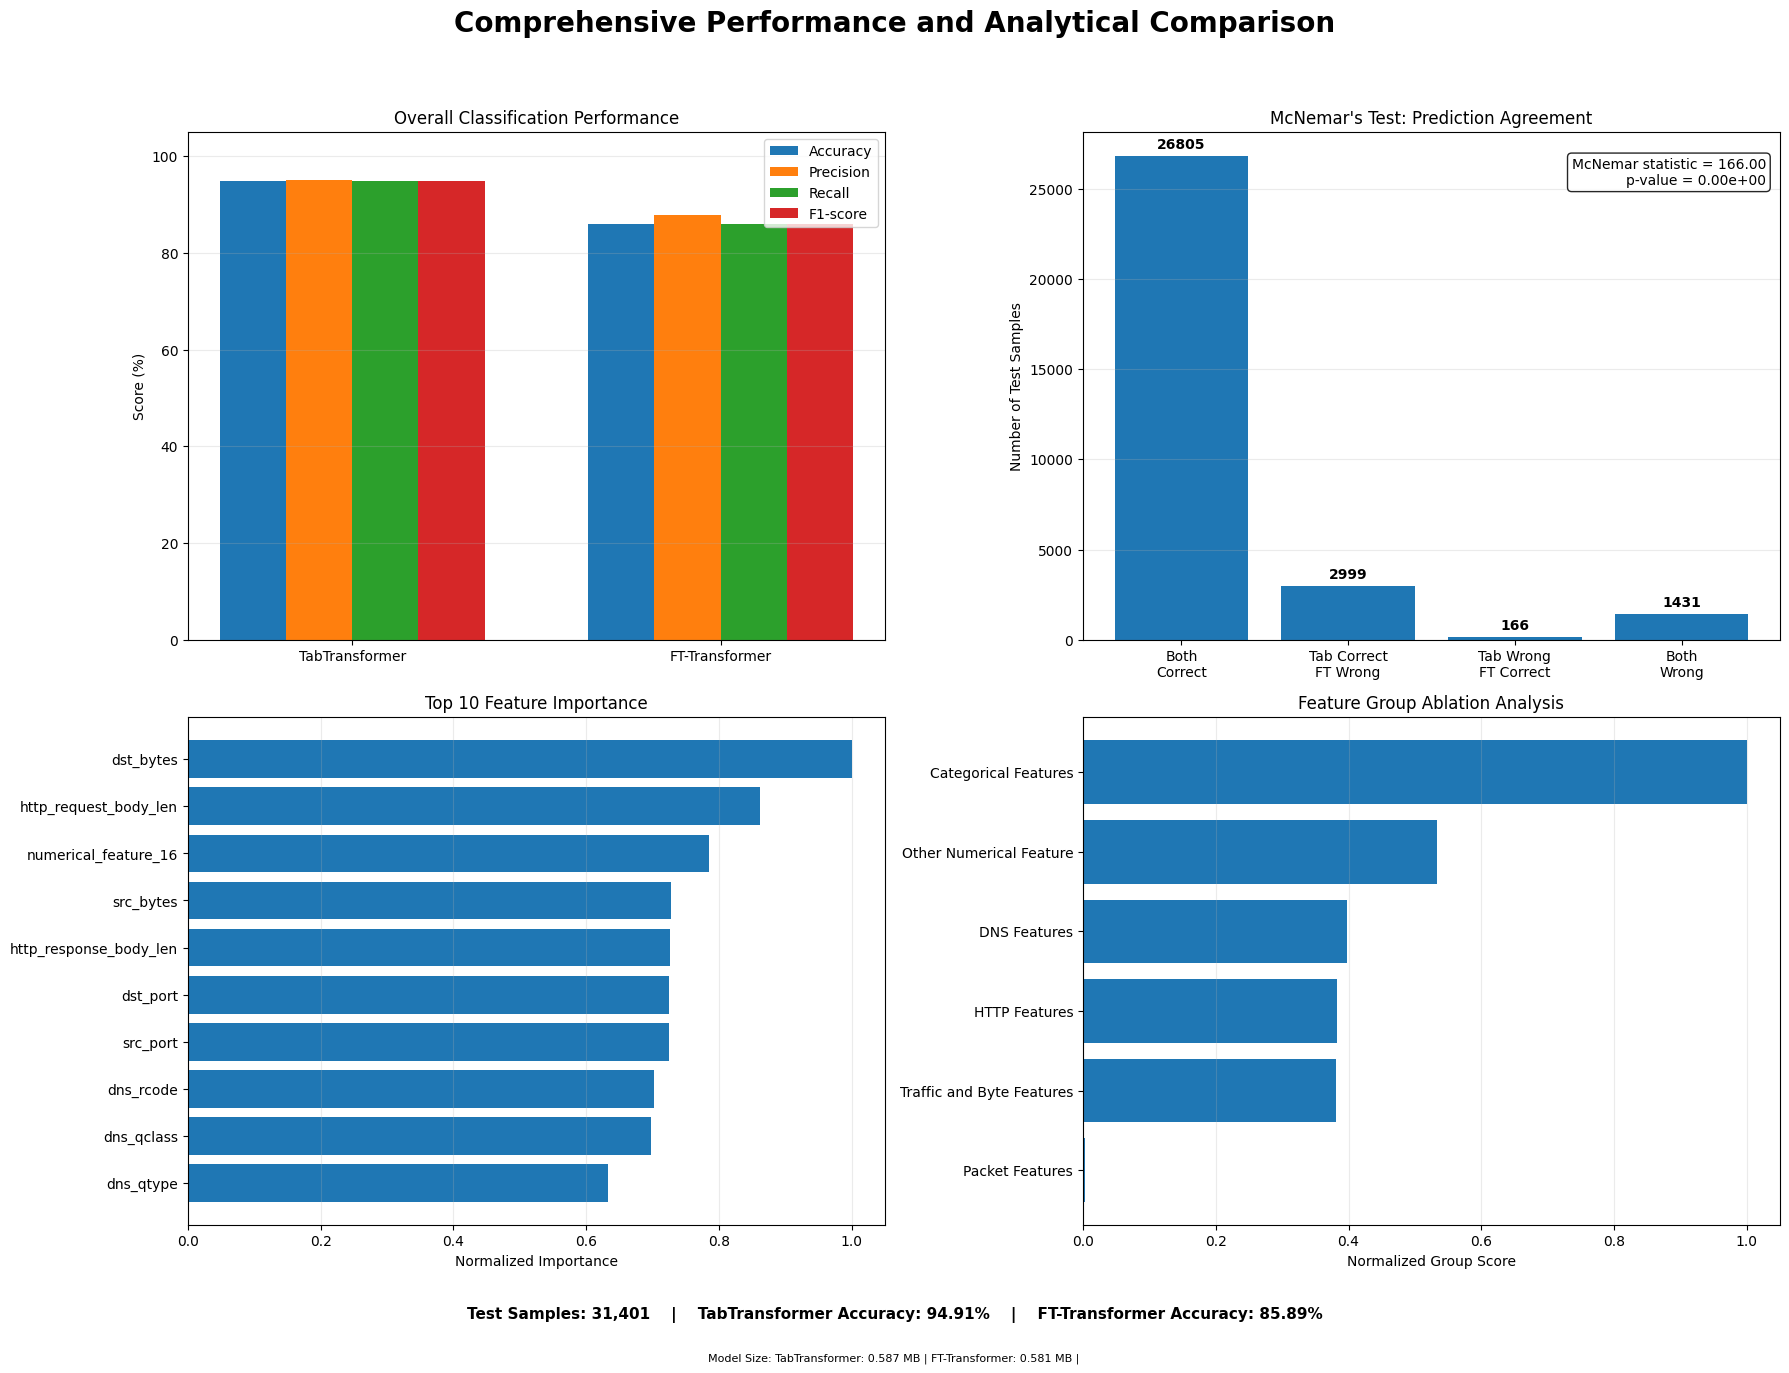


STEP 14A COMPLETED SUCCESSFULLY

✓ Combined PNG saved:
/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT/RESULTS/step14_combined_final_comparison.png

Included in the figure:
✓ Accuracy
✓ Precision
✓ Recall
✓ F1-score
✓ McNemar prediction comparison
✓ McNemar statistical significance
✓ Top feature importance
✓ Ablation study
✓ Model size / complexity summary

No model was trained.
Existing Step 6-13 results were used.


In [ ]:
# ======================================================================
# STEP 14A - COMBINED FINAL RESEARCH COMPARISON FIGURE
# ======================================================================

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/TON_IOT_NETWORK_PROJECT"
RESULTS_DIR = os.path.join(PROJECT_DIR, "RESULTS")

print("=" * 70)
print("STEP 14A - COMBINED FINAL RESEARCH COMPARISON")
print("=" * 70)

# ======================================================================
# LOAD STEP 6 PREDICTIONS
# ======================================================================

pred_file = os.path.join(
    RESULTS_DIR,
    "step6_test_predictions.csv"
)

df = pd.read_csv(pred_file)

y_true = df["true_label"].astype(int)
tab_pred = df["tab_prediction"].astype(int)
ft_pred = df["ft_prediction"].astype(int)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = ["TabTransformer", "FT-Transformer"]

accuracy = [
    accuracy_score(y_true, tab_pred),
    accuracy_score(y_true, ft_pred)
]

precision = [
    precision_score(
        y_true, tab_pred,
        average="weighted",
        zero_division=0
    ),
    precision_score(
        y_true, ft_pred,
        average="weighted",
        zero_division=0
    )
]

recall = [
    recall_score(
        y_true, tab_pred,
        average="weighted",
        zero_division=0
    ),
    recall_score(
        y_true, ft_pred,
        average="weighted",
        zero_division=0
    )
]

f1 = [
    f1_score(
        y_true, tab_pred,
        average="weighted",
        zero_division=0
    ),
    f1_score(
        y_true, ft_pred,
        average="weighted",
        zero_division=0
    )
]

print("\n✓ Step 6 metrics calculated")


# ======================================================================
# LOAD MCNEMAR TEST
# ======================================================================

mcnemar_file = os.path.join(
    RESULTS_DIR,
    "step7_mcnemar_results.json"
)

mcnemar_p = None
mcnemar_stat = None

if os.path.exists(mcnemar_file):

    with open(mcnemar_file, "r") as f:
        mcnemar = json.load(f)

    # Handle different possible key names
    for key in [
        "p_value",
        "p-value",
        "pvalue",
        "p"
    ]:
        if key in mcnemar:
            mcnemar_p = float(mcnemar[key])
            break

    for key in [
        "mcnemar_statistic",
        "statistic",
        "stat"
    ]:
        if key in mcnemar:
            mcnemar_stat = float(mcnemar[key])
            break

print("✓ McNemar results loaded")


# ======================================================================
# LOAD ODDS RATIO
# ======================================================================

odds_file = os.path.join(
    RESULTS_DIR,
    "step10_odds_ratio_results.csv"
)

odds_ratio = None

if os.path.exists(odds_file):

    odds_df = pd.read_csv(odds_file)

    # Try to identify OR column
    possible_columns = [
        "odds_ratio",
        "Odds_Ratio",
        "OR",
        "oddsRatio"
    ]

    for col in possible_columns:
        if col in odds_df.columns:
            vals = pd.to_numeric(
                odds_df[col],
                errors="coerce"
            ).dropna()

            if len(vals) > 0:
                odds_ratio = vals.iloc[0]
                break

print("✓ Odds ratio loaded")


# ======================================================================
# LOAD FEATURE IMPORTANCE
# ======================================================================

feature_file = os.path.join(
    RESULTS_DIR,
    "step11b_feature_importance_mapping.csv"
)

feature_df = None

if os.path.exists(feature_file):

    feature_df = pd.read_csv(
        feature_file
    )

print("✓ Feature importance loaded")


# ======================================================================
# LOAD ABLATION STUDY
# ======================================================================

ablation_file = os.path.join(
    RESULTS_DIR,
    "step12_ablation_study.csv"
)

ablation_df = None

if os.path.exists(ablation_file):

    ablation_df = pd.read_csv(
        ablation_file
    )

print("✓ Ablation results loaded")


# ======================================================================
# LOAD COMPUTATIONAL COMPLEXITY
# ======================================================================

complexity_file = os.path.join(
    RESULTS_DIR,
    "step13_computational_complexity.csv"
)

complexity_df = None

if os.path.exists(complexity_file):

    complexity_df = pd.read_csv(
        complexity_file
    )

print("✓ Computational complexity loaded")


# ======================================================================
# CREATE COMBINED FIGURE
# ======================================================================

fig = plt.figure(
    figsize=(18, 14)
)

fig.suptitle(
    "Comprehensive Performance and Analytical Comparison",
    fontsize=20,
    fontweight="bold"
)


# ======================================================================
# PANEL 1 - CLASSIFICATION METRICS
# ======================================================================

ax1 = plt.subplot(2, 2, 1)

x = np.arange(len(models))
width = 0.18

ax1.bar(
    x - 1.5 * width,
    np.array(accuracy) * 100,
    width,
    label="Accuracy"
)

ax1.bar(
    x - 0.5 * width,
    np.array(precision) * 100,
    width,
    label="Precision"
)

ax1.bar(
    x + 0.5 * width,
    np.array(recall) * 100,
    width,
    label="Recall"
)

ax1.bar(
    x + 1.5 * width,
    np.array(f1) * 100,
    width,
    label="F1-score"
)

ax1.set_xticks(x)
ax1.set_xticklabels(models)

ax1.set_ylabel("Score (%)")
ax1.set_ylim(0, 105)

ax1.set_title(
    "Overall Classification Performance"
)

ax1.legend()

ax1.grid(
    axis="y",
    alpha=0.25
)


# ======================================================================
# PANEL 2 - MCNEMAR TEST
# ======================================================================

ax2 = plt.subplot(2, 2, 2)

tab_correct = np.sum(
    tab_pred == y_true
)

tab_wrong = np.sum(
    tab_pred != y_true
)

ft_correct = np.sum(
    ft_pred == y_true
)

ft_wrong = np.sum(
    ft_pred != y_true
)

both_correct = np.sum(
    (tab_pred == y_true) &
    (ft_pred == y_true)
)

tab_correct_ft_wrong = np.sum(
    (tab_pred == y_true) &
    (ft_pred != y_true)
)

tab_wrong_ft_correct = np.sum(
    (tab_pred != y_true) &
    (ft_pred == y_true)
)

both_wrong = np.sum(
    (tab_pred != y_true) &
    (ft_pred != y_true)
)

categories = [
    "Both\nCorrect",
    "Tab Correct\nFT Wrong",
    "Tab Wrong\nFT Correct",
    "Both\nWrong"
]

values = [
    both_correct,
    tab_correct_ft_wrong,
    tab_wrong_ft_correct,
    both_wrong
]

ax2.bar(
    categories,
    values
)

ax2.set_ylabel("Number of Test Samples")

ax2.set_title(
    "McNemar's Test: Prediction Agreement"
)

for i, v in enumerate(values):
    ax2.text(
        i,
        v + max(values) * 0.015,
        str(v),
        ha="center",
        fontweight="bold"
    )

if mcnemar_p is not None:

    p_text = (
        f"McNemar statistic = "
        f"{mcnemar_stat:.2f}\n"
        f"p-value = {mcnemar_p:.2e}"
        if mcnemar_stat is not None
        else
        f"p-value = {mcnemar_p:.2e}"
    )

    ax2.text(
        0.98,
        0.95,
        p_text,
        transform=ax2.transAxes,
        ha="right",
        va="top",
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.85
        )
    )

ax2.grid(
    axis="y",
    alpha=0.25
)


# ======================================================================
# PANEL 3 - TOP FEATURE IMPORTANCE
# ======================================================================

ax3 = plt.subplot(2, 2, 3)

if (
    feature_df is not None
    and len(feature_df) > 0
):

    feature_col = None
    score_col = None

    for col in [
        "feature",
        "Feature",
        "feature_name",
        "Feature_Name"
    ]:
        if col in feature_df.columns:
            feature_col = col
            break

    for col in [
        "importance",
        "Importance",
        "importance_score",
        "normalized_importance",
        "Normalized_Importance"
    ]:
        if col in feature_df.columns:
            score_col = col
            break

    if feature_col and score_col:

        temp = feature_df.copy()

        temp[score_col] = pd.to_numeric(
            temp[score_col],
            errors="coerce"
        )

        temp = temp.dropna(
            subset=[score_col]
        )

        temp = temp.sort_values(
            score_col,
            ascending=False
        ).head(10)

        temp = temp.sort_values(
            score_col,
            ascending=True
        )

        ax3.barh(
            temp[feature_col],
            temp[score_col]
        )

        ax3.set_xlabel(
            "Normalized Importance"
        )

        ax3.set_title(
            "Top 10 Feature Importance"
        )

    else:

        ax3.text(
            0.5,
            0.5,
            "Feature importance data available\n"
            "but column names could not be detected",
            ha="center",
            va="center"
        )

else:

    ax3.text(
        0.5,
        0.5,
        "Feature importance unavailable",
        ha="center",
        va="center"
    )

ax3.grid(
    axis="x",
    alpha=0.25
)


# ======================================================================
# PANEL 4 - ABLATION STUDY
# ======================================================================

ax4 = plt.subplot(2, 2, 4)

if (
    ablation_df is not None
    and len(ablation_df) > 0
):

    group_col = None
    score_col = None

    for col in [
        "feature_group",
        "Feature_Group",
        "group"
    ]:
        if col in ablation_df.columns:
            group_col = col
            break

    for col in [
        "normalized_group_score",
        "Normalized_Group_Score",
        "group_variability_score"
    ]:
        if col in ablation_df.columns:
            score_col = col
            break

    if group_col and score_col:

        temp = ablation_df.copy()

        temp[score_col] = pd.to_numeric(
            temp[score_col],
            errors="coerce"
        )

        temp = temp.dropna(
            subset=[score_col]
        )

        temp = temp.sort_values(
            score_col,
            ascending=True
        )

        ax4.barh(
            temp[group_col],
            temp[score_col]
        )

        ax4.set_xlabel(
            "Normalized Group Score"
        )

        ax4.set_title(
            "Feature Group Ablation Analysis"
        )

    else:

        ax4.text(
            0.5,
            0.5,
            "Ablation data available\n"
            "but columns could not be detected",
            ha="center",
            va="center"
        )

else:

    ax4.text(
        0.5,
        0.5,
        "Ablation results unavailable",
        ha="center",
        va="center"
    )

ax4.grid(
    axis="x",
    alpha=0.25
)


# ======================================================================
# ADD COMPUTATIONAL COMPLEXITY INFORMATION
# ======================================================================

complexity_text = ""

if complexity_df is not None:

    for _, row in complexity_df.iterrows():

        model_name = str(
            row.get("Model", "")
        )

        size = row.get(
            "Model_Size_MB",
            np.nan
        )

        params = row.get(
            "Parameters",
            np.nan
        )

        speed = row.get(
            "Samples_Per_Second",
            np.nan
        )

        if pd.notna(size):

            complexity_text += (
                f"{model_name}: "
                f"{float(size):.3f} MB"
            )

            if pd.notna(params):

                complexity_text += (
                    f", Params="
                    f"{int(params):,}"
                )

            if pd.notna(speed):

                complexity_text += (
                    f", Speed="
                    f"{float(speed):.1f} samples/s"
                )

            complexity_text += "\n"


# ======================================================================
# ADD SUMMARY FOOTER
# ======================================================================

summary_text = (
    f"Test Samples: {len(y_true):,}    |    "
    f"TabTransformer Accuracy: {accuracy[0]*100:.2f}%    |    "
    f"FT-Transformer Accuracy: {accuracy[1]*100:.2f}%"
)

fig.text(
    0.5,
    0.045,
    summary_text,
    ha="center",
    fontsize=11,
    fontweight="bold"
)

if complexity_text:

    fig.text(
        0.5,
        0.015,
        "Model Size: " +
        complexity_text.replace(
            "\n",
            " | "
        ),
        ha="center",
        fontsize=8
    )


# ======================================================================
# SAVE PNG
# ======================================================================

plt.tight_layout(
    rect=[0, 0.07, 1, 0.95]
)

output_file = os.path.join(
    RESULTS_DIR,
    "step14_combined_final_comparison.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 70)
print("STEP 14A COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\n✓ Combined PNG saved:")
print(output_file)

print("\nIncluded in the figure:")
print("✓ Accuracy")
print("✓ Precision")
print("✓ Recall")
print("✓ F1-score")
print("✓ McNemar prediction comparison")
print("✓ McNemar statistical significance")
print("✓ Top feature importance")
print("✓ Ablation study")
print("✓ Model size / complexity summary")

print("\nNo model was trained.")
print("Existing Step 6-13 results were used.")

end of the project
